# Phase Equilibria of CO$_2$ and CH$_4$ in Multisalt Brines: Parametrization and Validation of an Ion-Specific Electrolyte Cubic-Plus-Association Equation of State

**Executable paper notebook**: the full text of the journal article and its Supporting
Information, with code cells that regenerate every figure and table.

J. Moortgat, F. Mourão Coelho, A. Firoozabadi. *Energy & Fuels* **2026**, 40 (42),
23472–23484. [doi:10.1021/acs.energyfuels.6c04568](https://doi.org/10.1021/acs.energyfuels.6c04568)
([article page](https://pubs.acs.org/enfuem/article/40/42/23472/5449187/Phase-Equilibria-of-CO2-and-CH4-in-Multisalt))

The article is published open access under the
[Creative Commons Attribution 4.0 license](https://creativecommons.org/licenses/by/4.0/).
The text below is reproduced under that license. The equation-of-state code is in
[`multisalt/`](../multisalt/README.md) of this repository; the experimental data are
GasBrineBench v1.1.1 ([doi:10.5281/zenodo.22898153](https://doi.org/10.5281/zenodo.22898153)).

**How to use.** Run the setup cell first. Each figure and table has a hidden code cell
above its caption. By default the cells draw the figures and tables from the model
results shipped with the repository (about one minute). Set `nbtools.RUN_LONG = True`
in the setup cell to recompute every model result from the equation of state: about
15 minutes with the compiled Fortran library (`make -C multisalt/fortran`), several
hours in pure Python.


## Contents

- [Article](#mtop)
  - [Abstract](#mabstract)
  - [1 Introduction](#msec1)
  - [2 Methods](#msec2)
    - [2.1 Residual Helmholtz decomposition](#msec2_1)
    - [2.2 Debye–Hückel, Born, and permittivity terms](#msec2_2)
    - [2.3 Volume translation](#msec2_3)
    - [2.4 Summary of the parameter set](#msec2_4)
    - [2.5 Calibration data](#msec2_5)
    - [2.6 Equilibrium computations](#msec2_6)
  - [3 Results and Validation](#msec3)
    - [3.1 Brine density](#msec3_1)
    - [3.2 Osmotic coefficients of the brines](#msec3_2)
    - [3.3 CH<sub>4</sub>–H<sub>2</sub>O and CO<sub>2</sub>–H<sub>2</sub>O binaries](#msec3_3)
    - [3.4 CO<sub>2</sub> solubility in single-salt brines](#msec3_4)
    - [3.5 CH<sub>4</sub> solubility in single-salt brines](#msec3_5)
    - [3.6 Mixed-salt brines](#msec3_6)
    - [3.7 Enthalpy of CO<sub>2</sub> dissolution: a calorimetric consistency check](#msec3_7)
  - [4 Conclusions](#msec4)
- [Supporting Information](#stop)
  - [S1 Parameter hierarchy of the model](#ssecS1)
  - [S2 Nomenclature](#ssecS2)
    - [S2.1 State variables, composition, Helmholtz contributions, and physical constants](#ssecS2_1)
    - [S2.2 Cubic-EoS, volume-translation, and Wertheim association parameters](#ssecS2_2)
    - [S2.3 Electrostatic, Born, permittivity, and NRTL ion-interaction parameters](#ssecS2_3)
  - [S3 Full eCPA Helmholtz term derivations and <i>Z</i>, ln φ̂ decompositions](#ssecS3)
    - [S3.1 Compressibility-factor decomposition](#ssecS3_1)
    - [S3.2 Fugacity-coefficient decomposition](#ssecS3_2)
  - [S4 Permittivity model: Kirkwood <i>g</i>-factor and derivatives](#ssecS4)
    - [S4.1 Volume and composition derivatives](#ssecS4_1)
  - [S5 Péneloux volume translation: ion-by-ion residuals and fitting protocol](#ssecS5)
  - [S6 Ion–solvent, ion–gas, and Péneloux volume-translation parameters](#ssecS6)
  - [S7 Calibration data inventory](#ssecS7)
    - [S7.1 Data collection, screening, and inter-source reproducibility](#ssecS7_1)
  - [S8 Ion-parameter provenance and the Ca<sup>2+</sup> correction](#ssecS8)
    - [S8.1 Provenance of the ion parameters](#ssecS8_1)
    - [S8.2 Colligative verification](#ssecS8_2)
    - [S8.3 The Ca<sup>2+</sup> correction](#ssecS8_3)
    - [S8.4 The Mg<sup>2+</sup> polarizability](#ssecS8_4)
    - [S8.5 K<sup>+</sup> refinement and the Na<sub>2</sub>SO<sub>4</sub> limitation](#ssecS8_5)
  - [S9 Expanded validation](#ssecS9)
    - [S9.1 Brine density isotherms](#ssecS9_1)
    - [S9.2 CO<sub>2</sub> solubility in single-salt brines](#ssecS9_2)
    - [S9.3 CH<sub>4</sub> solubility in single-salt brines](#ssecS9_3)
    - [S9.4 Mixed-salt brines](#ssecS9_4)
    - [S9.5 Henry’s-constant figures](#ssecS9_5)
    - [S9.6 Predicted CH<sub>4</sub> and CO<sub>2</sub>–CH<sub>4</sub> behavior in mixed-brine recipes](#ssecS9_6)

In [1]:
# Setup: run this cell first (locally or on Google Colab).
import os, sys, subprocess

if "google.colab" in sys.modules and not os.path.exists("CPA_and_eCPA_flash"):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/jmoortgat/CPA_and_eCPA_flash.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "CoolProp"], check=True)

# work from the multisalt/ directory of the repository
for cand in ("CPA_and_eCPA_flash/multisalt", "../multisalt", "multisalt", "."):
    if os.path.exists(os.path.join(cand, "ms_ecpa", "parameters.py")):
        os.chdir(cand)
        break
sys.path[:0] = [os.getcwd(), os.path.join(os.getcwd(), "scripts")]

import nbtools
from nbtools import run, show, latex_table, show_table

# False: draw the figures and tables from the model results shipped in
# results_cache/.  True: recompute them from the equation of state (about
# 15 min with the Fortran library, several hours in pure Python).
nbtools.RUN_LONG = False

# use the compiled Fortran library when it has been built (make -C fortran)
built = os.listdir("fortran/build") if os.path.isdir("fortran/build") else []
if any(f.startswith("libecpa") for f in built):
    os.environ.setdefault("MS_ECPA_BACKEND", "fortran")
print("working directory:", os.path.basename(os.getcwd()) + "/",
      "| backend:", os.environ.get("MS_ECPA_BACKEND", "python"),
      "| RUN_LONG:", nbtools.RUN_LONG)


working directory: multisalt/ | backend: fortran | RUN_LONG: False


<a id="mtop"></a>

# Article

Joachim Moortgat (School of Earth Sciences, The Ohio State University, Columbus, OH, USA), Felipe Mourão Coelho (Université Grenoble Alpes, LIPhy, Grenoble, France), Abbas Firoozabadi (Rice University, Houston, TX, USA)

<a id="mabstract"></a>

## Abstract

We present an ion-specific parameterization of the electrolyte Cubic-Plus-Association (eCPA) equation of state, which we refer to as ms-eCPA, for phase equilibria of $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$ in multi-salt aqueous brines containing $\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$, $\mathrm{K^{+}}$, $\mathrm{Ca^{2+}}$, $\mathrm{Mg^{2+}}$, and $\mathrm{SO_{4}^{2-}}$. The model includes a Soave–Redlich–Kwong physical term with a Huron–Vidal mixing rule, Wertheim 4C association of water with $\mathrm{CO_{2}}$ cross-association, and Debye–Hückel plus Born electrostatic contributions on an ionic basis; the static permittivity is closed self-consistently through the Onsager–Kirkwood relation. The parameterization is hierarchical — each level of added physical description (nonpolar fluids, the associating solvent, ions in the solvent, gases over brine) introduces only parameters fitted to that level’s own data — with the top-level gas–ion interaction energies and ion volume translations calibrated against 1,931 experimental $\mathrm{CO_{2}}$–brine VLE points in five salts ($T = 283$–$473$ K, $P = 1.3$–$1200$ bar, $m_s = 0.09$–$6$ mol kg$^{-1}$), 581 $\mathrm{CH_{4}}$–brine points in six salts ($T = 298$–$598$ K, $P = 4$–$1379$ bar, $m_s = 0.25$–$6$ mol kg$^{-1}$), and 905 high-accuracy brine densities ($T = 283$–$473$ K, $P = 9$–$686$ bar). A colligative verification of the inherited ion parameters against the Pitzer osmotic-coefficient standard uncovers, and corrects, two defects in the published ion set (the $\mathrm{Ca^{2+}}$ parameters and the $\mathrm{Mg^{2+}}$ polarizability). Across the parameterized range, at salt molalities to $6$ mol kg$^{-1}$, the model predicts $\mathrm{CO_{2}}$ solubility to within 4.3–11.1% AARE per salt and $\mathrm{CH_{4}}$ solubility within 1.6–10.2% AARE per salt, reproduces brine density across the full salinity and temperature range through a temperature-dependent ion-specific Péneloux volume translation with a single ion-additive coefficient set, predicts $\mathrm{CO_{2}}$ solubility in mixed-salt brines with no mixed-brine tuning, and predicts measured calorimetric enthalpies of $\mathrm{CO_{2}}$ dissolution in water and $\mathrm{NaCl}$ brines to 0.6 kJ mol$^{-1}$ with no adjusted parameters. The parameterization provides the thermodynamic basis for subsurface $\mathrm{CO_{2}}$ sequestration and $\mathrm{CH_{4}}$ production in realistic formation brines. In a separate study, the model is paired with robust two- and three-phase stability and flash computations and extended to $\mathrm{N_{2}}$, $\mathrm{H_{2}}$, $\mathrm{C_{2}H_{6}}$, $\mathrm{C_{3}H_{8}}$, and $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ gas mixtures.


## Keywords

electrolyte equation of state, eCPA, ion-specific parameterization, $\mathrm{CO_{2}}$ sequestration, methane in brine, multi-salt phase equilibria


<a id="msec1"></a>

## 1 Introduction

Reliable thermodynamic models of $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$ in aqueous brines are central to several large-scale subsurface applications: geological storage of $\mathrm{CO_{2}}$ in saline aquifers and depleted hydrocarbon reservoirs<sup>[1](#mref1)–[3](#mref3)</sup>, the production of natural-gas reservoirs in contact with formation water<sup>[4](#mref4)</sup>, and the emerging storage of $\mathrm{H_{2}}$ in salt caverns and brine-bearing porous formations<sup>[5](#mref5),[6](#mref6)</sup>. In all of these settings the aqueous phase is not a simple $\mathrm{NaCl}$ solution: deep formation brines typically contain mixtures of $\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$, $\mathrm{K^{+}}$, $\mathrm{Ca^{2+}}$, $\mathrm{Mg^{2+}}$, and $\mathrm{SO_{4}^{2-}}$, often at total ionic strengths several mol kg$^{-1}$ and over a wide temperature and pressure window, and where $\mathrm{CO_{2}}$-charged brine reacts with carbonate rock that composition evolves in situ as well<sup>[7](#mref7)</sup>. Salting-out effects, dielectric depression of the solvent, and ion-specific solvation each modify volatile species solubility and brine density, so a thermodynamic model that captures all three on a single self-consistent basis is desirable.

Cubic-plus-association (CPA) equations of state<sup>[8](#mref8)</sup> combine a cubic backbone with the Wertheim association term<sup>[9](#mref9)</sup> and have been used extensively for hydrogen-bonding systems. The cubic part is commonly the Soave–Redlich–Kwong (SRK) equation, as in this work, but other cubics serve equally well: a Peng–Robinson-based CPA with association and cross-association terms has been applied to water–$\mathrm{CO_{2}}$–hydrocarbon mixtures from reservoir to hydrothermal conditions<sup>[6](#mref6),[10](#mref10)–[12](#mref12)</sup>. Cross-association between $\mathrm{CO_{2}}$ and $\mathrm{H_{2}O}$<sup>[10](#mref10)–[12](#mref12)</sup> markedly improves the description of the $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ binary up to hydrothermal conditions and has been embedded in compositional reservoir simulators to model $\mathrm{CO_{2}}$-water and $\mathrm{CO_{2}}$-brine flow with mass exchange between the resident and injected phases<sup>[4](#mref4),[13](#mref13)</sup>. The electrolyte extension, eCPA<sup>[14](#mref14)</sup>, adds Debye–Hückel and Born electrostatic contributions and treats the static permittivity through the Onsager–Kirkwood self-consistent relation<sup>[15](#mref15)</sup>. Kontogeorgis et al.<sup>[16](#mref16)</sup> review the various flavors of electrolyte CPA and emphasize the practical advantages of an ion-specific (rather than salt-specific) parameterization for multi-salt brines.

Recent work in our group has focused on extending eCPA to subsurface gas–brine systems. Coelho et al.<sup>[17](#mref17)</sup> parameterized eCPA for the $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$–$\mathrm{NaCl}$ ternary with temperature-dependent binary interaction parameters and cross-association, reducing the $\mathrm{CO_{2}}$-in-brine solubility error by roughly a factor of four relative to the original Maribo-Mogensen et al.<sup>[14](#mref14)</sup> parameter set. In a follow-up by Coelho et al.<sup>[5](#mref5)</sup>, the same framework was re-parameterized for $\mathrm{H_{2}}$ and $\mathrm{H_{2}}$–$\mathrm{CO_{2}}$ mixtures in $\mathrm{NaCl}$ brine and benchmarked against new $\mathrm{H_{2}}$ solubility data. A companion algorithmic study<sup>[18](#mref18)</sup> introduced fast, robust phase stability and flash routines, a three-dimensional warm-start solution table, and a prototype reservoir simulator, all built on the same $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$–$\mathrm{NaCl}$ parameterization. Across these three contributions the parameter calibration has been restricted to $\mathrm{NaCl}$ brine.

The necessary parameter set in the model may be read as a hierarchy of increasingly complex fluid descriptions, in which each level introduces a small number of parameters regressed to data characteristic of that level alone, with all lower levels held fixed. Each lower level is held at its published or previously determined values, and parameters belonging to different levels were never co-optimized; within a level they were fitted together against that level’s own data, so an ion shared between salts carries a single value determined by every brine that contains it, and no parameter is specific to a salt or fitted to mixed-salt or mixed-gas data. The base level contains the nonpolar fluids. A pure nonpolar species such as $\mathrm{CH_{4}}$ requires only its critical temperature $T_{c,i}$, critical pressure $P_{c,i}$, and acentric factor $\omega_i$: the SRK energy and co-volume constants follow from $T_{c,i}$ and $P_{c,i}$, and $\omega_i$ sets the temperature dependence of the energy parameter through the Soave correlation, anchored to pure-component vapor pressure. (For the quadrupolar $\mathrm{CO_{2}}$ the three SRK constants are instead regressed directly to vapor-pressure and liquid-density data<sup>[19](#mref19)</sup>.) A volume translation is added only where liquid density matters and leaves phase equilibrium untouched; none is applied to the fluids at this level in this work. Mixtures of such fluids require one constant binary interaction parameter per pair — here the single constant $k_{hc}$ for $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ — for which a single equilibrium datum per pair suffices in principle.

Water, a polar and self-associating solvent, occupies the second level. Its description adds the association energy and volume parameters of the 4C hydrogen-bonding scheme, regressed together with the water SRK constants to pure-water vapor pressure and liquid density<sup>[19](#mref19)</sup>. Interactions between water and the volatile species are no longer captured by a constant: the binary parameters $k_{hw}(T)$ and $k_{cw}(T)$ acquire a quadratic temperature dependence fitted to the respective gas–water binary VLE data. A solvating species such as $\mathrm{CO_{2}}$ introduces no association sites of its own: its cross-association with water is taken proportional to the water self-association strength, and only the temperature-dependent proportionality ratio $S_{cw}(T)$ is fitted, to the same $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ binary data<sup>[17](#mref17)</sup>.

Dissolving salts in the polar solvent defines the third level, and each new parameter at this level is a property of an individual ion rather than of a salt. Every ion contributes a hard-sphere diameter $\sigma_i$, which sets the distance of closest approach in the Debye–Hückel term and simultaneously fixes the ion co-volume $b_i = \tfrac{2}{3}\pi N_A \sigma_i^3$, so that $b_i$ is not an independent parameter; a Born radius $R_{B,i}$, which controls the ion–solvent transfer (solvation) energy; a temperature-independent dispersion energy $a_{0,i}$; a polarizability $\alpha_{0,i}$; and a temperature-dependent water–ion interaction energy $\Delta U_{wi}(T)$. Ion–ion interactions require no dedicated parameters: they are mediated by the Debye–Hückel term through the static permittivity of the solvent, closed self-consistently by the Onsager–Kirkwood relation, whose remaining inputs (the water dipole moment and hydrogen-bond geometry) are fixed by pure-water and electrolyte permittivity data<sup>[15](#mref15)</sup>. Because the ions are nonvolatile and confined to the aqueous phase, the vapor phase remains as simple as at the second level. Where brine density matters, each ion also carries a temperature-dependent Péneloux volume translation $\Upsilon_i(T)$, fitted to brine-density data and, being isofugacity-preserving, without effect on phase equilibrium. The ion parameters of this level carry no gas information, so colligative data validate them independently of everything above: the osmotic coefficient — equivalently, the vapor-pressure lowering — of the gas-free brines is the discriminating benchmark for this level, and Section 3.2 carries out that test.

Volatile species over brine complete the hierarchy. In the following, we will refer to volatile species (e.g., $\mathrm{CO_{2}}$, $\mathrm{CH_{4}}$, $\mathrm{N_{2}}$, $\mathrm{H_{2}}$) simply as ‘gases’, also when dissolved in the aqueous phase. The ion-specific salting-out of each gas is captured by one temperature-dependent gas–ion interaction energy per pair, $\Delta U_{ci}(T)$ for $\mathrm{CO_{2}}$ and $\Delta U_{hi}(T)$ for $\mathrm{CH_{4}}$, fitted to gas-in-brine solubility data with all lower levels held fixed. Additional gases add no structural complexity: each brings its own pure-component constants, gas–water binary parameters, and gas–ion pairs, so mixed-gas and mixed-salt equilibria follow as predictions with no further parameters. Table S1 of the Supporting Information summarizes the hierarchy, the data that fix each level, and where each level is validated — in this paper or in the companion algorithmic study of Moortgat et al.<sup>[20](#mref20)</sup>.

We extend the eCPA framework along two complementary axes that are needed for subsurface applications. First, we include $\mathrm{CH_{4}}$ alongside $\mathrm{CO_{2}}$ as a volatile component, to apply the same model to natural-gas reservoirs, biogenic methane plumes accompanying $\mathrm{CO_{2}}$ injection, and $\mathrm{CO_{2}}$–$\mathrm{CH_{4}}$ mixed-gas storage. Second, we adopt an ion-specific parameterization for a broad subsurface-relevant ion suite $\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$, $\mathrm{K^{+}}$, $\mathrm{Ca^{2+}}$, $\mathrm{Mg^{2+}}$, $\mathrm{SO_{4}^{2-}}$, so that mixed-salt brines are described without ad-hoc mixing rules. In terms of this hierarchy, the first two levels and the ion parameters of the third are from prior eCPA work<sup>[15](#mref15),[17](#mref17),[19](#mref19),[21](#mref21)</sup>, with two corrections established here and with the $\mathrm{CH_{4}}$-related binary coefficients fitted here; the ion-specific volume translations and the entire fourth level — one temperature-dependent interaction energy per gas–ion pair — are fitted to experimental gas-in-brine VLE and brine density data.

The specific contributions of this work are:

1.  An ion-specific eCPA for the $\mathrm{H_{2}O}$–$\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–($\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$, $\mathrm{K^{+}}$, $\mathrm{Ca^{2+}}$, $\mathrm{Mg^{2+}}$, $\mathrm{SO_{4}^{2-}}$) system, with temperature-dependent gas–water binary interaction parameters and ion-specific NRTL-type ion–gas interaction parameters.

2.  Temperature-dependent ion-specific Péneloux volume shifts fitted to high-accuracy brine densities of Al Ghafri et al.<sup>[22](#mref22),[23](#mref23)</sup>, yielding a single set of coefficients for five salts and their mixtures.

3.  A colligative verification of the inherited ion parameters against the Pitzer osmotic-coefficient standard, which uncovers and corrects two defects in the published ion set: the $\mathrm{Ca^{2+}}$ hard-sphere diameter and Born radius, and the $\mathrm{Mg^{2+}}$ polarizability.

4.  Systematic validation against 2,512 experimental single-salt gas–brine VLE points (1,931 for $\mathrm{CO_{2}}$, 581 for $\mathrm{CH_{4}}$) covering $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$ in $\mathrm{NaCl}$, $\mathrm{KCl}$, $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$, $\mathrm{Na_{2}SO_{4}}$, and $\mathrm{MgSO_{4}}$ brines, together with 314 mixed-brine $\mathrm{CO_{2}}$ solubilities predicted with no mixed-brine tuning.

5.  A parameter-free calorimetric test of the model’s temperature derivatives: the measured enthalpies of $\mathrm{CO_{2}}$ dissolution in water and 1 and 3 mol kg$^{-1}$ $\mathrm{NaCl}$ at 323–373 K and 2–20 MPa are predicted to 0.6 kJ mol$^{-1}$ on average, within or near the experimental uncertainty.

The computational algorithms that run on the parameterization presented here are developed in a companion manuscript<sup>[20](#mref20)</sup> — a two-phase tangent-plane stability test and an accelerated $K$-value flash with Newton polish, tested over a dense grid of $\sim 150\thinspace 000$ conditions spanning the full calibration window, and a three-phase (vapor–brine–liquid) extension validated against the measured $\mathrm{CO_{2}}$ and $\mathrm{C_{3}H_{8}}$ three-phase loci — which also extends the framework to $\mathrm{N_{2}}$, $\mathrm{H_{2}}$, $\mathrm{C_{2}H_{6}}$, $\mathrm{C_{3}H_{8}}$, and $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ gas mixtures. Each paper is written to stand on its own.

We note that in this work we do not compare accuracy between ms-eCPA and published numbers for competing approaches because each is regressed against different properties and scored on different data under different screening rules. Such a comparison is meaningless. A like-for-like comparison of ms-eCPA with published alternatives, all scored on one common database under a single error metric, is the subject of a separate study in preparation.

The remainder of the paper is organized as follows. Section 2 summarizes the ms-eCPA framework, lists the pure-component, binary, and volume-translation parameters, and describes the calibration data. Section 3 validates the parameterization against experimental brine densities, osmotic coefficients, $\mathrm{CO_{2}}$–brine, $\mathrm{CH_{4}}$–brine, and mixed-brine VLE data, and calorimetric enthalpies of $\mathrm{CO_{2}}$ dissolution. Section 4 summarizes the results and outlines the extensions taken up in the companion study<sup>[20](#mref20)</sup>.


<a id="msec2"></a>

## 2 Methods

This section presents the model. We first set out the residual Helmholtz decomposition of ms-eCPA equation of state and its long-range electrostatic and volume-translation contributions (Sections 2.1–2.3), then summarize the parameter set and the calibration data (Sections 2.4–2.5), and close with a note on how the resulting equilibrium problem is solved at every state point (Section 2.6).


<a id="msec2_1"></a>

### 2.1 Residual Helmholtz decomposition

For an aqueous mixture containing $\mathrm{H_{2}O}$, the volatile components $\mathrm{CH_{4}}$ and $\mathrm{CO_{2}}$, and the ions $\lbrace \mathrm{Na^{+}}, \mathrm{Cl^{-}}, \mathrm{K^{+}}, \mathrm{Ca^{2+}}, \mathrm{Mg^{2+}}, \mathrm{SO_{4}^{2-}}\rbrace$, the residual Helmholtz energy per mole is written as the sum of a physical SRK contribution, a Wertheim association term, and Debye–Hückel and Born electrostatic contributions<sup>[14](#mref14),[17](#mref17)</sup>:

$$A^\text{R} = A^\text{phys} + A^\text{assoc} + A^\text{DH} + A^\text{Born}. \tag{1}$$

The physical (SRK) term takes the standard form

$$\frac{A^\text{phys}}{nRT} = -\ln\negthinspace \left(1-\frac{b}{v}\right) - \frac{a}{bRT}\ln\negthinspace \left(1+\frac{b}{v}\right), \tag{2}$$

with linear co-volume mixing $b = \sum_i x_i b_i$ and a Huron–Vidal $g^{E\infty}$ rule<sup>[17](#mref17)</sup> for $a/b$,

$$\frac{a}{b} = \sum_i x_i \frac{a_i}{b_i} - \frac{g^{E\infty}}{\ln 2}, \qquad g^{E\infty} = \frac{1}{b}\sum_j\sum_i x_i x_j b_j \Delta U_{ji}, \tag{3}$$

where the binary energy parameter is split into a Berthelot-like combining piece and an asymmetric correction,

$$\frac{\Delta U_{ji}}{\ln 2} = \frac{a_i}{b_i} - \frac{2\sqrt{a_i a_j}}{b_i + b_j}\left(1 - k_{ij}\right). \tag{4}$$

The pure-component temperature dependence is the Soave form $a_i(T) = a_{0,i}[1 + c_{1,i}(1-\sqrt{T/T_{c,i}})]^2$. For $\mathrm{CH_{4}}$, the reference constants $a_{0,i}$ and $b_i$ follow the standard SRK critical-property relations,

$$a_{0,i} = 0.42748\thinspace \frac{R^2T_{c,i}^2}{P_{c,i}}, \qquad b_i = 0.08664\thinspace \frac{RT_{c,i}}{P_{c,i}}, \tag{5}$$

using the critical temperature and pressure in Table 1; for water and $\mathrm{CO_{2}}$ the constants are instead regressed, as noted in Section 1 (Table 1). Ions have no physical critical point, so $b_i$ is instead obtained from the hard-sphere diameter $\sigma_i$ via the same close-packing relation that underlies the radial distribution function (Eq. (9) below),

$$b_i = \frac{2\pi}{3}N_A\sigma_i^3, \tag{6}$$

while the ionic $a_{0,i}$ is treated as an adjustable parameter adopted from Schlaikjer et al.<sup>[21](#mref21)</sup>, Maribo-Mogensen et al.<sup>[15](#mref15)</sup> rather than derived from a critical-property correlation.

The binary energy parameter $\Delta U_{ji}$ of Eq. (4) is needed in full only for pairs involving the polar $\mathrm{H_{2}O}$ or an ion, where the plain Berthelot combining rule is insufficient. For the two nonpolar volatile species ($\mathrm{CH_{4}}$, $\mathrm{CO_{2}}$), Eq. (4) reduces to ordinary van der Waals mixing with a single, temperature-independent binary parameter, $k_{hc} = 0.080$ (Table 2). The water–ion interaction energies $\Delta U_{wi}$ and the gas–ion interaction energies $\Delta U_{hi}$, $\Delta U_{ci}$ are tabulated in Table S3 of the Supporting Information (Section 2.4).

Association is described by the Wertheim term

$$\frac{A^\text{assoc}}{nRT} = \sum_i x_i \sum_{A \in i} \left(\ln \chi_{A_i} - \frac{\chi_{A_i}}{2} + \frac{1}{2}\right), \tag{7}$$

with the site bonding fraction

$$\chi_{A_i} = \frac{1}{1 + c\sum_j x_j \sum_{B \in j} \chi_{B_j}\thinspace \delta_{A_iB_j}}, \qquad \delta_{A_iB_j} = g_\eta\thinspace \kappa_{A_iB_j} \negthinspace \left[\exp\negthinspace \left(\frac{\varepsilon_{A_iB_j}}{k_BT}\right) - 1\right]. \tag{8}$$

Here $c = 1/v$ is the total molar concentration. Water uses the 4C scheme (two donor and two acceptor sites of equal strength). The $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ cross-association strength is taken proportional to water self-association, $\delta_{\mathrm{CO_2},\mathrm{H_2O}} = S_{\mathrm{CO_2},\mathrm{H_2O}}(T)\thinspace \delta_{\mathrm{H_2O}}$, with $S_{\mathrm{CO_2},\mathrm{H_2O}}(T)$ a quadratic polynomial in $T/T_{c,\mathrm{CO_2}}$<sup>[17](#mref17)</sup>; $\mathrm{CH_{4}}$ carries no association sites. Ions also carry no association sites.

The radial distribution function is the Maribo-Mogensen form used in Maribo-Mogensen et al.<sup>[14](#mref14)</sup>, Coelho et al.<sup>[17](#mref17)</sup>,

$$g_\eta = \frac{1}{1 - 1.9\eta}, \qquad \eta = \frac{b}{4v}. \tag{9}$$


<a id="msec2_2"></a>

### 2.2 Debye–Hückel, Born, and permittivity terms

Electrostatic contributions are evaluated using the Maribo-Mogensen primitive model<sup>[14](#mref14)</sup>: ions are treated as discrete charged hard spheres immersed in a structureless dielectric continuum, characterized only by the static relative permittivity $\varepsilon_r$, rather than resolving the solvent’s molecular dipoles explicitly as a “non-primitive” treatment would. The permittivity is not fixed a priori, however: it is computed self-consistently from the mixture’s association state and dipole moments via the Onsager–Kirkwood relation below (Eq. (13)), so the model retains explicit solvent-structure information despite the primitive electrostatic treatment. The Debye–Hückel contribution is

$$\frac{A^\text{DH}}{nRT} = -\frac{\sum_j x_j z_j^2 X_j}{4\pi N_A c \sum_j x_j z_j^2}, \qquad X_i = \frac{1}{\sigma_i^3}\negthinspace \left[ \ln(1 + \kappa\sigma_i) - \kappa\sigma_i + \frac{(\kappa\sigma_i)^2}{2} \right], \tag{10}$$

with the inverse Debye length $\kappa$ (unrelated to the association volume parameter $\kappa_{A_iB_j}$ of Eq. (8) above),

$$\kappa = \sqrt{\frac{e^2 N_A c \sum_j x_j z_j^2}{k_B T \varepsilon_0 \varepsilon_r}}. \tag{11}$$

The Born solvation contribution is

$$\frac{A^\text{Born}}{nRT} = \frac{N_A e^2}{8\pi \varepsilon_0 RT} \negthinspace \left(\frac{1}{\varepsilon_r} - 1\right) \sum_j \frac{x_j z_j^2}{R_{B,j}}, \tag{12}$$

where $R_{B,j}$ is the Born radius of ion $j$.

The static relative permittivity $\varepsilon_r$ of the mixture is determined from the Onsager–Kirkwood self-consistency condition<sup>[15](#mref15)</sup>

$$\frac{(2\varepsilon_r + \varepsilon_\infty)(\varepsilon_r - \varepsilon_\infty)} {\varepsilon_r (\varepsilon_\infty + 2)^2} = \frac{N_A}{9 \varepsilon_0 k_B T v} \sum_j x_j g_j \mu_{0,j}^2, \tag{13}$$

with the high-frequency limit $\varepsilon_\infty$ obtained from the Clausius–Mossotti relation in the species polarizabilities $\alpha_{0,j}$,

$$\frac{\varepsilon_\infty - 1}{\varepsilon_\infty + 2} = \frac{N_A}{3 \varepsilon_0 v}\sum_j x_j \alpha_{0,j}, \tag{14}$$

and the Kirkwood $g$-factor for water,

$$g_i = 1 + \sum_j \frac{z_{ij}\thinspace \mathcal{P}_{ij}\cos\gamma_{ij}} {\mathcal{P}_i \cos\theta_{ij} + 1} \left(\frac{\mu_{0,j}}{\mu_{0,i}}\right), \qquad \mathcal{P}_{ij} = \mathcal{N}_{A_i} c x_j \chi_{A_i} \chi_{B_j}\thinspace \delta_{A_iB_j}. \tag{15}$$

Here $z_{ij}$ is the coordination number of species $j$ around $i$, $\gamma_{ij}$ and $\theta_{ij}$ are the fixed geometry angles of the hydrogen-bonded pair, $\mathcal{N}_{A_i}$ is the number of association sites of type $A$ on species $i$, and $\mathcal{P}_{ij}$ is the corresponding site-bonding probability; the values are those of Maribo-Mogensen et al.<sup>[15](#mref15)</sup>. A complete derivation of the volume and composition derivatives $(\partial \varepsilon_r/\partial V)_{T,n_i}$ and $(\partial \varepsilon_r/\partial n_i)_{T,V,n_j}$ for the compressibility factor and fugacity coefficients is laid out in Section S4 of the Supporting Information, following the derivation of Coelho et al.<sup>[17](#mref17)</sup>.

The compressibility factor and the fugacity coefficient of species $i$ are obtained from $A^\text{R}$ using the standard identities

$$Z = 1 - \frac{v}{RT}\negthinspace \left(\frac{\partial A^\text{R}}{\partial V}\right)_{T,n_i}, \qquad \ln \hat{\phi}_i = \frac{1}{RT}\negthinspace \left(\frac{\partial A^\text{R}}{\partial n_i}\right)_{T,V,n_{j\neq i}} - \ln Z. \tag{16}$$


<a id="msec2_3"></a>

### 2.3 Volume translation

Cubic equations of state systematically misrepresent liquid molar volumes. Following Péneloux et al.<sup>[24](#mref24)</sup>, a (composition-weighted) linear shift is applied,

$$v^\text{corr} = v^\text{EoS} + \sum_i x_i \Upsilon_i, \tag{17}$$

which is isofugacity-preserving and therefore does not affect phase equilibrium. In Coelho et al.<sup>[17](#mref17)</sup> a single constant shift $\Upsilon_s = -53.5$ cm$^3$ mol$^{-1}$ was applied to the $\mathrm{NaCl}$ ion pair to correct brine density. In the multi-salt setting, a single constant cannot describe density across all five salts and temperatures simultaneously: a constant-per-ion fit leaves a systematic drift of $-1.75$% per 100 K in the density residual across $283 \le T \le 473$ K. We therefore fit a temperature-dependent shift for each ion,

$$\Upsilon_i(T) = A^\Upsilon_i\thinspace \frac{T}{T_{c,\mathrm{H_2O}}} + B^\Upsilon_i, \tag{18}$$

where $T_{c,\mathrm{H_2O}} = 647.3$ K. The twelve coefficients $(A^\Upsilon_i, B^\Upsilon_i)$ of the six ions are optimized in a single joint fit against 905 high-accuracy brine-density measurements of Al Ghafri et al.<sup>[22](#mref22),[23](#mref23)</sup> for $\mathrm{NaCl}$, $\mathrm{KCl}$, $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$, and $\mathrm{Na_{2}SO_{4}}$, minimizing the equally weighted mean absolute relative deviation in mass density with a Nelder–Mead simplex search; a joint fit is necessary because $\mathrm{Cl^{-}}$ is common to four of the five brines and $\mathrm{Na^{+}}$ to two, so a salt-by-salt fit cannot separate the individual ion contributions. The density data are gas-free and the translation is isofugacity-preserving, so this fit is independent of the gas–ion fits of Section 2.4. A linear temperature dependence is sufficient: refitting the same data with a quadratic $\Upsilon_i(T)$ leaves both the average absolute density deviation and the residual temperature trend unchanged (Section S5 of the Supporting Information). No shift is applied to $\mathrm{H_{2}O}$, $\mathrm{CO_{2}}$, or $\mathrm{CH_{4}}$ in this work (Moortgat et al.<sup>[18](#mref18)</sup> explored a temperature-dependent shift for $\mathrm{H_{2}O}$ for pure-water density to IAPWS-95 standard; that shift can be combined with the present ion shifts).

These coefficients are empirical corrections to the cubic backbone rather than ionic volumes. Only their charge-neutral combinations are determined by density data. Further details are discussed in Section S5.


<a id="msec2_4"></a>

### 2.4 Summary of the parameter set

All results reported in this work are computed from a single set of parameter values, which includes the two corrections to the adopted ion parameters described below. No parameter is retuned per salt, per data source, or per figure. Values outside this set appear only where the correction itself is documented, and are labelled as superseded: the dash-dotted curve of Fig. 2b and Tables S10 and S11 of the Supporting Information. The electrolyte equation of state uses three families of parameters. The pure-component SRK constants, association parameters of $\mathrm{H_{2}O}$, ion hard-sphere diameters $\sigma_i$, Born radii $R_{B,i}$, polarizabilities $\alpha_{0,i}$, and water dipole moment $\mu_{0,w}$, with data published in Tsivintzelis et al.<sup>[19](#mref19)</sup>, Schlaikjer et al.<sup>[21](#mref21)</sup>, Maribo-Mogensen et al.<sup>[15](#mref15)</sup>, are collected in Table 1. The binary interaction parameters $k_{ij}$ involving the volatile species in a quadratic-in-$T_r$ form are collected in Table 2. The water–ion interaction energies $\Delta U_{wi}$ of Schlaikjer et al.<sup>[21](#mref21)</sup> in a quadratic-in-$T$ form, and the new gas–ion interaction energies $\Delta U_{hi}$, $\Delta U_{ci}$ fitted in this work in a linear-in-$T_r$ form, are tabulated in Table S3 of the Supporting Information alongside their temperature-dependent plots (Figures S1–S3 of the Supporting Information). The ion-specific temperature-dependent Péneloux volume-translation coefficients $\Upsilon_i(T)$ fitted to brine density are collected in Table S4 of the Supporting Information (Figure S4). Each $T$-dependence is parameterized by two or three coefficients with a single physical reference temperature. On the ion side, and excluding the pure-component and water–ion sets adopted from the literature, 34 coefficients are fitted in this work: twelve $\mathrm{CO_{2}}$–ion interaction energies (a slope and an intercept for each of the six ions), ten $\mathrm{CH_{4}}$–ion interaction energies (the $\mathrm{Mg^{2+}}$ and $\mathrm{SO_{4}^{2-}}$ energies are temperature-independent), and twelve Péneloux coefficients. The salt-free binary coefficients of Table 2 are separate and contain no ion. There are no salt-level or brine-level parameters: six ions and two gases carry every single- and mixed-salt result in Section 3.

The ion hard-sphere diameters, Born radii, and water–ion interaction energies adopted from Schlaikjer et al.<sup>[21](#mref21)</sup> are fitted quantities rather than physical constants. We therefore verified the adopted set against a standard colligative benchmark before use. We computed the osmotic coefficients of the five gas-free brines at 298.15 K from the ms-eCPA water activity, exactly as the formulation defines it, and compared them with the Pitzer ion-interaction correlations using the constants of Pitzer and Mayorga<sup>[25](#mref25)</sup>. Four of the five salts reproduce the accuracy reported by the parameter set’s original authors (Section 3.2). The reported $\mathrm{Ca^{2+}}$ values of Schlaikjer et al.<sup>[21](#mref21)</sup>, however, cannot reproduce that work’s own reported $\mathrm{CaCl_{2}}$ accuracy. We verified every Helmholtz contribution of our implementation against independent re-implementations of the published equations, ruling out an error on our part. The reported values nonetheless deviate from the Pitzer reference by -27.0% to -52.1% over their own fit range ($m \le 2$ mol kg$^{-1}$), against the 5.0% deviation reported in Schlaikjer et al.<sup>[21](#mref21)</sup>, and no single-value correction closes this gap. The suggested $\sigma_{\mathrm{Ca}} = 1.17$ Å also lies below every physical scale for the ion — the crystallographic, in-solution, and hydrated diameters<sup>[26](#mref26)–[28](#mref28)</sup>. We therefore refit the $\mathrm{Ca^{2+}}$ parameters against the Pitzer $\mathrm{CaCl_{2}}$ targets within physically constrained bounds: $\sigma$ restricted to the crystallographic-to-hydrated bracket<sup>[26](#mref26),[28](#mref28)</sup>, and $R_B$ anchored near the Rashin and Honig<sup>[29](#mref29)</sup> Born radius. This gives the values in Table 1 ($\sigma = 2.75$ Å, $R_B = 1.60$ Å) and Table S3 ($\Delta U^\text{ref}_{w,\mathrm{Ca}}/R = +117.2$ K), with an average relative deviation of 1.39% from the Pitzer reference over the fit range. Because the gas–ion interactions had originally been calibrated using the defective $\mathrm{Ca^{2+}}$ values, we refit the $\mathrm{CO_{2}}$–$\mathrm{Ca^{2+}}$ and $\mathrm{CH_{4}}$–$\mathrm{Ca^{2+}}$ reference energies and the $\mathrm{Ca^{2+}}$ Péneloux constant accordingly, against the same VLE and density data. Section 3 reports the resulting accuracies; Section S8 of the Supporting Information documents the correction and the full parameter provenance. Likewise, the $\mathrm{Mg^{2+}}$ polarizability cannot be traced in the primary sources and was previously approximated by the $\mathrm{Ca^{2+}}$ value. We instead set it to $\alpha_0 = 1.61 \times 10^{-40}$ C$^2$ m$^2$ J$^{-1}$, fitted against the $\mathrm{MgCl_{2}}$ osmotic-coefficient data and consistent with the ab-initio estimates of Pyper et al.<sup>[30](#mref30)</sup>. All remaining ion parameters are retained from Schlaikjer et al.<sup>[21](#mref21)</sup>, Maribo-Mogensen et al.<sup>[15](#mref15)</sup>.


<a id="mtab1"></a>

**Table 1.** Pure-component parameters of the CPA/eCPA equation of state. Units: $T_{c,i}$ \[K\], $P_{c,i}$ \[bar\], $a_{0,i}$ \[J m$^3$ mol$^{-2}$\], $b_i$ \[cm$^3$ mol$^{-1}$\], $\varepsilon_{ii}/k_B$ \[K\], $\kappa_{ii}$ \[cm$^3$ mol$^{-1}$\], $\sigma_i$ \[Å\], $R_{B,i}$ \[Å\], $\mu_{0,i}$ \[D\], $\alpha_{0,i}$ \[$10^{-40}$ C$^2$ m$^2$ J$^{-1}$\]. Adapted from Tsivintzelis et al.<sup>[19](#mref19)</sup>, Schlaikjer et al.<sup>[21](#mref21)</sup>, Maribo-Mogensen et al.<sup>[15](#mref15)</sup>; <sup>a</sup>$\mathrm{Mg^{2+}}$ polarizability and <sup>b</sup>$\mathrm{Ca^{2+}}$ size and Born radius refit in this work (Section 2.4).

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>i</em></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>T</em><sub><em>c</em>, <em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>P</em><sub><em>c</em>, <em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>a</em><sub>0, <em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>ω</em><sub><em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>c</em><sub>1, <em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>b</em><sub><em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>ε</em><sub><em>i</em><em>i</em></sub>/<em>k</em><sub><em>B</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>κ</em><sub><em>i</em><em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>σ</em><sub><em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>R</em><sub><em>B</em>, <em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>μ</em><sub>0, <em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>α</em><sub>0, <em>i</em></sub></span></th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">H<sub>2</sub>O</span></td>
<td style="padding:2px 8px;border:none;text-align:left">647.3</td>
<td style="padding:2px 8px;border:none;text-align:left">220.6</td>
<td style="padding:2px 8px;border:none;text-align:left">0.1228</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0.6736</td>
<td style="padding:2px 8px;border:none;text-align:left">14.52</td>
<td style="padding:2px 8px;border:none;text-align:left">2003</td>
<td style="padding:2px 8px;border:none;text-align:left">1.004</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">1.855</td>
<td style="padding:2px 8px;border:none;text-align:left">1.61</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CH<sub>4</sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">190.6</td>
<td style="padding:2px 8px;border:none;text-align:left">46.0</td>
<td style="padding:2px 8px;border:none;text-align:left">0.2333</td>
<td style="padding:2px 8px;border:none;text-align:left">0.0114</td>
<td style="padding:2px 8px;border:none;text-align:left">0.4980</td>
<td style="padding:2px 8px;border:none;text-align:left">29.85</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.62</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CO<sub>2</sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">304.4</td>
<td style="padding:2px 8px;border:none;text-align:left">73.8</td>
<td style="padding:2px 8px;border:none;text-align:left">0.3508</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0.7602</td>
<td style="padding:2px 8px;border:none;text-align:left">27.20</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.69</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Na<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0.1830</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
<td style="padding:2px 8px;border:none;text-align:left">22.94</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.63</td>
<td style="padding:2px 8px;border:none;text-align:left">1.54</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.22</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Cl<sup>−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0.8968</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
<td style="padding:2px 8px;border:none;text-align:left">57.41</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">3.57</td>
<td style="padding:2px 8px;border:none;text-align:left">1.99</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">3.56</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">K<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0.1461</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
<td style="padding:2px 8px;border:none;text-align:left">30.75</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.90</td>
<td style="padding:2px 8px;border:none;text-align:left">2.04</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">3.17</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Ca<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">1.3650</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
<td style="padding:2px 8px;border:none;text-align:left">26.22</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.75<span class="math inline"><sup><em>b</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">1.60<span class="math inline"><sup><em>b</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">5.14</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Mg<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.0695</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
<td style="padding:2px 8px;border:none;text-align:left">50.44</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">3.42</td>
<td style="padding:2px 8px;border:none;text-align:left">1.46</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">1.61<span class="math inline"><sup><em>a</em></sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">SO<sub>4</sub><sup>2−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0.9423</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
<td style="padding:2px 8px;border:none;text-align:left">39.03</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">3.14</td>
<td style="padding:2px 8px;border:none;text-align:left">2.40</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">5.78</td>
</tr>
</tbody>
</table>


In [2]:
# The values of Table 1 as they are set in ms_ecpa/parameters.py
import pandas as pd
import ms_ecpa.parameters as p

f = lambda x, d: "—" if x is None else f"{x:.{d}f}"
rows = [("H₂O", p.Tc1, p.Pc1, p.a01, None, p.c11, p.b1, p.epsW, p.kappaW, None, None, p.dip01, p.pol1),
        ("CH₄", p.Tc2, p.Pc2, p.a02, p.w2, p.c12, p.b2, None, None, None, None, None, p.pol2),
        ("CO₂", p.Tc3, p.Pc3, p.a03, None, p.c13, p.b3, None, None, None, None, None, p.pol3)]
for i, ion in enumerate(["Na⁺", "Cl⁻", "K⁺", "Ca²⁺", "Mg²⁺", "SO₄²⁻"]):
    rows.append((ion, None, None, p.a0i[i], None, p.c1i[i], p.bi[i], None, None,
                 p.Sgi[i], p.Rbi[i], None, p.poli[i]))
show_table(pd.DataFrame([{
    "i": r[0], "T_c (K)": f(r[1], 1), "P_c (bar)": f(r[2] and r[2] / 1e5, 1), "a₀": f(r[3], 4),
    "ω": f(r[4], 4), "c₁": f(r[5], 4), "b (cm³/mol)": f(r[6] * 1e6, 2), "ε/k_B (K)": f(r[7], 0),
    "κ (cm³/mol)": f(r[8] and r[8] * 1e6, 3), "σ (Å)": f(r[9] and r[9] * 1e10, 2),
    "R_B (Å)": f(r[10] and r[10] * 1e10, 2), "μ₀ (D)": f(r[11] and r[11] / 3.335e-30, 3),
    "α₀ (10⁻⁴⁰)": f(r[12] * 1e40, 2)} for r in rows]))


i,T_c (K),P_c (bar),a₀,ω,c₁,b (cm³/mol),ε/k_B (K),κ (cm³/mol),σ (Å),R_B (Å),μ₀ (D),α₀ (10⁻⁴⁰)
H₂O,647.3,220.6,0.1228,—,0.6736,14.52,2003,1.004,—,—,1.855,1.61
CH₄,190.6,46.0,0.2333,0.0114,0.4980,29.85,—,—,—,—,—,2.62
CO₂,304.4,73.8,0.3508,—,0.7602,27.20,—,—,—,—,—,2.69
Na⁺,—,—,0.1830,—,0.0000,22.94,—,—,2.63,1.54,—,2.22
Cl⁻,—,—,0.8968,—,0.0000,57.41,—,—,3.57,1.99,—,3.56
K⁺,—,—,0.1461,—,0.0000,30.75,—,—,2.90,2.04,—,3.17
Ca²⁺,—,—,1.3649,—,0.0000,26.22,—,—,2.75,1.60,—,5.14
Mg²⁺,—,—,2.0695,—,0.0000,50.44,—,—,3.42,1.46,—,1.61
SO₄²⁻,—,—,0.9423,—,0.0000,39.03,—,—,3.14,2.40,—,5.78


The binary interaction parameters $k_{ij}$ between the gases and water use the quadratic-in-$T_r$ form of Eq. (19), with reference temperatures $T^k_{ij} = T_{c,\mathrm{H_{2}O}}$ for $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ and $T^k_{ij} = T_{c,\mathrm{CO_{2}}}$ for $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$. The optimized coefficients and the cross-association strength ratio $S_{\mathrm{CO_2},\mathrm{H_2O}}$ are given in Table 2.

$$k_{ij} = A^k_{ij}\left(\frac{T}{T^k_{ij}}\right)^2 + B^k_{ij}\left(\frac{T}{T^k_{ij}}\right) + C^k_{ij}, \tag{19}$$


<a id="mtab2"></a>

**Table 2.** Binary interaction parameters involving the volatile species and the cross-association strength ratio $S_{\mathrm{CO_2},\mathrm{H_2O}}$, all in the form of Eq. (19). The subscripts $w$, $c$, and $h$ denote $\mathrm{H_{2}O}$, $\mathrm{CO_{2}}$, and $\mathrm{CH_{4}}$.

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Parameter</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>A</em><sub><em>i</em><em>j</em></sub><sup><em>k</em></sup></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>B</em><sub><em>i</em><em>j</em></sub><sup><em>k</em></sup></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>C</em><sub><em>i</em><em>j</em></sub><sup><em>k</em></sup></span></th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>k</em><sub><em>h</em><em>c</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.080</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>k</em><sub><em>h</em><em>w</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−4.09</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">5.66</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.78</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>k</em><sub><em>c</em><em>w</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.492</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">2.101</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.571</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>S</em><sub><em>c</em><em>w</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.192</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.173</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.009</span></td>
</tr>
</tbody>
</table>


In [3]:
# The values of Table 2 as they are set in ms_ecpa/parameters.py
import pandas as pd
import ms_ecpa.parameters as p

show_table(pd.DataFrame([
    {"Parameter": "k_hc", "A": "—", "B": "—", "C": f"{p.k23:.3f}"},
    {"Parameter": "k_hw", "A": f"{p.Ak12:.2f}", "B": f"{p.Bk12:.2f}", "C": f"{p.Ck12:.2f}"},
    {"Parameter": "k_cw", "A": f"{p.Ak13:.3f}", "B": f"{p.Bk13:.3f}", "C": f"{p.Ck13:.3f}"},
    {"Parameter": "S_cw", "A": f"{p.AS13:.3f}", "B": f"{p.BS13:.3f}", "C": f"{p.CS13:.3f}"}]))


Parameter,A,B,C
k_hc,—,—,0.080
k_hw,-4.09,5.66,-1.78
k_cw,-0.492,2.101,-1.571
S_cw,0.192,-0.173,-0.009


<a id="msec2_5"></a>

### 2.5 Calibration data

The CPA/eCPA gas–ion parameters are fitted as two separate regressions, one per gas, each carried out simultaneously over all of the single-salt brines so that the shared ions are determined jointly: 1,931 literature $\mathrm{CO_{2}}$–brine points in five salts ($T = 283$–$473$ K, $P = 1.3$–$1200$ bar, $m_s = 0.09$–$6$ mol kg$^{-1}$) and 581 $\mathrm{CH_{4}}$–brine points in six salts ($T = 298$–$598$ K, $P = 4$–$1379$ bar, $m_s = 0.25$–$6$ mol kg$^{-1}$), with the salt-free $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ binary ($T = 275$–$633$ K, $P = 1$–$1973$ bar) as an additional anchor and the 905 brine densities of Section 3.1. The complete data of the calibration set are tabulated in the Supporting Information (Tables S5–S7), including $T$ and $P$ ranges, salt molalities, the number of points per source, and the resulting AAD of the predicted $\mathrm{CO_{2}}$ or $\mathrm{CH_{4}}$ solubility in brine. The global statistics referenced in Section 3 are summarized at the bottom of each sub-table. Every point is transcribed from the table of a primary publication and screened by rule — unit convention, electroneutrality of the ion vector, and precedence of a corrected transcription over the one it replaces — with no point removed for disagreeing with the model; Section S7 of the Supporting Information documents the protocol and reports the disagreement between independent laboratories at matched conditions inside this same set, which sets the scale against which the deviations of Section 3 should be read.

Mixed-salt $\mathrm{CO_{2}}$–brine data<sup>[31](#mref31)–[39](#mref39)</sup> are used only for validation in Section 3.6; the corresponding predictions are made from the binary-fitted parameter set with no mixed-salt tuning: no ion-specific parameter was fitted or re-anchored using a measurement in a mixed brine. Ternary $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ mutual solubilities are likewise predicted, with no ternary tuning, by Moortgat et al.<sup>[20](#mref20)</sup>.


\*\*Range of applicability.\*\* The salinity window of the parameterization is set by the data above, and it differs by salt: the gas-solubility and density data reach $6$ and $4.5$ mol kg$^{-1}$ in $\mathrm{NaCl}$ and $\mathrm{KCl}$ ($26$ and $25$ wt %), $6$ and $5$ mol kg$^{-1}$ in $\mathrm{CaCl_{2}}$ and $\mathrm{MgCl_{2}}$ ($40$ and $32$ wt %, ionic strengths of $18$ and $15$ mol kg$^{-1}$), and $2.7$ and $1.5$ mol kg$^{-1}$ in $\mathrm{Na_{2}SO_{4}}$ and $\mathrm{MgSO_{4}}$, while the nineteen mixed-brine recipes of Section 3.6 span ionic strengths of $0.31$ to $5.89$ mol kg$^{-1}$, that is $16$ to $300$ g of dissolved solids per kg of water. Within this window the stability and flash computation returns a converged two-phase result at every experimental state; outside it we make no claim about accuracy or convergence. Two limits are structural rather than data-driven: the ions are treated as fully dissociated and confined to the aqueous phase, and no solid phase is computed, so above a salt’s own solubility limit the model returns a supersaturated brine and that limit must be imposed by the user. Within the window, accuracy is uniform in salinity for the $1{:}1$ salts — the $\mathrm{CO_{2}}$ solubility deviation in $\mathrm{NaCl}$ brine shows no trend from $0$ to $6$ mol kg$^{-1}$ — and degrades in the divalent-cation brines above about $2$ mol kg$^{-1}$, for the reason given in Section 3.2.


<a id="msec2_6"></a>

### 2.6 Equilibrium computations

Every phase-equilibrium result in this paper is computed with the two-phase phase-stability and flash framework of the companion study<sup>[20](#mref20)</sup>: a Michelsen tangent-plane-distance stability test with an eight-trial initial-guess scan, followed by an accelerated $K$-value flash with Newton polish on $\ln K_i$. Within every outer iteration, each phase carries its own inner Newton solve on the coupled triple $(Z, \varepsilon_r, \chi_{\mathrm{H_{2}O}})$, which closes the cubic, the Onsager–Kirkwood permittivity, and the Wertheim association self-consistently. Ions are confined to the aqueous phase, with their feed molality enforced as a hard mass-balance constraint. No separate or simpler aqueous-phase solver is used for any property reported below. The algorithms, their convergence behavior, and their computational cost are the subject of that companion study, which exercises them over $\sim 150\thinspace 000$ conditions spanning the full calibration window of this paper.


<a id="msec3"></a>

## 3 Results and Validation

This section validates the ms-eCPA model of Section 2. We proceed from brine density (Section 3.1), to the osmotic coefficients of the gas-free brines (Section 3.2), to the salt-free $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ and $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ binaries (Section 3.3), to gas solubility in each single-salt brine (Sections 3.4 and 3.5), and finally to mixed-salt brines (Section 3.6). The main text presents one representative figure per validation slice; the complete set of per-salt, per-temperature panels and the Henry’s-constant figures are provided in Section S9 of the Supporting Information. All comparisons use the parameters in Tables 1 and 2 of the main text and Tables S3–S4 of the Supporting Information; no condition-specific tuning is performed. All model predictions shown below are produced by the stability-and-flash framework of Section 2.6 applied to that calibrated parameter set.

A note on the composition basis. Wherever aqueous-phase mole fractions $x_i$ appear in this work they are on the total-mole basis, with the dissociated ions counted in the mole total — not on the salt-free (ion-free) basis that part of the literature adopts; gas-in-brine solubilities in the figures below are reported as molalities (mol per kg of $\mathrm{H_{2}O}$), which are independent of that choice.

A note on the experimental-feed convention. For a strictly two-component vapor–liquid system such as salt-free $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ or $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$, the Gibbs phase rule fixes the equilibrium phase compositions at a chosen $(T, P)$ uniquely; the feed only sets the phase fractions and does not enter the compositions. Once a salt is added the system becomes ternary or higher and acquires additional intensive degrees of freedom: the aqueous-phase salt molalities at equilibrium $m_{i,\text{aq}}^{*}$, which generally differ from the loading $m_{i,\text{prep}}$ of the brine *as prepared* by the experimentalists (moles of ion per kilogram of water). Because salt is excluded from the gas phase, partitioning of $\mathrm{H_{2}O}$ into the gas amplifies $m_{i,\text{aq}}^{*}$ above $m_{i,\text{prep}}$; in our previous work<sup>[18](#mref18)</sup> we derived, on a volatile-feed basis,

$$m_{i,\text{aq}}^{*} = m_{i,\text{prep}}\thinspace \frac{z_w}{(1-\beta)\thinspace x_{w,\text{aq}}} = m_{i,\text{prep}}\negthinspace \left(1 + \frac{\beta\thinspace y_{w,\text{gas}}} {(1-\beta)\thinspace x_{w,\text{aq}}}\right). \tag{20}$$

The amplification grows with both $\beta$ and $y_{w,\text{gas}}$ and may reach a factor of ${\sim}8$ at the upper end of the geothermal window for single-salt $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$–$\mathrm{NaCl}$<sup>[18](#mref18)</sup>, with a correspondingly stronger salting-out suppression of $\mathrm{CO_{2}}$ solubility. The feed-dependence absent in binary thermodynamics re-enters in the multi-component case through salt conservation alone.

We have implemented both approaches — the $m_{i,\text{aq}}^{*} = m_{i,\text{prep}}$ approximation and the self-consistent equilibrium-molality treatment of Eq. (20), generalized here per ion to the multi-salt setting — as alternative flash conventions; the two have essentially identical cost (the aqueous closure remains affine in $x_{w,\text{aq}}$ either way). The results in this paper use the $m_{i,\text{aq}}^{*} = m_{i,\text{prep}}$ assumption to match the basis on which the literature gas–brine experiments are themselves derived. Examining the high-$T$ $\mathrm{CO_{2}}$–brine apparatus of Ahmadi and Chapoy<sup>[40](#mref40)</sup> as a representative example, the experimental back-calculation of $x_{\text{CO}_2}^{aq}$ uses the *prepared-brine* water fraction throughout, treats the equilibrium aqueous-phase salt mass as if no water had transferred to the gas, and does not report the gas-to-brine ratio of the equilibration cell — the same approximation our flash makes. Comparing on the prepared basis is therefore the like-for-like choice; applying Eq. (20) to the model alone would inject an amplification into the prediction that the experimental numbers do not carry. Re-scoring all 2,245 $\mathrm{CO_{2}}$–brine points under the self-consistent closure, which converges at every one of them, moves the overall AAD from $6.544$ to $6.550$ %; the per-state change is systematic but small, with a median of $0.008$ %, a 90th percentile of $0.116$ % and a maximum of $1.23$ % at $433$ K, $19$ bar and $6$ mol kg$^{-1}$, the corner of the window where the largest fraction of the water has left the aqueous phase.

The size of the approximation is set by the gas-phase water content and by the gas-to-brine ratio of the cell. For $\mathrm{CO_{2}}$ over a $1$ mol kg$^{-1}$ $\mathrm{NaCl}$ brine at $298.15$ K and $100$ bar the model gives $y_{w,\text{gas}} = 8.19 \times 10^{-4}$, and an equal-volume cell (volatile-feed gas fraction $\beta = 0.252$) gives an equilibrium molality only $0.03$ % above the prepared value and a $\mathrm{CO_{2}}$ solubility lower by $0.007$ % — negligible for benchtop near-ambient work. Holding that same equal-volume cell and raising the temperature, the enrichment grows to $0.14$ % at $373.15$ K and $100$ bar and to $2.0$ % at $473.15$ K and $200$ bar. At $423.15$ K and $300$ bar, where $y_{w,\text{gas}} = 0.061$, the same closure raises the equilibrium molality by $1.5$, $6.2$ and $24$ % at $\beta = 0.2$, $0.5$ and $0.8$, lowering the predicted dissolved $\mathrm{CO_{2}}$ by $0.24$, $0.97$ and $3.7$ %; at $473.15$ K and $300$ bar ($y_{w,\text{gas}} = 0.140$) the same three ratios give $3.6$, $14$ and $56$ % enrichment and $0.55$, $2.2$ and $8.3$ % solubility reduction, growing without bound as $\beta \rightarrow 1$.

The choice has implications beyond the validation table. Reservoir-scale applications — geological $\mathrm{CO_{2}}$ storage, $\mathrm{CH_{4}}$ production from gas reservoirs and clathrate dissociation, $\mathrm{H_{2}}$ storage in salt caverns and depleted reservoirs, enhanced and engineered geothermal systems — routinely operate where the gas-phase water mole fraction is no longer negligible ($y_{w,\text{gas}} \gtrsim 0.1$–$0.3$ at the upper ends of our calibration window) and where the in-place gas-to-brine ratio is set by the simulation rather than by a benchtop cell. In that setting Eq. (20) is the physically correct closure: reading literature solubilities as equilibrium-aqueous quantities (which, as derived, they are not) systematically understates the salting-out the reservoir actually experiences, and an EoS-coupled simulator using the self-consistent treatment returns different $\mathrm{CO_{2}}$, $\mathrm{CH_{4}}$, $\mathrm{H_{2}}$, and $\mathrm{H_{2}O}$ partitionings than one that does not, by the amounts quantified above. The opt-in convention in our implementation supplies the correct closure for that regime; a systematic study of the discrepancy across the multi-salt window — ideally paired with new high-$T$ gas–brine experiments that report the cell-volume convention explicitly — is the natural complement.


<a id="msec3_1"></a>

### 3.1 Brine density

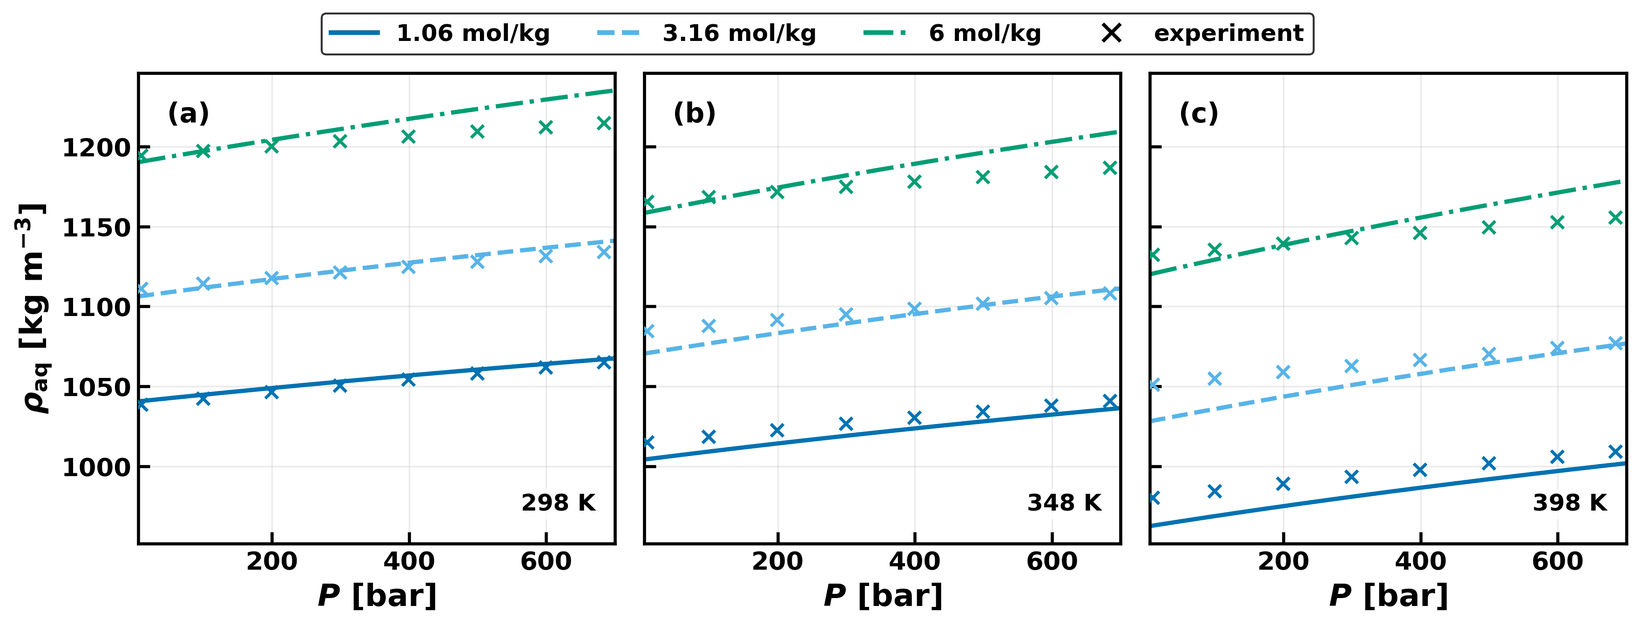

In [4]:
run('scripts/fig_brine_density.py')
show('brine_density_main.png')


<a id="mfig1"></a>

**Figure 1.** $\mathrm{NaCl}$ brine density from ms-eCPA (continuous lines) and experiments<sup>[22](#mref22),[23](#mref23)</sup> (discrete symbols). Analogous panels for $\mathrm{KCl}$, $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$, and $\mathrm{Na_{2}SO_{4}}$ are given in Figs. S6–S9 of the Supporting Information.

Figure 1 compares the ms-eCPA brine density against the high-accuracy densitometer data of Al Ghafri et al.<sup>[22](#mref22),[23](#mref23)</sup> for $\mathrm{NaCl}$ brine at 298, 348, and 398 K, which combine the largest salinity range with three isotherms spanning ambient to subcritical-water conditions. The $\mathrm{NaCl}$ brine density is reproduced across the full salinity range to 0.99% AAD. The corresponding isotherms for $\mathrm{KCl}$, $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$, and $\mathrm{Na_{2}SO_{4}}$ brines at the same three temperatures are shown in Figs. S6–S9 of the Supporting Information; the ion-additive set of coefficients (Table S4 of the Supporting Information) is sufficient for all five salts and removes the need for salt-specific shifts.

The density accuracy matters beyond validation: in compositional reservoir simulation, the aqueous density controls buoyancy-driven convection, plume migration, and the pressure response, and Moortgat et al.<sup>[20](#mref20)</sup> exploit the same converged equation-of-state solve to deliver the phase densities with every flash across the full $(T, P, \mathbf{m})$ window, including the $\mathrm{CO_{2}}$-saturated high-temperature regime where no measurements exist.


<a id="msec3_2"></a>

### 3.2 Osmotic coefficients of the brines

The water activity of the brines provides a direct colligative test of the ion parameterization. Figure 2 compares the osmotic coefficient at 298.15 K, computed from the ms-eCPA water activity as the formulation defines it, with the Pitzer ion-interaction correlations evaluated with the constants of Pitzer and Mayorga<sup>[25](#mref25)</sup>; Table 3 summarises the relative deviations for all five salts next to the values the parameter set’s original authors report for the same formulation. In the infinite-dilution limit the model recovers the Debye–Hückel limiting law, $\phi_{\mathrm{osm}}(0.001\thinspace m\thickspace \mathrm{NaCl}) = 0.9882$ against the Pitzer value of 0.9884. Within the molality ranges the ion parameters were originally fitted over, $\mathrm{NaCl}$, $\mathrm{KCl}$, $\mathrm{MgCl_{2}}$, and $\mathrm{Na_{2}SO_{4}}$ deviate from the Pitzer reference by 0.60%, 2.01%, 0.85%, and 8.57%, respectively — each at, or better than, the accuracy reported by Schlaikjer et al.<sup>[21](#mref21)</sup> for the same salts. Those ranges are not the same for every salt: the Pitzer-anchored constraint extends to $6$ mol kg$^{-1}$ for $\mathrm{NaCl}$ and $4.5$ for $\mathrm{KCl}$, but only to $2$ mol kg$^{-1}$ for $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$ and $\mathrm{Na_{2}SO_{4}}$ (Table 3), above which the water activity in those brines is unconstrained by any independent colligative measurement and the gas-solubility deviations grow accordingly. We therefore recommend $m \le 2$ mol kg$^{-1}$ for $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$ and $\mathrm{Na_{2}SO_{4}}$ where the accuracy of the $1{:}1$ salts is wanted, and treat the predictions above that as useful but looser.

The $\mathrm{CaCl_{2}}$ panel of Fig. 2b shows the one exception and its resolution. The reported $\mathrm{Ca^{2+}}$ row of Schlaikjer et al.<sup>[21](#mref21)</sup> deviates from the Pitzer reference by -27.0% to -52.1% over its own fit range (dash-dotted curve), incompatible with the 5.0% reported in that work; the physically-bracketed refit of Section 2.4 (Table 1) restores the $\mathrm{CaCl_{2}}$ osmotic coefficient to 1.39% over the same range without affecting any other salt, since $\mathrm{Ca^{2+}}$ appears in no other brine of the suite. The provenance of every ion parameter (Table S9), the evidence that the published row itself is defective and the effect of the correction on the $\mathrm{CaCl_{2}}$ observables (Table S10), and the accompanying refit of the $\mathrm{CO_{2}}$–$\mathrm{Ca^{2+}}$ and $\mathrm{CH_{4}}$–$\mathrm{Ca^{2+}}$ reference energies (Table S11) are documented in Section S8 of the Supporting Information, which also reports the corresponding five-salt figure over the full molality ranges.


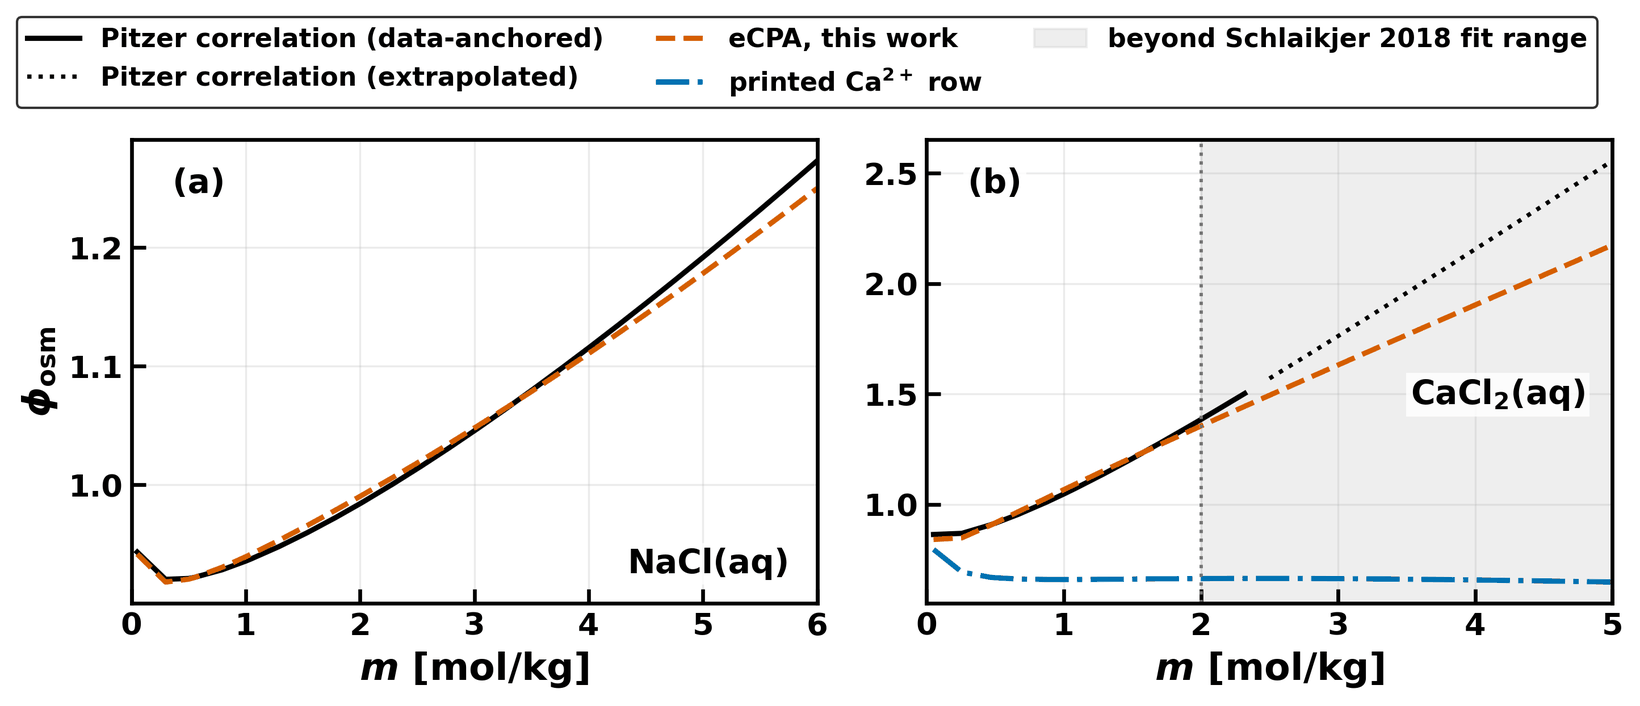

In [5]:
run('scripts/fig_colligative.py')
show('colligative_main.png')


<a id="mfig2"></a>

**Figure 2.** Osmotic coefficient of gas-free brines at 298.15 K from the ms-eCPA water activity (dashed) and the Pitzer correlation with the Pitzer and Mayorga<sup>[25](#mref25)</sup> constants (solid within the molality range anchored to experimental data, dotted beyond) for (a) $\mathrm{NaCl}$ and (b) $\mathrm{CaCl_{2}}$. The dash-dotted curve in (b) uses the (defective) $\mathrm{Ca^{2+}}$ row of Schlaikjer et al.<sup>[21](#mref21)</sup> in place of the corrected values of Table 1; gray shading marks molalities beyond the Schlaikjer et al.<sup>[21](#mref21)</sup> fit range. The remaining salts are shown in Fig. S5 of the Supporting Information.

<a id="mtab3"></a>

**Table 3.** Average relative deviation (RAD) of the ms-eCPA osmotic coefficient from the Pitzer reference at 298.15 K within the molality range each salt was originally fitted over, compared with the deviations reported by Schlaikjer et al.<sup>[21](#mref21)</sup> (their Table 5, no $k_{ij}$) for the same formulation. The $\mathrm{Ca^{2+}}$ row uses the corrected parameters of Table 1.

In [6]:
import json
import pandas as pd

run("scripts/fig_colligative.py")
st = json.load(open("results_cache/fig_colligative_stats.json"))["per_salt"]
schlaikjer = {"NaCl": 1.28, "KCl": 3.86, "CaCl": 5.00, "MgCl": 3.36, "NaSO": 9.37}   # their Table 5
names = {"NaCl": "NaCl", "KCl": "KCl", "CaCl": "CaCl₂", "MgCl": "MgCl₂", "NaSO": "Na₂SO₄"}
show_table(pd.DataFrame([{
    "Salt": names[k],
    "m range (mol/kg)": f"≤ {st[k]['m_fit']:g}",
    "RAD, this work (%)": f"{st[k]['rad_fit']:.2f}",
    "RAD, Schlaikjer et al. 2018 (%)": f"{schlaikjer[k]:.2f}"} for k in names]))


Salt,m range (mol/kg),"RAD, this work (%)","RAD, Schlaikjer et al. 2018 (%)"
NaCl,≤ 6,0.60,1.28
KCl,≤ 4.5,2.01,3.86
CaCl₂,≤ 2,1.39,5.00
MgCl₂,≤ 2,0.85,3.36
Na₂SO₄,≤ 2,8.57,9.37


<a id="msec3_3"></a>

### 3.3 $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ and $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ binaries

The $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ and $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ binaries serve as the salt-free anchor of the multi-salt parameterization. Figure 3 focuses on the $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ binary, for which the literature compilation is by far the densest. Panel (a) gathers $\sim 20$ author cohorts at the ambient-temperature isotherm $T = 298$ K on a log–log pressure–solubility scale spanning four orders of magnitude in $P$; the single CPA model curve passes through the cluster across the full window. Panel (b) shows the same aqueous $\mathrm{CH_{4}}$ mole fraction in per-mil (‰) on linear axes at four isotherms ($T = 298$, $373$, $423$, and $473$ K) and pressures up to $1000$ bar: the temperature dependence of methane solubility is captured quantitatively across the full window, including the mild non-monotonic ordering at low pressure where the $298$ and $373$ K curves overlap. The CPA model captures the $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ aqueous solubility with an overall AAD of $6.9$%. The corresponding water-in-methane mutual solubility, the high-pressure data set of Susak and McGee<sup>[41](#mref41)</sup>, and the $\mathrm{CH_{4}}$ Henry’s constant in pure water are provided in Fig. S24 of the Supporting Information.


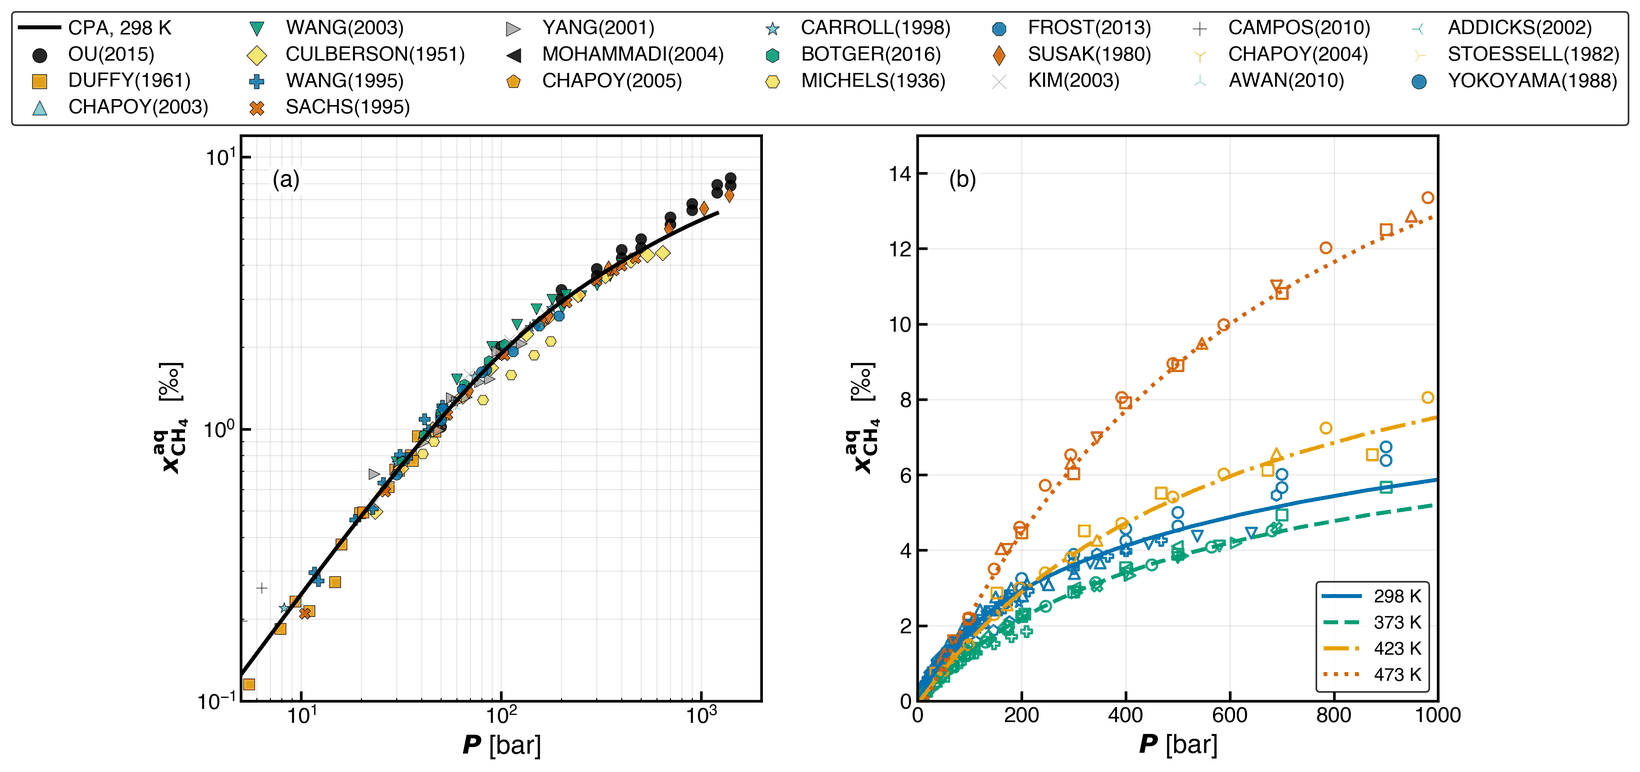

In [7]:
run('scripts/fig_binaries.py')
show('binaries_main.png')


<a id="mfig3"></a>

**Figure 3.** Salt-free $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ binary validation from CPA (continuous lines) and experiments (discrete symbols). (a) Aqueous $\mathrm{CH_{4}}$ mole fraction at the $T = 298$ K isotherm on log–log axes across the literature compilation. (b) Aqueous $\mathrm{CH_{4}}$ mole fraction in per-mil (‰) at four isotherms ($T = 298$, $373$, $423$, $473$ K).

The $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ binary was analyzed in detail with the same eCPA EOS in Coelho et al.<sup>[17](#mref17)</sup> and Moortgat et al.<sup>[18](#mref18)</sup>; the present multi-salt parameterization uses the same $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ binary coefficients (Table 2) and is therefore expected to give numerically indistinguishable results in the salt-free limit.


<a id="msec3_4"></a>

### 3.4 $\mathrm{CO_{2}}$ solubility in single-salt brines

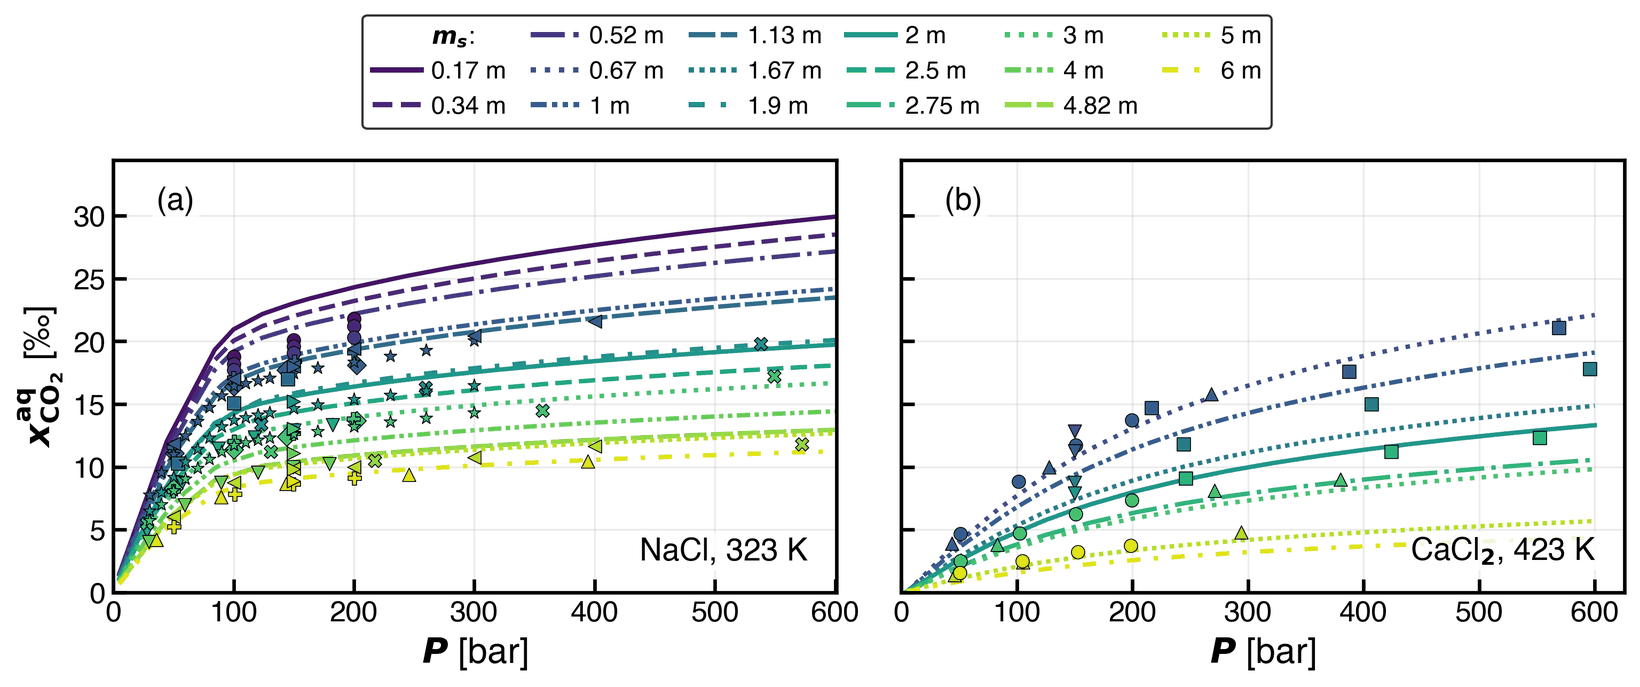

In [8]:
run('scripts/fig_co2_singlesalt.py')
show('co2_singlesalt_main.png')


<a id="mfig4"></a>

**Figure 4.** $\mathrm{CO_{2}}$ solubility (aqueous mole fraction $x_{\mathrm{CO_{2}}}^{\mathrm{aq}} \times 10^3$, per-mil) vs. pressure at several $\mathrm{NaCl}$ and $\mathrm{CaCl_{2}}$ molalities, from ms-eCPA (continuous lines) and experiments (discrete symbols).

Figure 4 compares the predicted $\mathrm{CO_{2}}$ solubility in single-salt brines against experiment for two representative cases: $\mathrm{NaCl}$ at 323 K (the lowest-temperature isotherm with the broadest experimental salinity coverage) and $\mathrm{CaCl_{2}}$ at 423 K (a divalent-cation salt at the upper end of the calibration window, where the salting-out effect is largest and the literature spread is the widest). The figure plots solubility as the aqueous $\mathrm{CO_{2}}$ mole fraction $x_{\mathrm{CO_{2}}}^{\mathrm{aq}} \times 10^3$ (per-mil) rather than molality: it is related to the molality by $x_{\mathrm{CO_{2}}}^{\mathrm{aq}} = m_{\mathrm{CO_{2}}} / (55.51 + m_{\mathrm{CO_{2}}})$ — a mapping that is universal across salt loadings on the partitioning-species basis used here (ions excluded). Across the five-salt calibration set the AAD per salt (Table S5) is 5.4%, 7.2%, 11.1%, 7.1%, and 4.3% for $\mathrm{NaCl}$, $\mathrm{KCl}$, $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$, and $\mathrm{Na_{2}SO_{4}}$, respectively. The somewhat larger error for $\mathrm{CaCl_{2}}$ reflects the broader spread between literature sources at high molality. Analogous panels for the remaining salts ($\mathrm{KCl}$, $\mathrm{MgCl_{2}}$, $\mathrm{Na_{2}SO_{4}}$) and the intermediate isotherm (373 K) are included in Figs. S10–S14 of the Supporting Information.


<a id="msec3_5"></a>

### 3.5 $\mathrm{CH_{4}}$ solubility in single-salt brines

The results for $\mathrm{CH_{4}}$ in single-salt brines are shown in Fig. 5 for two representative cases: $\mathrm{NaCl}$ at 298 K (which has the broadest salinity coverage at ambient temperature) and $\mathrm{CaCl_{2}}$ at 343 K (a divalent cation already at hydrothermal-relevant conditions). AAD values per salt are summarized in Table S7 of the Supporting Information. The high-temperature $\mathrm{CH_{4}}$–$\mathrm{NaCl}$ data of Susak and McGee<sup>[41](#mref41)</sup> exercise the model up to 598 K and 1380 bar, and the $\mathrm{CH_{4}}$–$\mathrm{NaCl}$ set is matched with AAD = 10.2% ($N_p = 394$); for $\mathrm{KCl}$, $\mathrm{MgCl_{2}}$, $\mathrm{Na_{2}SO_{4}}$, and $\mathrm{MgSO_{4}}$ the available experimental window is more limited, but the model agrees with the available data of Stoessell and Byrne<sup>[42](#mref42)</sup>, Kiepe et al.<sup>[43](#mref43)</sup>, and Blanco C. and Smith<sup>[44](#mref44)</sup> to within 1.6–8.5%. The complete per-salt and per-temperature panels appear in Figs. S15–S18 of the Supporting Information (one figure per salt-family: NaCl, KCl, CaCl$_2$, and the other three salts combined), together with the corresponding Henry’s-constant figures in Section S9.5.


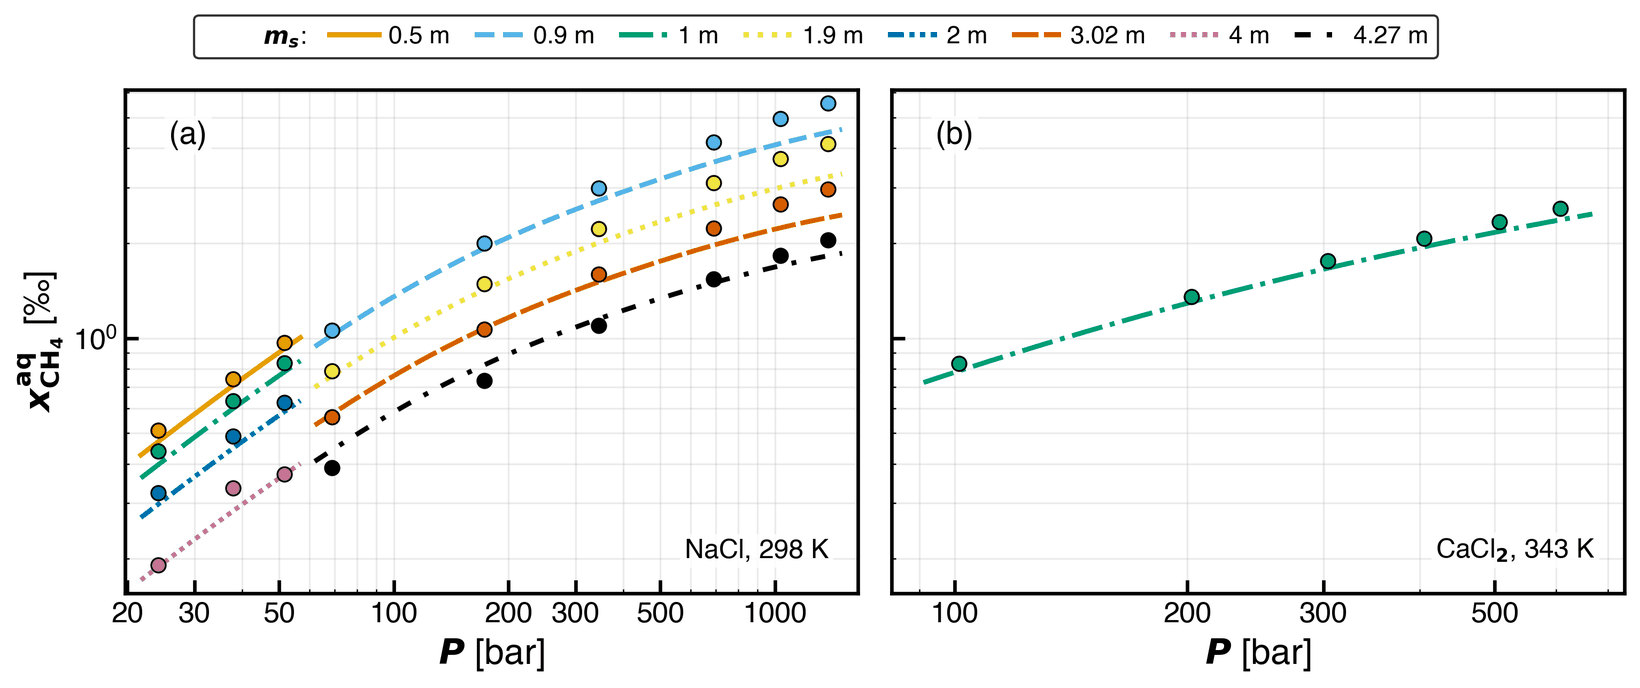

In [9]:
run('scripts/fig_ch4_singlesalt.py')
show('ch4_singlesalt_main.png')


<a id="mfig5"></a>

**Figure 5.** $\mathrm{CH_{4}}$ solubility (aqueous mole fraction $x_{\mathrm{CH_{4}}}^{\mathrm{aq}} \times 10^3$, per-mil, log axis) vs. pressure at several $\mathrm{NaCl}$ and $\mathrm{CaCl_{2}}$ molalities, from ms-eCPA (continuous lines) and experiments (discrete symbols).

<a id="msec3_6"></a>

### 3.6 Mixed-salt brines

Mixed-salt brines provide the strongest test of the ion-specific parameterization, since neither the gas–ion $\Delta U_{gi}$ nor the Péneloux $\Upsilon_i$ coefficients are tuned to the mixed-brine data. Figure 6 shows two representative comparisons: brine B1 of Liu et al.<sup>[31](#mref31)</sup> ($\mathrm{Na^{+}}$/$\mathrm{Cl^{-}}$/$\mathrm{K^{+}}$/$\mathrm{Ca^{2+}}$, $I_c = 1.01$ m) and brine B1 of Wang et al.<sup>[32](#mref32)</sup> ($\mathrm{Na^{+}}$/$\mathrm{Cl^{-}}$/$\mathrm{K^{+}}$/$\mathrm{Ca^{2+}}$/$\mathrm{Mg^{2+}}$/$\mathrm{SO_{4}^{2-}}$, $I_c = 1.29$ m), each measured over three to four isotherms in the $308$–$348$ K, $20$–$160$ bar window. The exact ion molalities of each recipe are given in the caption of Fig. 6. This pair, from independent laboratories, includes every ion at a molality that affects the result — $\mathrm{K^{+}}$ through the Liu et al.<sup>[31](#mref31)</sup> brine and $\mathrm{Mg^{2+}}$ and $\mathrm{SO_{4}^{2-}}$ through the Wang et al.<sup>[32](#mref32)</sup> brine — and includes both divalent cations whose published parameters are revised in Section 2.4. Neither is extreme within the set: the nineteen recipes span $I_c = 0.3$–$5.9$ m, these two rank sixth and eighth lowest in ionic strength, and their per-recipe deviations ($4.2$ and $5.4$ %) sit at or below the median of the set ($5.4$ %). The complete set of nineteen author–brine recipes drawn from Liu et al.<sup>[31](#mref31)</sup>, Wang et al.<sup>[32](#mref32)</sup>, El-Maghraby et al.<sup>[33](#mref33)</sup>, Li et al.<sup>[34](#mref34)</sup>, Tong et al.<sup>[35](#mref35)</sup>, Zhao et al.<sup>[36](#mref36)</sup>, Portier and Rochelle<sup>[37](#mref37)</sup>, Poulain et al.<sup>[38](#mref38)</sup>, Mousavi et al.<sup>[39](#mref39)</sup> is compared with the model in Figs. S19–S23 of the Supporting Information..

Our ms-eCPA model captures these measurements without any mixing rule above the ion level: each ion contributes through its own electrostatic and SRK parameters, and through its own $\Delta U_{gi}$ and $\Upsilon_i$ coefficients. The nineteen recipes are a held-out set: the $\Delta U_{gi}$ coefficients are calibrated on single-salt brines alone, the $\Upsilon_i$ coefficients on the single-salt densities of Al Ghafri et al.<sup>[22](#mref22),[23](#mref23)</sup>, and the ion–ion Huron–Vidal reference energies are all zero, so no salt-level quantity exists that a mixed brine could tune. Across all $314$ points (Table S12 of the Supporting Information) the point-weighted AAD of the predicted $\mathrm{CO_{2}}$ molality is $6.8$ %, with per-recipe values between $2.5$ and $13.6$ % and sixteen of the nineteen recipes below $10$ % — the accuracy band of the single-salt fits of Section 3.4 — and it does not degrade with the total ionic strength of the mixture: the two most concentrated recipes ($I_c = 4.98$ and $5.89$ m) score $2.5$ and $8.9$ %, while all three recipes above $10$ % lie below $I_c = 1$ m.


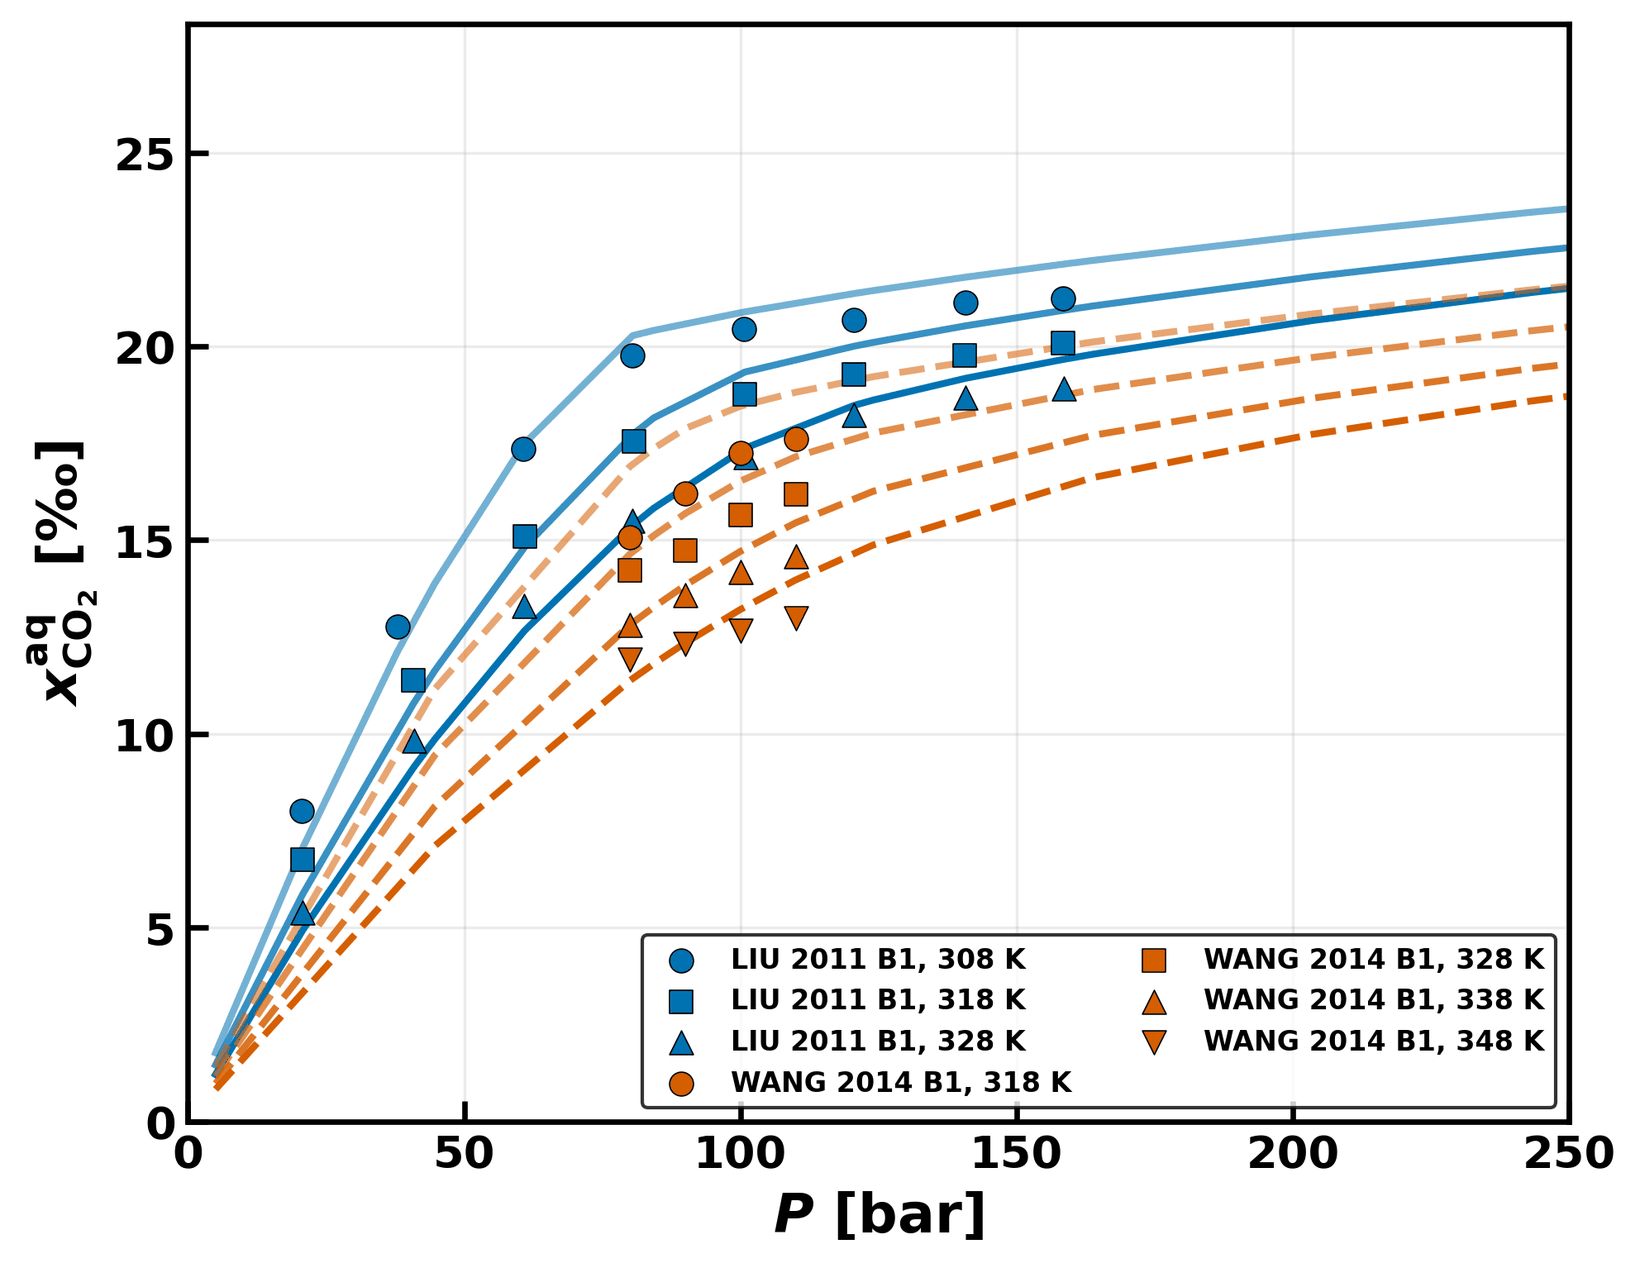

In [10]:
run('scripts/fig_co2_mixed_brines.py')
show('co2_mixed_brines_main.png')


<a id="mfig6"></a>

**Figure 6.** $\mathrm{CO_{2}}$ solubility in two representative mixed brines from ms-eCPA (continuous lines) and experiments (discrete symbols): Liu et al.<sup>[31](#mref31)</sup> brine B1 ($I_c = 1.01$ m: $0.30$ $\mathrm{Na^{+}}$, $0.85$ $\mathrm{Cl^{-}}$, $0.23$ $\mathrm{K^{+}}$, $0.16$ $\mathrm{Ca^{2+}}$ mol kg$^{-1}$) and Wang et al.<sup>[32](#mref32)</sup> brine B1 ($I_c = 1.29$ m: $0.359$ $\mathrm{Na^{+}}$, $0.960$ $\mathrm{Cl^{-}}$, $0.002$ $\mathrm{K^{+}}$, $0.286$ $\mathrm{Ca^{2+}}$, $0.022$ $\mathrm{Mg^{2+}}$, $0.008$ $\mathrm{SO_{4}^{2-}}$ mol kg$^{-1}$).

This validation is confined to $\mathrm{CO_{2}}$. We are not aware of mixed-salt $\mathrm{CH_{4}}$ solubility measurements, or of $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ mutual-solubility measurements in brine of any composition; every $\mathrm{CH_{4}}$–brine point available to us is single-salt, and the ternary $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ data used in the companion study<sup>[20](#mref20)</sup> are salt-free. Mixed-brine $\mathrm{CH_{4}}$ and mixed-gas behavior is therefore a prediction of the ion-specific parameterization rather than a validated result, and the ion-specific and salt-lumped descriptions differ significantly. Computed from a feed of $30$ mol % gas at an equimolar water-free $\mathrm{CO_{2}}$–$\mathrm{CH_{4}}$ ratio and set beside a $\mathrm{NaCl}$ brine of the same ionic strength — the surrogate a salt-lumped description would use — the nineteen recipes show a predicted $\mathrm{CH_{4}}$ solubility that differ from that surrogate by $1.1$–$47.3$ % at $323$ K and $100$ bar against $0.5$–$17.6$ % for $\mathrm{CO_{2}}$, and the aqueous $\mathrm{CO_{2}}$/$\mathrm{CH_{4}}$ ratio falls by $0.6$–$20.2$ %; over all 295 measured temperature–pressure states the $\mathrm{CH_{4}}$ departure is positive and exceeds the $\mathrm{CO_{2}}$ departure at every state (Tables S13 and S14 of the Supporting Information). A single set of $\mathrm{CH_{4}}$-in-formation-water measurements would discriminate between the two descriptions.


<a id="msec3_7"></a>

### 3.7 Enthalpy of $\mathrm{CO_{2}}$ dissolution: a calorimetric consistency check

The isothermal solubility, density, and osmotic-coefficient data underlying the parameterization constrain the temperature dependence of the model parameters only indirectly, through the spacing of neighboring isotherms. We therefore close the validation with a property that probes that temperature dependence directly. For dissolution at constant $T$ and $P$ the heat released or absorbed is the enthalpy of mixing, a summation over all species,

$$\Delta H_\text{mix} = \sum_i n_i \left( \bar{h}_i - h_i \right), \tag{21}$$

with $\bar{h}_i$ the partial molar enthalpy of species $i$ in the mixed state and $h_i$ its molar enthalpy in the unmixed feed stream. In the dilute-solution limit relevant here the solvent and ion contributions cancel to first order by the Gibbs–Duhem relation, and the measured heat per mole of gas dissolved reduces to the $\mathrm{CO_{2}}$ term,

$$\Delta H_\text{sol}(T, P, \mathbf{m}) = -RT^2 \left[ \left(\frac{\partial \ln \hat\phi_{\mathrm{CO_{2}}}^{\text{aq}}} {\partial T}\right)_{\negthinspace P,\mathbf{x}} - \left(\frac{\partial \ln \phi_{\mathrm{CO_{2}}}^{\text{pure}}} {\partial T}\right)_{\negthinspace P} \right], \tag{22}$$

the difference between the partial molar residual enthalpy of $\mathrm{CO_{2}}$ at near-infinite dilution in the solvent and the residual enthalpy of the pure compressed gas (the ideal-gas contributions cancel at equal temperature). Both fugacity coefficients are evaluated with the equilibrium-computation approach of Section 2.6, whose inner solves carry complex-step Jacobians at machine precision; the outer temperature derivatives of the converged fugacity coefficients are then taken by ordinary centered finite differences ($\Delta T = 0.2$ K). Varying the step over $\Delta T = 0.1$–$0.4$ K moves $\Delta H_\text{sol}$ by at most $1.2 \times 10^{-3}$ kJ mol$^{-1}$ at the 22 measured states, and the residual truncation error at $\Delta T = 0.2$ K is below $3 \times 10^{-4}$ kJ mol$^{-1}$; raising the aqueous $\mathrm{CO_{2}}$ mole fraction that stands for the near-infinite-dilution limit from $10^{-4}$ to $10^{-3}$ moves it by at most $0.042$ kJ mol$^{-1}$. The experimental uncertainty is about 5 %, or $0.1$–$0.7$ kJ mol$^{-1}$ across these points, so the step sensitivity stays more than two orders of magnitude below it at every point and the dilution sensitivity within a quarter of it.

Koschel et al.<sup>[45](#mref45)</sup> measured exactly this quantity by flow calorimetry, expressly at geological-sequestration conditions: $\mathrm{CO_{2}}$ dissolving in water and in 1 and 3 mol kg$^{-1}$ $\mathrm{NaCl}$ at 323.1 and 373.1 K and 2–20 MPa, with a stated uncertainty of about 5%, and no other directly comparable data in the literature. Figure 7 compares the model against all 22 calorimetric points. No parameter was adjusted or refitted: the curves are predictions of the parameter set of Section 2, which never saw caloric data. The mean absolute deviation is 0.6 kJ mol$^{-1}$ overall and 0.3 kJ mol$^{-1}$ at 323.1 K, where the model runs essentially within the experimental error bars — including the steep decrease of $|\Delta H_\text{sol}|$ between 5 and 14 MPa, which reflects the crossing of the pure-$\mathrm{CO_{2}}$ critical isochore and enters Eq. (22) through the pure-gas term. The measured salt trend is also reproduced: the exothermicity weakens from water to 1 m to 3 m $\mathrm{NaCl}$ at 323.1 K, while the three solvents nearly coincide at 373.1 K. The one systematic deviation is at 373.1 K in pure water, where the model is 1–2 kJ mol$^{-1}$ too exothermic, indicating that the temperature derivative of the $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ interaction is slightly too steep at the high-temperature end; the deviation shrinks in the brines. We consider this an informative, parameter-free test of the temperature derivatives of the water–gas and gas–ion interactions that the isothermal calibration leaves loosely constrained.


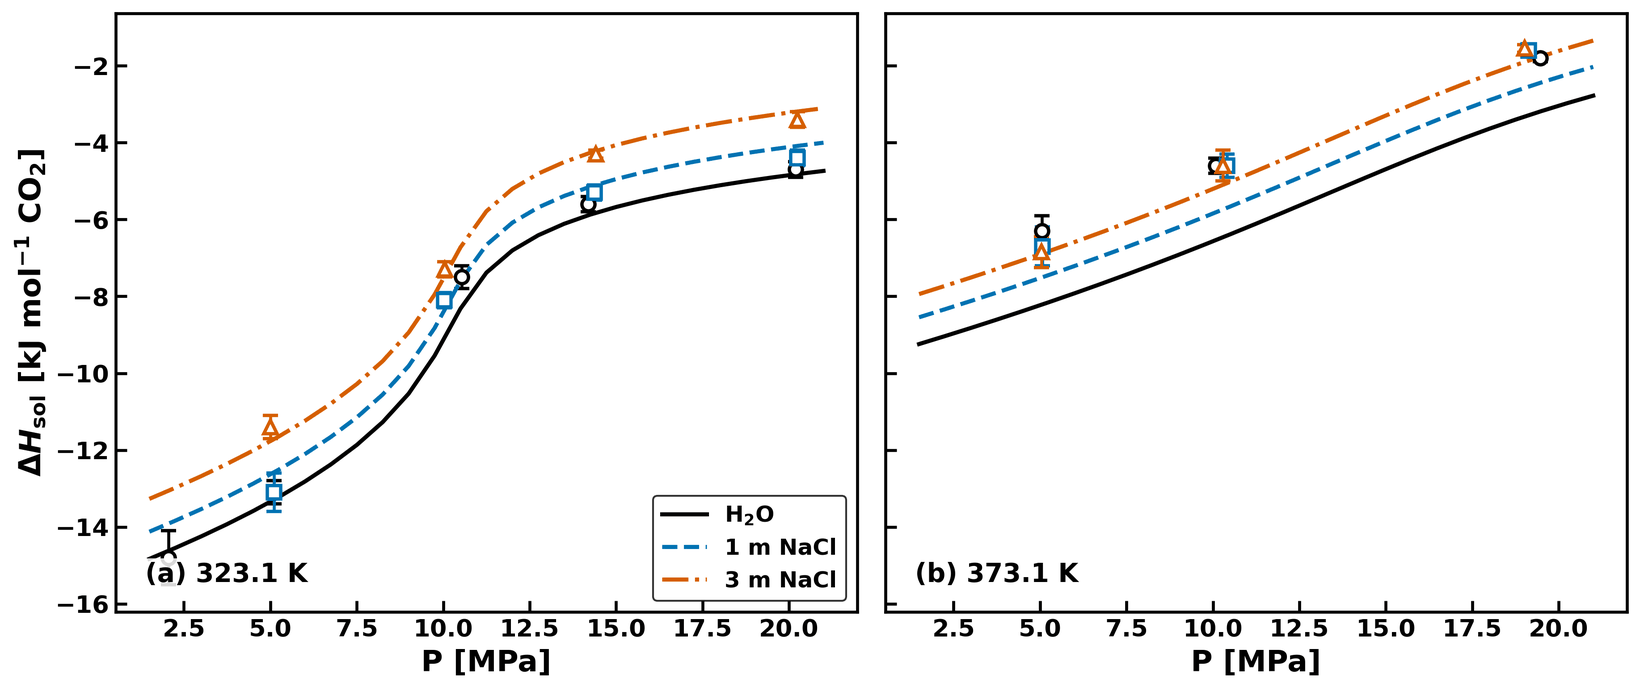

In [11]:
run('pilot_studies/koschel_enthalpy_2026_08/koschel_pilot.py', '--stage', 'figure', long=('--stage', 'all'))
show('pilot_studies/koschel_enthalpy_2026_08/fig_koschel_enthalpy.png')


<a id="mfig7"></a>

**Figure 7.** Enthalpy of solution of $\mathrm{CO_{2}}$ in water and in 1 and 3 mol kg$^{-1}$ $\mathrm{NaCl}$ at (a) 323.1 K and (b) 373.1 K. Symbols with error bars: flow-calorimetry data of Koschel et al.<sup>[45](#mref45)</sup>; curves: ms-eCPA predictions via Eq. (22) with no adjusted parameters.

<a id="msec4"></a>

## 4 Conclusions

We have presented an ion-specific parameterization of the electrolyte Cubic-Plus-Association equation of state for the system $\mathrm{H_{2}O}$–$\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–($\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$, $\mathrm{K^{+}}$, $\mathrm{Ca^{2+}}$, $\mathrm{Mg^{2+}}$, $\mathrm{SO_{4}^{2-}}$). The same model handles single-salt brines, mixed-salt brines, and brine density with one set of pure-component, binary, and Péneloux parameters that does not require any salt-level mixing rule. Validation against 2,512 published single-salt gas–brine solubility points (1,931 for $\mathrm{CO_{2}}$, 581 for $\mathrm{CH_{4}}$) and the high-accuracy brine density data of Al Ghafri et al.<sup>[22](#mref22),[23](#mref23)</sup> shows AAD values per salt in the range of 4.3–11.1% for $\mathrm{CO_{2}}$ solubility, 1.6–10.2% for $\mathrm{CH_{4}}$ solubility, and 1.21% for brine density from a single ion-additive coefficient set.

The principal contributions are:

- Temperature-dependent ion–gas $\Delta U_{gi}$ coefficients for each of the six ions and each of the two volatile gases (Table S3 of the Supporting Information);

- Temperature-dependent ion-specific Péneloux volume shifts (Table S4 of the Supporting Information) that collapse the brine-density problem onto an ion-additive basis;

- A colligative verification of the inherited ion parameters against the Pitzer osmotic-coefficient standard, correcting the published $\mathrm{Ca^{2+}}$ parameters and the $\mathrm{Mg^{2+}}$ polarizability;

- Prediction of $\mathrm{CO_{2}}$ solubility in nineteen mixed-brine recipes with no mixed-brine tuning; the corresponding $\mathrm{CH_{4}}$ and $\mathrm{CO_{2}}$–$\mathrm{CH_{4}}$ predictions in those brines are reported but remain untested, as no mixed-salt $\mathrm{CH_{4}}$ or $\mathrm{CO_{2}}$–$\mathrm{CH_{4}}$–brine measurements are available;

- A parameter-free prediction of the calorimetric enthalpies of $\mathrm{CO_{2}}$ dissolution in water and $\mathrm{NaCl}$ brines (mean absolute deviation 0.6 kJ mol$^{-1}$), testing the temperature derivatives of the water–gas and gas–ion interactions;

- A consistent treatment of $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ cross-association and ion-specific Debye–Hückel and Born contributions across the temperature range spanned by the calibration and validation data.

The temperature, pressure, and salinity windows quoted in this paper (Section 2.5) are the span of the experimental data used to calibrate and to test the parameterization, not a separate statement of where the model is reliable. Because the gas–water and gas–ion parameters are low-order polynomials in temperature with no constraint imposed outside the fitted window, we make no accuracy claim beyond it.

All equilibrium computations in this paper were performed with the two-phase Michelsen stability test and accelerated $K$-value flash presented in the companion study<sup>[20](#mref20)</sup>, which demonstrates the robustness and efficiency of that framework over $\sim 150\thinspace 000$ conditions spanning the full calibration window of this paper, extends the parameterization to $\mathrm{N_{2}}$, $\mathrm{H_{2}}$, $\mathrm{C_{2}H_{6}}$, $\mathrm{C_{3}H_{8}}$, and $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ gas mixtures at the cost of, at most, one salt-free binary fit per new gas, and generalizes the stability–flash hierarchy to three-phase vapor–brine–liquid equilibria validated against the measured $\mathrm{CO_{2}}$ and $\mathrm{C_{3}H_{8}}$ three-phase loci. Together, the two papers constitute a single self-consistent thermodynamic engine for compositional reservoir simulation of $\mathrm{CO_{2}}$ sequestration, $\mathrm{CH_{4}}$ production, and mixed-gas storage in realistic brines.

Several extensions are natural and in progress. The framework will be coupled to a full compositional reservoir simulator<sup>[4](#mref4)</sup>, generalizing its three-dimensional warm-start solution table to the six-ion suite presented here; the coupled deformation and transport side of such subsurface descriptions is being placed on a comparable thermodynamic footing<sup>[46](#mref46)</sup>. On the parameter side, the colligative verification of Section 3.2 now anchors the ion parameterization against the osmotic-coefficient standard and corrects the two defects it uncovered (the published $\mathrm{Ca^{2+}}$ parameters and the $\mathrm{Mg^{2+}}$ polarizability); a full, physically anchored co-refit of all ion parameters against colligative, density, and gas-solubility data simultaneously — together with structural extensions of the static-permittivity closure — remains for follow-up work. Open issues that warrant further attention include the systematic incorporation of low-temperature vapor–liquid–liquid equilibria in $\mathrm{CO_{2}}$–$\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ mixtures and the extension to non-equilibrium transport properties such as density gradients and sound speed, and the solid phases required by applications such as $\mathrm{CH_{4}}$ recovery from hydrate-bearing sediments by $\mathrm{CO_{2}}$ replacement<sup>[47](#mref47)</sup>. A further gap is on the measurement side: no $\mathrm{CH_{4}}$ solubility data in mixed-salt brines, and no $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ mutual-solubility data in brine of any composition, are available to test the ion-additive predictions reported in Section 3.6.


## Supporting Information

Parameter-hierarchy overview of the model (S1); nomenclature (S2); closed-form expressions for the compressibility factor and the fugacity coefficient of each Helmholtz contribution (S3); Onsager–Kirkwood derivation of the static permittivity with its volume and composition derivatives (S4); temperature-dependent Péneloux volume translation and parameter-fitting protocol (S5); ion–solvent, ion–gas, and Péneloux volume-translation parameters with temperature-dependence plots, the pure-component constants and gas–water and gas–gas binary interaction parameters $k_{ij}$ being given in Tables 1 and 2 of the main text (S6); calibration data inventory for $\mathrm{CO_{2}}$–brine, $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$, and $\mathrm{CH_{4}}$–brine VLE (S7); provenance of the ion parameters and the $\mathrm{Ca^{2+}}$ correction with the five-salt osmotic-coefficient comparison (S8); expanded validation figures for brine density, single-salt $\mathrm{CO_{2}}$, single-salt $\mathrm{CH_{4}}$, mixed-salt $\mathrm{CO_{2}}$, and Henry’s constants, with the predicted $\mathrm{CH_{4}}$ and $\mathrm{CO_{2}}$–$\mathrm{CH_{4}}$ behavior in the mixed-brine recipes (S9) (PDF)

A copy of the unpublished companion manuscript<sup>[20](#mref20)</sup> is provided as Supporting Information for Review Only. It carries its own Supporting Information and its own S-numbered figures and tables; every S-numbered reference in the present manuscript is to the Supporting Information of this Part I.


## Author Contributions

**Joachim Moortgat:** Conceptualization, Data curation, Formal analysis, Investigation, Methodology, Project administration, Resources, Software, Validation, Visualization, Writing – original draft. **Felipe Mourão Coelho:** Data curation, Writing – original draft. **Abbas Firoozabadi:** Conceptualization, Funding acquisition, Writing – original draft.


## Data and Code Availability

The experimental compilation this work is validated against is released as GasBrineBench, an open database of experimental gas–brine thermodynamic data in which every row carries its source, a quality code, and a fit/test tag. It is available at <https://github.com/jmoortgat/GasBrineBench> and archived on Zenodo; the release used here is v1.1.0 (11,537 rows over 111 sources), <https://doi.org/10.5281/zenodo.22863478>, while the concept DOI 10.5281/zenodo.22834145 always resolves to the newest version. The phase-equilibrium code for ms-eCPA parameterization, together with the scripts that regenerate every figure and table in this paper, is released through the repository of the first paper of this series, <https://github.com/jmoortgat/CPA_and_eCPA_flash>, to which it will be added on publication so that the papers share one code base.


## Acknowledgments

Abbas Firoozabadi was supported by the member companies of the Reservoir Engineering Research Institute. Felipe Mourão Coelho thanks the São Paulo Research Foundation (FAPESP, grants #2018/02713-8, #2020/13300-6, and #2021/13068-9), the Centro Nacional de Processamento de Alto Desempenho em São Paulo (CENAPAD-SP), the John David Rogers Computing Center (CCJDR) at the Institute of Physics “Gleb Wataghin” of the University of Campinas, the Coordenação de Aperfeiçoamento de Pessoal de Nível Superior (CAPES) Brasil, and the Conselho Nacional de Desenvolvimento Científico e Tecnológico (CNPq) Brasil for support during the development of the parameterization. J. Moortgat did not receive any specific grant from funding agencies in the public, commercial, or not-for-profit sectors. During the preparation of this work the authors used Claude and Claude Code (Anthropic) to improve the grammar and conciseness of the manuscript and its LaTeX formatting, and to improve code optimization, testing, formatting, and documentation. After using these tools, the authors reviewed and edited all content as needed and take full responsibility for the content of the published article.


## TOC Graphic

![TOC graphic](images/ms_ecpa_parametrization_toc.png)

<a id="mrefs"></a>

## References

<a id="mref1"></a>1. Metz, B.; Davidson, O.; de Coninck, H.; Loos, M.; Meyer, L. *IPCC Special Report on Carbon Dioxide Capture and Storage*; Cambridge University Press: Cambridge, UK, 2005

<a id="mref2"></a>2. Orr, F. M. Storage of Carbon Dioxide in Geologic Formations. *Journal of Petroleum Technology* **2004**, *56*, 90–97

<a id="mref3"></a>3. Soltanian, M. R.; Amooie, M. A.; Cole, D. R.; Graham, D. E.; Hosseini, S. A.; Hovorka, S.; Pfiffner, S. M.; Phelps, T. J.; Moortgat, J. Simulating the Cranfield Geological Carbon Sequestration Project with High-Resolution Static Models and an Accurate Equation of State. *International Journal of Greenhouse Gas Control* **2016**, *54*, 282–296

<a id="mref4"></a>4. Moortgat, J. Reservoir Simulation with the Cubic Plus (Cross-) Association Equation of State for Water, $\mathrm{CO_{2}}$, Hydrocarbons, and Tracers. *Advances in Water Resources* **2018**, *114*, 29–44

<a id="mref5"></a>5. Coelho, F. M. a.; Mercier Franco, L. F.; Firoozabadi, A. Modeling of phase equilibria of $\mathrm{H_{2}}$ and $\mathrm{H_{2}}$–$\mathrm{CO_{2}}$ in $\mathrm{NaCl}$ brine mixtures from e<span class="smallcaps">CPA</span> equation of state. *International Journal of Hydrogen Energy* **2025**, *178*, 151361

<a id="mref6"></a>6. Moortgat, J. Vapor–Liquid Equilibrium of Water–Hydrogen Mixtures: A Review of Experimental Data and Modeling with a Cubic-Plus-Association Equation-of-State. *PLOS ONE* **2025**, *20*, e0332157

<a id="mref7"></a>7. Cao, C.; Xu, S.; Zhao, Y.; Wang, Y.; Zhang, L.; Li, Q.; Zhou, S.; Wen, S.; Wei, Y.; Li, J.; Liu, L. Transport mechanisms of $\mathrm{CO_{2}}$/$\mathrm{N_{2}}$–$\mathrm{CH_{4}}$ flow: a digital rock study based on in-situ reaction of $\mathrm{CO_{2}}$–brine–carbonate systems. *Energy* **2026**, *344*, 139772

<a id="mref8"></a>8. Kontogeorgis, G. M.; Voutsas, E. C.; Yakoumis, I. V.; Tassios, D. P. An equation of state for associating fluids. *Ind. Eng. Chem. Res.* **1996**, *35*, 4310–4318

<a id="mref9"></a>9. Wertheim, M. S. Fluids with highly directional attractive forces. I. Statistical thermodynamics. *J. Stat. Phys.* **1984**, *35*, 19–34

<a id="mref10"></a>10. Li, Z.; Firoozabadi, A. Cubic-plus-association equation of state for water-containing mixtures: Is “cross association” necessary? *AIChE J.* **2009**, *55*, 1803–1813

<a id="mref11"></a>11. Moortgat, J.; Li, Z.; Firoozabadi, A. Three-Phase Compositional Modeling of $\mathrm{CO_{2}}$ Injection by Higher-Order Finite Element Methods with CPA Equation of State. Proceedings of the SPE Reservoir Simulation Symposium. The Woodlands, Texas, USA, 2011; SPE-141907-MS

<a id="mref12"></a>12. Moortgat, J.; Li, Z.; Firoozabadi, A. Three-Phase Compositional Modeling of $\mathrm{CO_{2}}$ Injection by Higher-Order Finite Element Methods with CPA Equation of State for Aqueous Phase. *Water Resources Research* **2012**, *48*, W12511

<a id="mref13"></a>13. Nasrabadi, H.; Moortgat, J.; Firoozabadi, A. New Three-Phase Multicomponent Compositional Model for Asphaltene Precipitation during $\mathrm{CO_{2}}$ Injection Using CPA-EOS. *Energy & Fuels* **2016**, *30*, 3306–3319

<a id="mref14"></a>14. Maribo-Mogensen, B.; Thomsen, K.; Kontogeorgis, G. M. An electrolyte CPA equation of state for mixed solvent electrolytes. *AIChE J.* **2015**, *61*, 2933–2950

<a id="mref15"></a>15. Maribo-Mogensen, B.; Kontogeorgis, G. M.; Thomsen, K. Modeling of Dielectric Properties of Aqueous Salt Solutions with an Equation of State. *J. Phys. Chem. B* **2013**, *117*, 10523–10533

<a id="mref16"></a>16. Kontogeorgis, G. M.; Schlaikjer, A.; Olsen, M. D.; Maribo-Mogensen, B.; Thomsen, K.; Liang, X.; Bell, I. H. A review of electrolyte equations of state with emphasis on those based on cubic and cubic-plus-association (CPA) models. *International Journal of Thermophysics* **2022**, *43*, 54

<a id="mref17"></a>17. Coelho, F. M.; Mercier Franco, L. F.; Firoozabadi, A. Phase Equilibria of $\mathrm{CO_{2}}$–Water and $\mathrm{CO_{2}}$–Brine at High Temperatures: From Monte Carlo Simulations to the Equation of State. *Industrial & Engineering Chemistry Research* **2025**, *64*, 8492–8505

<a id="mref18"></a>18. Moortgat, J.; Coelho, F. M.; Firoozabadi, A. Fast and Robust Phase Equilibrium Computations for $\mathrm{CO_{2}}$ + $\mathrm{H_{2}O}$ + $\mathrm{NaCl}$ Mixtures Using the Electrolyte Cubic-Plus-Association Equation of State. *Industrial & Engineering Chemistry Research* **2026**, *65*, 20081–20103

<a id="mref19"></a>19. Tsivintzelis, I.; Kontogeorgis, G. M.; Michelsen, M. L.; Stenby, E. H. Modeling phase equilibria for acid gas mixtures using the CPA equation of state. Part II: Binary mixtures with $\mathrm{CO_{2}}$. *Fluid Phase Equilibr.* **2011**, *306*, 38–56

<a id="mref20"></a>20. Moortgat, J.; Coelho, F. M.; Firoozabadi, A. Phase Equilibria of $\mathrm{CO_{2}}$, $\mathrm{CH_{4}}$, $\mathrm{N_{2}}$, $\mathrm{H_{2}}$, $\mathrm{C_{2}H_{6}}$, $\mathrm{C_{3}H_{8}}$, and Mixtures in Multisalt Brines: Robust Stability and Flash Computations with an Ion-Specific Electrolyte Cubic-Plus-Association Equation of State. *Energy Fuels* **2026**, available online. [DOI: 10.1021/acs.energyfuels.6c04569](https://pubs.acs.org/enfuem/article/doi/10.1021/acs.energyfuels.6c04569/5462396/Phase-Equilibria-of-CO2-CH4-N2-H2-C2H6-C3H8-and)

<a id="mref21"></a>21. Schlaikjer, A.; Thomsen, K.; Kontogeorgis, G. M. eCPA: An ion-specific approach to parametrization. *Fluid Phase Equilibria* **2018**, *470*, 176–187

<a id="mref22"></a>22. Al Ghafri, S.; Maitland, G. C.; Trusler, J. P. M. Densities of Aqueous $\mathrm{MgCl_{2}}$(aq), $\mathrm{CaCl_{2}}$(aq), KI(aq), NaCl(aq), KCl(aq), $\mathrm{AlCl_{3}}$(aq), and (0.964 NaCl + 0.136 KCl)(aq) at Temperatures Between (283 and 472) K, Pressures up to 68.5 MPa, and Molalities up to 6 mol·kg$^{–1}$. *J. Chem. Eng. Data* **2012**, *57*, 1288–1304

<a id="mref23"></a>23. Al Ghafri, S. Z.; Maitland, G. C.; Trusler, J. P. M. Densities of $\mathrm{SrCl_{2}}$(aq), $\mathrm{Na_{2}SO_{4}}$(aq), $\mathrm{NaHCO_{3}}$(aq), and Two Synthetic Reservoir Brines at Temperatures between (298 and 473) K, Pressures up to 68.5 MPa, and Molalities up to 3 mol·kg–1. *Journal of Chemical & Engineering Data* **2013**, *58*, 402–412

<a id="mref24"></a>24. Péneloux, A.; Rauzy, E.; Fréze, R. A consistent correction for Redlich–Kwong–Soave volumes. *Fluid Phase Equilibria* **1982**, *8*, 7–23

<a id="mref25"></a>25. Pitzer, K. S.; Mayorga, G. Thermodynamics of electrolytes. II. Activity and osmotic coefficients for strong electrolytes with one or both ions univalent. *The Journal of Physical Chemistry* **1973**, *77*, 2300–2308

<a id="mref26"></a>26. Shannon, R. D. Revised effective ionic radii and systematic studies of interatomic distances in halides and chalcogenides. *Acta Crystallographica Section A* **1976**, *32*, 751–767

<a id="mref27"></a>27. Marcus, Y. Ionic radii in aqueous solutions. *Chemical Reviews* **1988**, *88*, 1475–1498

<a id="mref28"></a>28. Held, C.; Cameretti, L. F.; Sadowski, G. Modeling aqueous electrolyte solutions: Part 1. Fully dissociated electrolytes. *Fluid Phase Equilibria* **2008**, *270*, 87–96

<a id="mref29"></a>29. Rashin, A. A.; Honig, B. Reevaluation of the Born model of ion hydration. *The Journal of Physical Chemistry* **1985**, *89*, 5588–5593

<a id="mref30"></a>30. Pyper, N. C.; Pike, C. G.; Edwards, P. P. The polarizabilities of species present in ionic solutions. *Molecular Physics* **1992**, *76*, 353–372

<a id="mref31"></a>31. Liu, Y.; Hou, M.; Yang, G.; Han, B. Solubility of $\mathrm{CO_{2}}$ in aqueous solutions of NaCl, KCl, $\mathrm{CaCl_{2}}$ and their mixed salts at different temperatures and pressures. *J. Supercrit. Fluid.* **2011**, *56*, 125–129

<a id="mref32"></a>32. Wang, L.; Shen, Z.; Hu, L.; Yu, Q. Modeling and measurement of $\mathrm{CO_{2}}$ solubility in salty aqueous solutions and application in the Erdos Basin. *Fluid Phase Equilibria* **2014**, *377*, 45–55

<a id="mref33"></a>33. El-Maghraby, R.; Pentland, C.; Iglauer, S.; Blunt, M. A fast method to equilibrate carbon dioxide with brine at high pressure and elevated temperature including solubility measurements. *The Journal of Supercritical Fluids* **2012**, *62*, 55–59

<a id="mref34"></a>34. Li, Z.; Dong, M.; Li, S.; Dai, L. Densities and Solubilities for Binary Systems of Carbon Dioxide + Water and Carbon Dioxide + Brine at 59 °C and Pressures to 29 MPa. *Journal of Chemical & Engineering Data* **2004**, *49*, 1026–1031

<a id="mref35"></a>35. Tong, D.; Trusler, J. P. M.; Vega-Maza, D. Solubility of CO2 in Aqueous Solutions of $\mathrm{CaCl_{2}}$ or $\mathrm{MgCl_{2}}$ and in a Synthetic Formation Brine at Temperatures up to 423 K and Pressures up to 40 MPa. *Journal of Chemical & Engineering Data* **2013**, *58*, 2116–2124

<a id="mref36"></a>36. Zhao, H.; Dilmore, R.; Allen, D. E.; Hedges, S. W.; Soong, Y.; Lvov, S. N. Measurement and Modeling of $\mathrm{CO_{2}}$ Solubility in Natural and Synthetic Formation Brines for $\mathrm{CO_{2}}$ Sequestration. *Environmental Science & Technology* **2015**, *49*, 1972–1980

<a id="mref37"></a>37. Portier, S.; Rochelle, C. Modelling $\mathrm{CO_{2}}$ solubility in pure water and NaCl-type waters from 0 to 300 °C and from 1 to 300 bar: Application to the Utsira Formation at Sleipner. *Chemical Geology* **2005**, *217*, 187–199, Geochemical Aspects of CO2 sequestering

<a id="mref38"></a>38. Poulain, M.; Messabeb, H.; Lach, A.; Contamine, F.; Cézac, P.; Serin, J.-P.; Dupin, J.-C.; Martinez, H. Experimental Measurements of Carbon Dioxide Solubility in Na–Ca–K–Cl Solutions at High Temperatures and Pressures up to 20 MPa. *Journal of Chemical & Engineering Data* **2019**, *64*, 2497–2503

<a id="mref39"></a>39. Mousavi, R.; Chapoy, A.; Burgass, R. $\mathrm{CO_{2}}$ solubility in aqueous solution of salts: Experimental study and thermodynamic modelling. *Greenhouse Gases: Science and Technology* **2024**, *14*, 791–828

<a id="mref40"></a>40. Ahmadi, P.; Chapoy, A. $\mathrm{CO_{2}}$ solubility in formation water under sequestration conditions. *Fluid Phase Equilibria* **2018**, *463*, 80–90

<a id="mref41"></a>41. Susak, N.; McGee, K. A. *A routine for estimating the solubility of methane in pure water or NaCl brines by using the Texas Instruments TI-59 calculator*; Technical Report 80-371, 1980

<a id="mref42"></a>42. Stoessell, R. K.; Byrne, P. A. Salting-out of methane in single-salt solutions at 25°C and below 800 psia. *Geochimica et Cosmochimica Acta* **1982**, *46*, 1327–1332

<a id="mref43"></a>43. Kiepe, J.; Horstmann, S.; Fischer, K.; Gmehling, J. Experimental Determination and Prediction of Gas Solubility Data for Methane + Water Solutions Containing Different Monovalent Electrolytes. *Industrial & Engineering Chemistry Research* **2003**, *42*, 5392–5398

<a id="mref44"></a>44. Blanco C., L. H.; Smith, N. O. The high pressure solubility of methane in aqueous calcium chloride and aqueous tetraethylammonium bromide. Partial molar properties of dissolved methane and nitrogen in relation to water structure. *The Journal of Physical Chemistry* **1978**, *82*, 186–191

<a id="mref45"></a>45. Koschel, D.; Coxam, J.-Y.; Rodier, L.; Majer, V. Enthalpy and solubility data of $\mathrm{CO_{2}}$ in water and NaCl(aq) at conditions of interest for geological sequestration. *Fluid Phase Equilibr.* **2006**, *247*, 107–120

<a id="mref46"></a>46. Bai, B.; Wu, H.; Zhou, R.; Wu, N.; Zhang, B. A granular thermodynamic framework-based coupled multiphase–substance flow model considering temperature driving effect. *Journal of Rock Mechanics and Geotechnical Engineering* **2025**, *17*, 5816–5828

<a id="mref47"></a>47. Zhang, X.; Yuan, Q.; Cui, W.; Song, H.; Li, J.; He, J.; Wu, Q.; Zhang, P. Experimental study on the influence of different hydrate saturation and occurrence morphology on $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ replacement behavior from hydrate-bearing sediments: implications for $\mathrm{CH_{4}}$ recovery and $\mathrm{CO_{2}}$ storage. *Energy* **2026**, *356*, 141311

<a id="stop"></a>

# Supporting Information

This document provides supplementary material for the main text. Section S1 summarizes the parameter hierarchy of the model. Section S2 lists the nomenclature. Section S3 lays out the closed-form expressions for the compressibility-factor and fugacity-coefficient contributions of each Helmholtz term in the eCPA equation of state. Section S4 derives the volume and composition derivatives of the static relative permittivity that close the eCPA system. Section S5 collects the Péneloux volume-translation discussion and the parameter-fitting protocol. Section S6 tabulates the ion–solvent, ion–gas, and Péneloux volume-translation parameters with their temperature- dependence plots. Section S7 tabulates the full experimental calibration data inventory. Section S8 documents the provenance of the ion-specific parameters, the osmotic-coefficient verification of the adopted set, and the correction of the $\mathrm{Ca^{2+}}$ parameters and the $\mathrm{Mg^{2+}}$ polarizability. Section S9 reports the expanded validation of ms-eCPA against literature data, with one subsection per family of properties and one figure per salt or per literature reference. The algorithmic listings of the stability test and $K$-value flash, and the dense-grid efficiency and prediction catalogs, are provided in the Supporting Information of the companion algorithmic study<sup>[1](#sref1)</sup>.


<a id="ssecS1"></a>

## S1 Parameter hierarchy of the model

Table S1 summarizes the parameter hierarchy of the ms-eCPA equation of state introduced in Section 1 of the main text: which parameters enter at each level of physical description, the data that fix them, and where each level is validated.


<a id="stabS1"></a>

**Table S1.** Parameter hierarchy of ms-eCPA equation of state. Each level of physical description introduces only the parameters listed, regressed to data characteristic of that level, with all lower levels held fixed. Parameter values are collected in Tables 1–2 of the main text and Tables S3 and S4.

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Level</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"> New parameters</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"> Fixed by</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"> Validated in</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">. Nonpolar fluids (<span class="math inline">CH<sub>4</sub></span>, <span class="math inline">CO<sub>2</sub></span>)</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline"><em>T</em><sub><em>c</em>, <em>i</em></sub></span>, <span class="math inline"><em>P</em><sub><em>c</em>, <em>i</em></sub></span>, <span class="math inline"><em>ω</em><sub><em>i</em></sub></span> (giving <span class="math inline"><em>a</em><sub><em>i</em></sub>(<em>T</em>)</span>, <span class="math inline"><em>b</em><sub><em>i</em></sub></span>); for <span class="math inline">CO<sub>2</sub></span>, regressed <span class="math inline"><em>a</em><sub>0, <em>i</em></sub></span>, <span class="math inline"><em>c</em><sub>1, <em>i</em></sub></span>, <span class="math inline"><em>b</em><sub><em>i</em></sub></span>; one constant <span class="math inline"><em>k</em><sub><em>h</em><em>c</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> critical constants; pure-component vapor pressure and liquid density<sup><a href="#sref2">2</a></sup>; binary VLE</td>
<td style="padding:2px 8px;border:none;text-align:left"> Section 3.3 of the main text; gas mixtures in Moortgat et al.<sup><a href="#sref1">1</a></sup></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">. Polar solvent (<span class="math inline">H<sub>2</sub>O</span>)</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline"><em>a</em><sub>0, <em>w</em></sub></span>, <span class="math inline"><em>b</em><sub><em>w</em></sub></span>, <span class="math inline"><em>c</em><sub>1, <em>w</em></sub></span>; <span class="math inline"><em>ε</em><sub><em>w</em><em>w</em></sub></span>, <span class="math inline"><em>κ</em><sub><em>w</em><em>w</em></sub></span> (4C scheme); <span class="math inline"><em>k</em><sub><em>h</em><em>w</em></sub>(<em>T</em>)</span>, <span class="math inline"><em>k</em><sub><em>c</em><em>w</em></sub>(<em>T</em>)</span> (3 coefficients each); <span class="math inline"><em>S</em><sub><em>c</em><em>w</em></sub>(<em>T</em>)</span> (3 coefficients)</td>
<td style="padding:2px 8px;border:none;text-align:left"> pure-water vapor pressure and liquid density<sup><a href="#sref2">2</a></sup>; gas–water binary VLE<sup><a href="#sref3">3</a></sup></td>
<td style="padding:2px 8px;border:none;text-align:left"> Section 3.3 of the main text</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">. Ions in the solvent</td>
<td style="padding:2px 8px;border:none;text-align:left"> per ion: <span class="math inline"><em>σ</em><sub><em>i</em></sub></span> (fixes <span class="math inline"><em>b</em><sub><em>i</em></sub></span>), <span class="math inline"><em>R</em><sub><em>B</em>, <em>i</em></sub></span>, <span class="math inline"><em>a</em><sub>0, <em>i</em></sub></span>, <span class="math inline"><em>α</em><sub>0, <em>i</em></sub></span>, <span class="math inline"><em>Δ</em><em>U</em><sub><em>w</em><em>i</em></sub>(<em>T</em>)</span> (3 coefficients); density only: <span class="math inline"><em>Υ</em><sub><em>i</em></sub>(<em>T</em>)</span> (2 coefficients)</td>
<td style="padding:2px 8px;border:none;text-align:left"> osmotic/activity and permittivity data of single-salt solutions<sup><a href="#sref4">4</a>,<a href="#sref5">5</a></sup>, with two corrections in this work (Section 2.4 of the main text and Section S8); brine densities<sup><a href="#sref6">6</a>,<a href="#sref7">7</a></sup></td>
<td style="padding:2px 8px;border:none;text-align:left"> Sections 3.2 (Table 3) and 3.1 of the main text</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">. Gases over brine</td>
<td style="padding:2px 8px;border:none;text-align:left"> per gas–ion pair: <span class="math inline"><em>Δ</em><em>U</em><sub><em>c</em><em>i</em></sub>(<em>T</em>)</span>, <span class="math inline"><em>Δ</em><em>U</em><sub><em>h</em><em>i</em></sub>(<em>T</em>)</span> (<span class="math inline"> ≤ 2</span> coefficients)</td>
<td style="padding:2px 8px;border:none;text-align:left"> gas-in-brine VLE, <span class="math inline">&gt;</span>1<span>,</span>500 points (this work)</td>
<td style="padding:2px 8px;border:none;text-align:left"> calibration: Sections 3.4–3.5 of the main text; prediction: Section 3.6 of the main text; gas mixtures and new gases (<span class="math inline">N<sub>2</sub></span>, <span class="math inline">H<sub>2</sub></span>, <span class="math inline">C<sub>2</sub>H<sub>6</sub></span>, <span class="math inline">C<sub>3</sub>H<sub>8</sub></span>): Moortgat et al.<sup><a href="#sref1">1</a></sup></td>
</tr>
</tbody>
</table>


<a id="ssecS2"></a>

## S2 Nomenclature

The full nomenclature is split below into three sub-tables by physical role: (1) state variables, composition, Helmholtz contributions, and physical constants; (2) cubic-EoS, volume-translation, and Wertheim association parameters; (3) electrostatic, Born, permittivity, and NRTL ion-interaction parameters.


<a id="ssecS2_1"></a>

### S2.1 State variables, composition, Helmholtz contributions, and physical constants

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Symbol</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Description</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Units</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Symbol</td>
<td style="padding:2px 8px;border:none;text-align:left">Description</td>
<td style="padding:2px 8px;border:none;text-align:left">Units</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>A</em><sup>R</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Residual molar Helmholtz energy</td>
<td style="padding:2px 8px;border:none;text-align:left">J mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>A</em><sup>phys</sup></span>, <span class="math inline"><em>A</em><sup>SRK</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">SRK physical contribution to <span class="math inline"><em>A</em><sup>R</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">J mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>A</em><sup>assoc</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Wertheim association contribution to <span class="math inline"><em>A</em><sup>R</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">J mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>A</em><sup>DH</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Debye–Hückel contribution to <span class="math inline"><em>A</em><sup>R</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">J mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>A</em><sup>Born</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Born solvation contribution to <span class="math inline"><em>A</em><sup>R</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">J mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>P</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Pressure</td>
<td style="padding:2px 8px;border:none;text-align:left">bar</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>T</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Temperature</td>
<td style="padding:2px 8px;border:none;text-align:left">K</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>v</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Molar volume</td>
<td style="padding:2px 8px;border:none;text-align:left">cm<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>Z</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Compressibility factor, <span class="math inline"><em>Z</em> = <em>P</em><em>v</em>/(<em>R</em><em>T</em>)</span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>η</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Packing fraction, <span class="math inline"><em>η</em> = <em>b</em>/(4<em>v</em>)</span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>ϕ̂</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Fugacity coefficient of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>x</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Aqueous-phase mole fraction of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>y</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Gas-phase mole fraction of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>z</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Charge number of ion <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>m</em><sub><em>s</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Salt feed molality</td>
<td style="padding:2px 8px;border:none;text-align:left">mol kg<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>m</em><sub><em>s</em></sub><sup>aq</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Equilibrium aqueous molality</td>
<td style="padding:2px 8px;border:none;text-align:left">mol kg<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>N</em><sub><em>p</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Number of experimental data points</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>c</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Total molar concentration, <span class="math inline"><em>c</em> = 1/<em>v</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">mol cm<span class="math inline"><sup>−3</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>e</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Elementary charge</td>
<td style="padding:2px 8px;border:none;text-align:left">C</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>k</em><sub><em>B</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Boltzmann constant</td>
<td style="padding:2px 8px;border:none;text-align:left">J K<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>R</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Universal gas constant</td>
<td style="padding:2px 8px;border:none;text-align:left">J mol<span class="math inline"><sup>−1</sup></span> K<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>N</em><sub><em>A</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Avogadro number</td>
<td style="padding:2px 8px;border:none;text-align:left">mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>ε</em><sub>0</sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Vacuum permittivity</td>
<td style="padding:2px 8px;border:none;text-align:left">F m<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>M</em><sub><em>w</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Molar mass of water</td>
<td style="padding:2px 8px;border:none;text-align:left">kg mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>T</em><sup>ref</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Reference temperature for ionic species (298 K)</td>
<td style="padding:2px 8px;border:none;text-align:left">K</td>
</tr>
</tbody>
</table>


<a id="ssecS2_2"></a>

### S2.2 Cubic-EoS, volume-translation, and Wertheim association parameters

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Symbol</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Description</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Units</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Symbol</td>
<td style="padding:2px 8px;border:none;text-align:left">Description</td>
<td style="padding:2px 8px;border:none;text-align:left">Units</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>a</em>(<em>T</em>)</span></td>
<td style="padding:2px 8px;border:none;text-align:left">Mixture SRK attractive parameter</td>
<td style="padding:2px 8px;border:none;text-align:left">J m<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−2</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>a</em><sub>0, <em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Pure-component reference attractive parameter</td>
<td style="padding:2px 8px;border:none;text-align:left">J m<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−2</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>b</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Mixture SRK co-volume parameter</td>
<td style="padding:2px 8px;border:none;text-align:left">cm<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>b</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Pure-component co-volume</td>
<td style="padding:2px 8px;border:none;text-align:left">cm<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>c</em><sub>1, <em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Soave temperature-dependence coefficient</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>T</em><sub><em>c</em>, <em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Critical temperature of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">K</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>P</em><sub><em>c</em>, <em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Critical pressure of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">bar</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>k</em><sub><em>i</em><em>j</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Binary interaction parameter between species <span class="math inline"><em>i</em></span> and <span class="math inline"><em>j</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>Υ</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Péneloux volume-translation coefficient of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">cm<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>S</em><sub><em>c</em><em>w</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CO<sub>2</sub></span>–<span class="math inline">H<sub>2</sub>O</span> cross-association strength ratio</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>χ</em><sub><em>A</em><sub><em>i</em></sub></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Wertheim bonding fraction of site <span class="math inline"><em>A</em></span> on species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>δ</em><sub><em>A</em><sub><em>i</em></sub><em>B</em><sub><em>j</em></sub></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Association strength between sites <span class="math inline"><em>A</em><sub><em>i</em></sub></span> and <span class="math inline"><em>B</em><sub><em>j</em></sub></span> (Eq. 8 of the main text)</td>
<td style="padding:2px 8px;border:none;text-align:left">cm<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>ε</em><sub><em>A</em><sub><em>i</em></sub><em>B</em><sub><em>j</em></sub></sub>/<em>k</em><sub><em>B</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Association well depth (temperature units)</td>
<td style="padding:2px 8px;border:none;text-align:left">K</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>κ</em><sub><em>A</em><sub><em>i</em></sub><em>B</em><sub><em>j</em></sub></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Association volume parameter</td>
<td style="padding:2px 8px;border:none;text-align:left">cm<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
</tbody>
</table>


<a id="ssecS2_3"></a>

### S2.3 Electrostatic, Born, permittivity, and NRTL ion-interaction parameters

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Symbol</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Description</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Units</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Symbol</td>
<td style="padding:2px 8px;border:none;text-align:left">Description</td>
<td style="padding:2px 8px;border:none;text-align:left">Units</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>α</em><sub>0, <em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Polarizability of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">C<span class="math inline"><sup>2</sup></span> m<span class="math inline"><sup>2</sup></span> J<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>μ</em><sub>0, <em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Permanent dipole moment of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">D</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>R</em><sub><em>B</em>, <em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Born radius of ion <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Å</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>σ</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Hard-sphere diameter of ion <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Å</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>ε</em><sub><em>r</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Static relative permittivity of the mixture</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>ε</em><sub>∞</sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">High-frequency (optical) relative permittivity</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>κ</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Inverse Debye length</td>
<td style="padding:2px 8px;border:none;text-align:left">m<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>g</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Kirkwood <span class="math inline"><em>g</em></span>-factor of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>g</em><sub><em>η</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Carnahan–Starling-type radial distribution function</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>Δ</em><em>U</em><sub><em>w</em><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Water–ion NRTL interaction energy</td>
<td style="padding:2px 8px;border:none;text-align:left">J mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>Δ</em><em>U</em><sub><em>c</em><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CO<sub>2</sub></span>–ion NRTL interaction energy</td>
<td style="padding:2px 8px;border:none;text-align:left">J mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>Δ</em><em>U</em><sub><em>h</em><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CH<sub>4</sub></span>–ion NRTL interaction energy</td>
<td style="padding:2px 8px;border:none;text-align:left">J mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>α</em><sub><em>w</em><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">Temperature coefficient of the water–ion interaction energy (Eq. (S15))</td>
<td style="padding:2px 8px;border:none;text-align:left">K</td>
</tr>
</tbody>
</table>


<a id="ssecS3"></a>

## S3 Full eCPA Helmholtz term derivations and $Z$, $\ln\hat\phi$ decompositions

The residual Helmholtz energy $A^\text{R}$ used in this work is the sum of an SRK physical contribution with Huron–Vidal mixing, a Wertheim association contribution with 4C water and $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ cross-association, a Debye–Hückel contribution, and a Born solvation contribution<sup>[2](#sref2),[3](#sref3),[5](#sref5),[8](#sref8)</sup>. This section details the closed-form derivatives of each contribution in a self-contained form, with the multi-salt extensions used in this work. The SRK physical term is identical to that used in Coelho et al.<sup>[3](#sref3)</sup>; only the mixing rule is generalized to allow gas–ion energy parameters $\Delta U_{gi}$ of the form of Eqs. (S15)–(S16) (Section S6). The association term is identical to that of Maribo-Mogensen et al.<sup>[8](#sref8)</sup> at the closure level but uses our cross-association temperature dependence $S_{cw}(T)$. The Debye–Hückel and Born terms reduce to the Maribo-Mogensen et al.<sup>[4](#sref4)</sup>, Maribo-Mogensen et al.<sup>[8](#sref8)</sup> expressions when only $\mathrm{Na^{+}}$ and $\mathrm{Cl^{-}}$ are present and generalise additively in $\sum_j x_j z_j^2$, $\sum_j x_j z_j^2/R_{B,j}$, and $\sum_j x_j \alpha_{0,j}$ over the six-ion suite.


<a id="ssecS3_1"></a>

### S3.1 Compressibility-factor decomposition

The compressibility factor can be split following the residual Helmholtz decomposition,

$$Z = Z^\text{phys} + Z^\text{assoc} + Z^\text{DH} + Z^\text{Born} + Z^\text{Perm}. \tag{S1}$$

For the SRK physical term,

$$Z^\text{phys} = \frac{Z}{Z-B} - \frac{A}{Z+B}, \qquad A = \frac{aP}{R^2T^2}, \qquad B = \frac{bP}{RT}. \tag{S2}$$

The Wertheim association contribution is

$$Z^\text{assoc} = \frac{1}{2}\negthinspace \left(1 + \frac{\eta}{g_\eta}\frac{\mathrm{d} g_\eta}{\mathrm{d} \eta}\right) \sum_i x_i \sum_{A \in i} (\chi_{A_i} - 1). \tag{S3}$$

The Debye–Hückel and Born terms are derived in the same form as in Coelho et al.<sup>[3](#sref3)</sup> and Maribo-Mogensen et al.<sup>[8](#sref8)</sup>; we split off a permittivity term to isolate the dependence on $\varepsilon_r$,

$$Z^\text{DH} = \frac{v}{4\pi N_A \sum_j x_j z_j^2} \sum_j x_j z_j^2 \negthinspace \left[X_j - \frac{\kappa^3}{2(1+\kappa\sigma_j)}\right], \qquad Z^\text{Born} = 0, \tag{S4}$$

with the auxiliary function $X_j = \sigma_j^{-3}\left[\ln(1+\kappa\sigma_j) - \kappa\sigma_j + \tfrac{1}{2}(\kappa\sigma_j)^2\right]$ and $\kappa$ the inverse Debye length. The permittivity contribution is

$$Z^\text{Perm} = -\negthinspace \left[\frac{\kappa^2}{8\pi N_A c \varepsilon_r \sum_j x_j z_j^2} \sum_j\negthinspace \left(\frac{\kappa x_j z_j^2}{1+\kappa\sigma_j} - \frac{x_j z_j^2}{R_{B,j}}\right)\right] V\negthinspace \left(\frac{\partial \varepsilon_r}{\partial V}\right)_{\negthinspace \negthinspace T,n_i}. \tag{S5}$$


<a id="ssecS3_2"></a>

### S3.2 Fugacity-coefficient decomposition

For the fugacity coefficient of species $i$ in the mixture, the analogous decomposition is

$$\ln \hat{\phi}_i = \ln \hat{\phi}_i^\text{phys} + \ln \hat{\phi}_i^\text{assoc} + \ln \hat{\phi}_i^\text{DH} + \ln \hat{\phi}_i^\text{Born} + \ln \hat{\phi}_i^\text{Perm}. \tag{S6}$$

For the SRK physical contribution with Huron–Vidal mixing,

$$\ln \hat{\phi}_i^\text{phys} = \frac{B_i}{B}(Z-1) - \ln(Z-B) - \frac{A}{B}\negthinspace \left[ \frac{\bar a_i}{a} - \frac{B_i}{B} \right]\ln\negthinspace \left(1+\frac{B}{Z}\right), \tag{S7}$$

with $\bar a_i = \partial(n^2 a)/\partial n_i$ derived from Eqs. (3)–(4) of the main text; this enters the multi-salt setting through the dependence of $a/b$ on $\Delta U_{ji}$, which now includes gas–ion and water–ion contributions. The association contribution is

$$\ln \hat{\phi}_i^\text{assoc} = \sum_{A \in i}(\ln \chi_{A_i} - \chi_{A_i} + 1) - \frac{1}{2}\sum_j x_j \sum_{A \in j}(1-\chi_{A_j}) \negthinspace \left( \frac{1}{g_\eta}\frac{\partial g_\eta}{\partial n_i} + \frac{1}{n}\frac{\partial \ln \delta_{A_jB_j}}{\partial n_i} \right) n, \tag{S8}$$

with the bonding fractions $\chi_{A_i}$ solved iteratively from Eq. (8) of the main text. The Debye–Hückel contribution is

$$\ln \hat{\phi}_i^\text{DH} = -\frac{z_i^2 X_i}{4\pi N_A c \sum_j x_j z_j^2} \cdot RT \quad\text{(non-ions: } z_i = 0 \Rightarrow \ln \hat\phi_i^\text{DH} = 0). \tag{S9}$$

The Born contribution is

$$\ln \hat{\phi}_i^\text{Born} = \frac{N_A e^2 z_i^2}{8\pi \varepsilon_0 RT R_{B,i}}\negthinspace \left(\frac{1}{\varepsilon_r} - 1\right) \quad\text{(ions only)}. \tag{S10}$$

The permittivity contribution is closed by the derivatives of Section S4 below. The full set of closed-form expressions for each contribution, including the Huron–Vidal modified physical term and the cross-association contribution to the association term, are taken verbatim from Coelho et al.<sup>[3](#sref3)</sup> and Maribo-Mogensen et al.<sup>[8](#sref8)</sup> (Eqs. S2–S29 of those references). The inner-Newton Jacobian on $(Z, \varepsilon_r, \chi_{A_w})$ is evaluated by complex-step differentiation instead of the hand-derived analytical form of the prior references; see Moortgat et al.<sup>[1](#sref1)</sup>.


<a id="ssecS4"></a>

## S4 Permittivity model: Kirkwood $g$-factor and derivatives

The static relative permittivity of the multi-salt mixture is closed self-consistently through the Onsager–Kirkwood condition, Eq. (13) of the main text. The Kirkwood $g$-factor for the dipolar species (water in our six-ion suite, since $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$ are non-dipolar and the ions have $\mu_{0,j}=0$) is

$$g_w = 1 + z_{ww}\thinspace \frac{\mathcal{P}_{ww}\cos\gamma_{ww}}{\mathcal{P}_w\cos\theta_{ww} + 1} \negthinspace \left(\frac{\mu_{0,w}}{\mu_{0,w}}\right) + \sum_{j\in\lbrace c\rbrace } z_{wj}\thinspace \frac{\mathcal{P}_{wj}\cos\gamma_{wj}}{\mathcal{P}_w\cos\theta_{wj} + 1} \negthinspace \left(\frac{\mu_{0,c}}{\mu_{0,w}}\right), \tag{S11}$$

where $\mathcal{P}_{wj}$ is the probability that an association site on a water molecule is bonded to species $j$, $\mathcal{P}_w = \sum_j \mathcal{P}_{wj}$ is the total bonded probability, and $\mathcal{P}_{ww}$ its water–water share; the first (water–water) term is written with the ratio $\mu_{0,w}/\mu_{0,w} \equiv 1$ to display the same structure as the cross term. where $z_{wj}$ is the coordination number of water around species $j$, $\gamma_{wj}$ is the angle between the bonded dipoles, and $\theta_{wj}$ is the rotation angle of the $j$-bonded water dipole. The only cross-association contribution is from $\mathrm{CO_{2}}$; the ions enter $g_w$ only indirectly through the bonding fractions $\chi_{A_w}$ and the molar volume. In the six-ion suite considered here this means that the form of $g_w$ in Eq. (S11) is identical to that of Coelho et al.<sup>[3](#sref3)</sup>.


<a id="ssecS4_1"></a>

### S4.1 Volume and composition derivatives

The volume and composition derivatives of $\varepsilon_r$ that close $Z^\text{Perm}$ and $\ln \hat{\phi}_i^\text{Perm}$ are obtained by implicit differentiation of the Onsager–Kirkwood permittivity condition and the Clausius–Mossotti relation given in the main text. Defining

$$F(\varepsilon_r,\varepsilon_\infty,n_i,V) = \frac{(2\varepsilon_r + \varepsilon_\infty)(\varepsilon_r - \varepsilon_\infty)} {\varepsilon_r (\varepsilon_\infty + 2)^2} - \frac{N_A}{9\varepsilon_0 k_B T v}\thinspace x_w g_w \mu_{0,w}^2 = 0, \tag{S12}$$

with $v = V/\sum_i n_i$ the molar volume and $x_w = n_w/\sum_i n_i$; total differentiation yields

$$V\negthinspace \left(\frac{\partial \varepsilon_r}{\partial V}\right)_{\negthinspace \negthinspace T,n_i} = -\negthinspace \left(\frac{\partial F}{\partial \varepsilon_r}\right)^{\negthinspace -1} \negthinspace \left[ \left(\frac{\partial F}{\partial \varepsilon_\infty}\right) V\negthinspace \left(\frac{\partial \varepsilon_\infty}{\partial V}\right) + V\negthinspace \left(\frac{\partial F}{\partial V}\right) \right], \tag{S13}$$

$$n\negthinspace \left(\frac{\partial \varepsilon_r}{\partial n_i}\right)_{\negthinspace \negthinspace T,V,n_{j\neq i}} = -\negthinspace \left(\frac{\partial F}{\partial \varepsilon_r}\right)^{\negthinspace -1} \negthinspace \left[ \left(\frac{\partial F}{\partial \varepsilon_\infty}\right) n\negthinspace \left(\frac{\partial \varepsilon_\infty}{\partial n_i}\right) + n\negthinspace \left(\frac{\partial F}{\partial n_i}\right) \right]. \tag{S14}$$

The remaining partial derivatives follow from the Clausius–Mossotti relation for $\varepsilon_\infty$, the Kirkwood $g$-factor expression for water, and the Wertheim association closure for $\chi_{A_w}$ (and for $\chi_{A_c}$ in the cross-association case). Each derivative is given in closed form in the Supporting Information of Coelho et al.<sup>[3](#sref3)</sup>. The same derivation applies in the multi-salt setting because the Kirkwood $g$-factor depends only on the *water* self-association and on $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ cross-association; the ions enter $F$ only through $g_w$ and $\varepsilon_\infty$ (via $\sum_j x_j \alpha_{0,j}$) and not through additional association terms.


<a id="ssecS5"></a>

## S5 Péneloux volume translation: ion-by-ion residuals and fitting protocol

The Péneloux volume translation Eq. (17) of the main text is isofugacity-preserving and is therefore fitted independently of the VLE data. We optimized the temperature-dependent coefficients $(A^\Upsilon_i, B^\Upsilon_i)$ for the six ions $\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$, $\mathrm{K^{+}}$, $\mathrm{Ca^{2+}}$, $\mathrm{Mg^{2+}}$, and $\mathrm{SO_{4}^{2-}}$ against the high-accuracy densitometer data of Al Ghafri et al.<sup>[6](#sref6),[7](#sref7)</sup> simultaneously for the five single-salt brines $\mathrm{NaCl}$, $\mathrm{KCl}$, $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$, and $\mathrm{Na_{2}SO_{4}}$, with all 905 measurements weighted equally across the nine isotherms from 283 to 473 K, pressures from 9 to 686 bar, and molalities from 0.78 to 6.00 mol kg$^{-1}$ (189 points for $\mathrm{NaCl}$, 189 for $\mathrm{KCl}$, 197 for $\mathrm{CaCl_{2}}$, 204 for $\mathrm{MgCl_{2}}$, and 126 for $\mathrm{Na_{2}SO_{4}}$). The chloride coefficient is shared between $\mathrm{NaCl}$, $\mathrm{KCl}$, $\mathrm{CaCl_{2}}$, and $\mathrm{MgCl_{2}}$; the sodium coefficient is shared between $\mathrm{NaCl}$ and $\mathrm{Na_{2}SO_{4}}$. The ion-by-ion residuals across the full salinity range agree with the experiments to within the densitometer uncertainty quoted by Al Ghafri et al.<sup>[6](#sref6),[7](#sref7)</sup>; the optimized $\Upsilon_i(T)$ curves are plotted in Fig. S4 below, and the per-isotherm panels are shown in Section S9.1 below.


\*\*Choice of the temperature form.\*\* The translated volume $v = v^\text{EoS} + \sum_i x_i \Upsilon_i(T)$ is linear in the $\Upsilon$ coefficients, so constant, linear and quadratic forms can each be regressed against the same converged $v^\text{EoS}$ values without re-solving the equation of state or disturbing any other parameter. Table S2 reports the three fits over all 905 points. A single constant per ion leaves a pronounced drift with temperature, the signed deviation running from $+0.40$% at 283 K to $-1.83$% at 473 K; the linear term removes most of it ($F = 111.1$ on $(6,893)$ degrees of freedom, $p < 10^{-15}$). A quadratic term changes neither the deviation nor the residual trend, is not significant ($p = 0.51$), and raises the Akaike information criterion by 6.6: the data do not resolve curvature in $\Upsilon_i(T)$. What remains after the linear fit is carried mainly by salinity ($r = +0.58$) and pressure ($r = +0.35$), not temperature ($r = -0.12$).


<a id="stabS2"></a>

**Table S2.** Temperature form of the ion volume translation, regressed against all 905 brine densities of Al Ghafri et al.<sup>[6](#sref6),[7](#sref7)</sup> on one common set of states. AAD is the average absolute relative deviation in density; “drift” is the slope of the signed deviation with temperature; $\Delta$AIC is referred to the linear form.

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>Υ</em><sub><em>i</em></sub>(<em>T</em>)</span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">coefficients</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">AAD (%)</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">drift (%/100 K)</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>Δ</em></span>AIC</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">constant</td>
<td style="padding:2px 8px;border:none;text-align:left">6</td>
<td style="padding:2px 8px;border:none;text-align:left">1.48</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.75</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">+492.5</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">linear</td>
<td style="padding:2px 8px;border:none;text-align:left">12</td>
<td style="padding:2px 8px;border:none;text-align:left">1.11</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.27</span></td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">quadratic</td>
<td style="padding:2px 8px;border:none;text-align:left">18</td>
<td style="padding:2px 8px;border:none;text-align:left">1.11</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.27</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">+6.6</span></td>
</tr>
</tbody>
</table>


The coefficients of Table S4 are not ionic volumes: density data fix only their charge-neutral combinations, since $\Upsilon_i \rightarrow \Upsilon_i + \lambda z_i$ leaves $\sum_i x_i \Upsilon_i$ unchanged for any electroneutral composition. We verified this directly — a displacement of $\lambda = 7.5$ cm$^3$ mol$^{-1}$ leaves computed mixed-brine densities unchanged to machine precision, while the same displacement on a single ion moves them by $9.8$–$15.0$ kg m$^{-3}$.

The comparable quantities are therefore the salt-level sums, and they transfer. At 298.15 K ours are $-74.79$ ($\mathrm{NaCl}$), $-74.26$ ($\mathrm{KCl}$), $-120.53$ ($\mathrm{CaCl_{2}}$), $-159.98$ ($\mathrm{MgCl_{2}}$) and $-74.74$ cm$^3$ mol$^{-1}$ ($\mathrm{Na_{2}SO_{4}}$); the independent set of Schlaikjer et al.<sup>[5](#sref5)</sup> gives $-75.34$, $-75.72$, $-73.19$ and $-153.99$ for four of them, within $0.7$–$3.9$ % of ours while splitting them quite differently between the ions ($-36.17$ for $\mathrm{Na^{+}}$ against $-39.17$ for $\mathrm{Cl^{-}}$, against our nearly equal pair). The sets are comparable because we adopt their hard-sphere diameters for five of six ions; the exception is $\mathrm{Ca^{2+}}$, and $\mathrm{CaCl_{2}}$ is correspondingly the one sum that does not transfer ($-102.56$ cm$^3$ mol$^{-1}$, on their $\mathrm{Ca^{2+}}$ diameter of $1.17$ Å against the $2.75$ Å adopted here, Section S8).

Reproducing density does not reproduce apparent molar volumes. The model recovers their ordering across the five salts, $\mathrm{NaCl}$ $<$ $\mathrm{MgCl_{2}}$ $<$ $\mathrm{Na_{2}SO_{4}}$ $<$ $\mathrm{CaCl_{2}}$ $<$ $\mathrm{KCl}$, but not the molality dependence: the measured values rise with molality for all five, while the model’s are flat or falling for four. It therefore sits $+4.8$ to $+12.5$ cm$^3$ mol$^{-1}$ above the data at the lowest molality of each salt, with the gap closing monotonically. Part of that offset is the pure-water reference — no shift is applied to $\mathrm{H_{2}O}$, so the aqueous molar volume retains the backbone error of $-0.130$ cm$^3$ mol$^{-1}$ at 298 K and 100 bar, which displaces the implied apparent molar volume by $+7.2/m$ cm$^3$ mol$^{-1}$; removing it cuts the mean absolute gap from $4.64$ to $2.69$ cm$^3$ mol$^{-1}$ but leaves the slope disagreement. Matching apparent molar volumes would require translating water together with the ions, and a molality dependence these linear-in-$T$ shifts do not carry.

None of this affects the phase equilibria: setting every $\Upsilon_i$ to zero leaves the phase count, the phase split and both phase compositions unchanged to machine precision on 60 two-phase brine states spanning $275$–$573$ K, $1$–$2000$ bar and total ion molalities of $2$–$12$ mol kg$^{-1}$.

The gas–ion $\Delta U_{gi}$ coefficients were obtained with a Nelder–Mead simplex, minimizing the average relative deviation of the predicted gas solubility over the $\mathrm{CO_{2}}$–brine and $\mathrm{CH_{4}}$–brine VLE data of Section S7. The pure-component and water–ion coefficients $(\Delta U^\text{ref}_{wi}, \alpha_{wi}, T^\alpha_{wi})$ are taken from Schlaikjer et al.<sup>[5](#sref5)</sup>, except for the corrected $\mathrm{Ca^{2+}}$ row established here (Section S8); only the gas–ion and volume-translation coefficients are fitted. Fitting proceeded in three stages: single cation–anion pairs, one salt at a time, to generate starting values; the reported fit, regressing all ions together against every salt at once, separately for $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$; and a verification pass against the mixed-brine data with all gas–ion parameters held fixed (no mixed-brine tuning).


<a id="ssecS6"></a>

## S6 Ion–solvent, ion–gas, and Péneloux volume-translation parameters

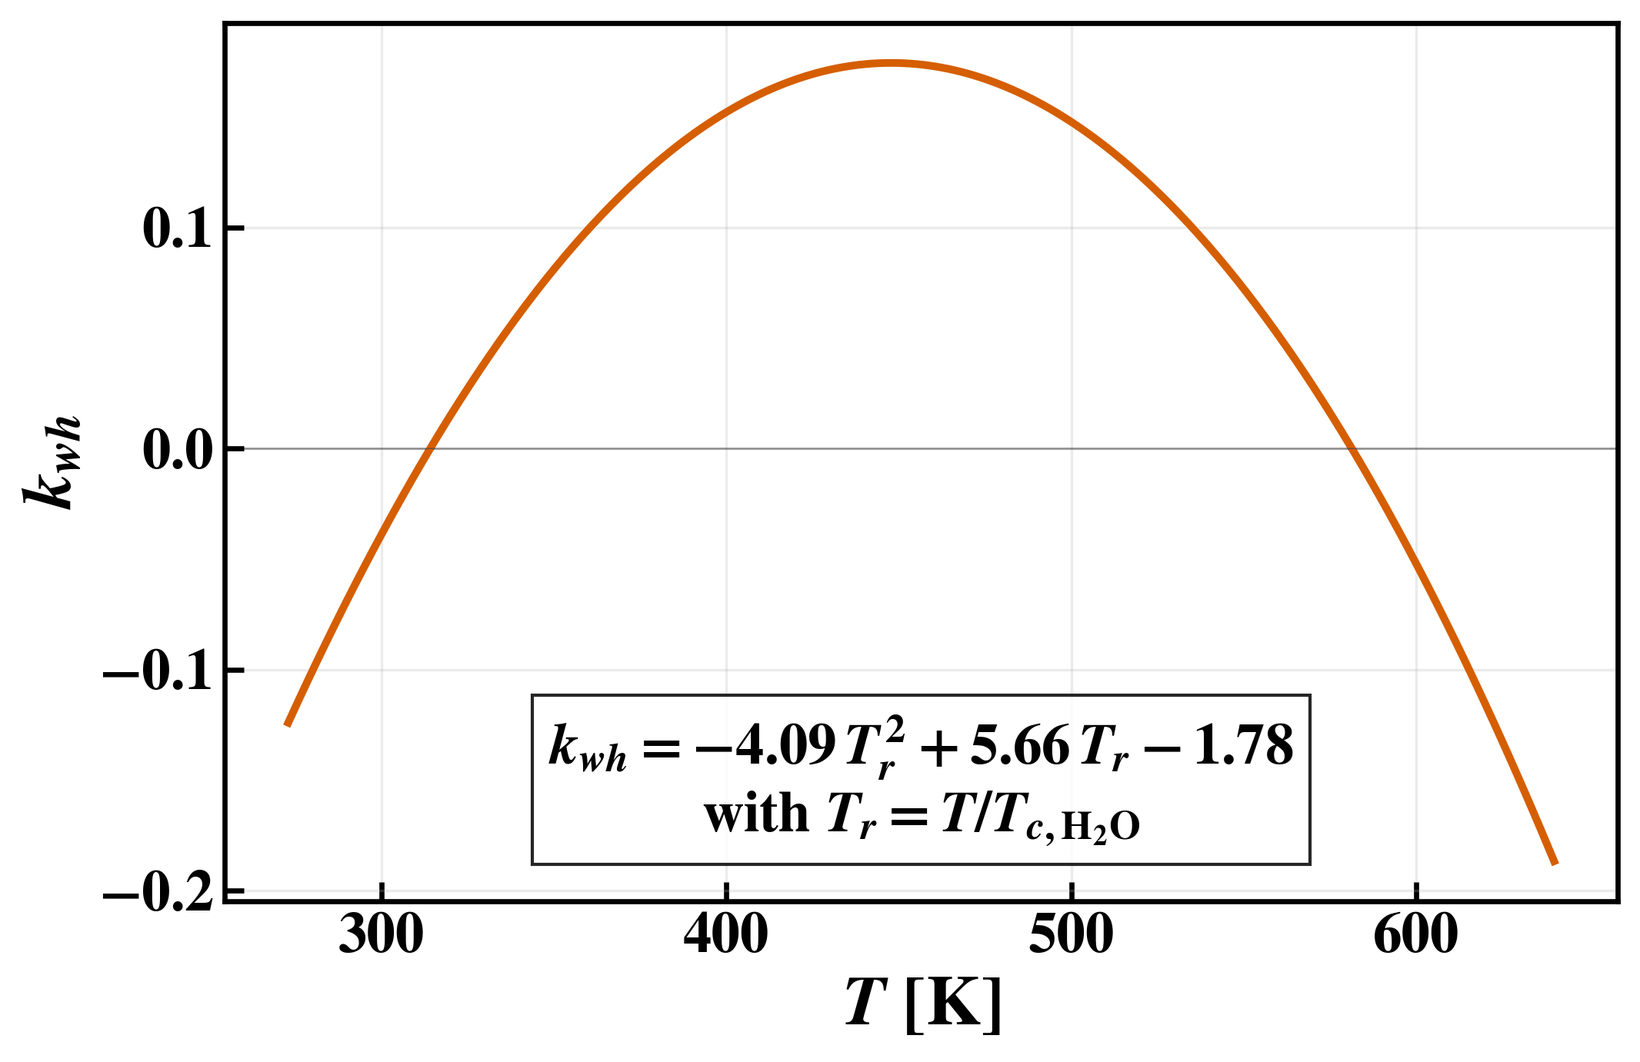

In [12]:
run('scripts/fig_param_fits.py')
show('kij_h2o_ch4.png')


<a id="sfigS1"></a>

**Figure S1.** Temperature-dependent binary interaction parameter for $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ after optimization.

This section collects the CPA/eCPA ion-specific parameter values used throughout this work and the closed-form temperature dependences plotted in Figures S1–S4. The pure-component constants and the gas–water and gas–gas binary interaction parameters $k_{ij}$ are listed in Tables 1 and 2 of the main text, respectively; here we report the ion–solvent interaction energies $\Delta U_{wi}$ (from Schlaikjer et al.<sup>[5](#sref5)</sup>, except for the corrected $\mathrm{Ca^{2+}}$ row; Section S8) and the gas–ion interaction energies $\Delta U_{hi}$ and $\Delta U_{ci}$ (fitted in this work), followed by the ion-specific Péneloux volume-translation coefficients $\Upsilon_i(T)$ fitted to brine density.

Ion–solvent NRTL-type interactions follow a quadratic-in-temperature form for the water–ion pair,

$$\Delta U_{wi} = \Delta U^\text{ref}_{wi} + \alpha_{wi}\thinspace R\negthinspace \left[ \left(1-\frac{T}{T^\alpha_{wi}}\right)^2 -\left(1-\frac{T^\text{ref}}{T^\alpha_{wi}}\right)^2 \right], \tag{S15}$$

and a linear form for the gas–ion pairs,

$$\Delta U_{hi} = A^{\Delta U}_{hi}\negthinspace \left(\frac{T}{T_{c,h}}\right) + B^{\Delta U}_{hi}, \qquad \Delta U_{ci} = A^{\Delta U}_{ci}\negthinspace \left(\frac{T}{T_{c,c}}\right) + B^{\Delta U}_{ci}. \tag{S16}$$

The water–ion coefficients are taken from Schlaikjer et al.<sup>[5](#sref5)</sup>; the new gas–ion coefficients fitted in this work are listed in Table S3. Figures S2 and S3 show the optimized $\Delta U_{hi}$ and $\Delta U_{ci}$ as functions of temperature.


<a id="stabS3"></a>

**Table S3.** Ion–solvent and ion–gas interaction parameters used in the CPA/eCPA mixing rule. Water–ion coefficients ($\Delta U^\text{ref}_{wi}$, $\alpha_{wi}$, $T^\alpha_{wi}$) are from Schlaikjer et al.<sup>[5](#sref5)</sup>; $\mathrm{CH_{4}}$–ion and $\mathrm{CO_{2}}$–ion coefficients are fitted in this work. <sup>a</sup>$\mathrm{Ca^{2+}}$ water–ion reference energy refit together with the corrected $\mathrm{Ca^{2+}}$ hard-sphere diameter and Born radius, and $\mathrm{CH_{4}}$–$\mathrm{Ca^{2+}}$ / $\mathrm{CO_{2}}$–$\mathrm{Ca^{2+}}$ reference energies co-refit accordingly against the same VLE data (Section S8).

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Ion</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>Δ</em><em>U</em><sub><em>w</em><em>i</em></sub><sup>ref</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>α</em><sub><em>w</em><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>T</em><sub><em>w</em><em>i</em></sub><sup><em>α</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>A</em><sub><em>h</em><em>i</em></sub><sup><em>Δ</em><em>U</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>B</em><sub><em>h</em><em>i</em></sub><sup><em>Δ</em><em>U</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>A</em><sub><em>c</em><em>i</em></sub><sup><em>Δ</em><em>U</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>B</em><sub><em>c</em><em>i</em></sub><sup><em>Δ</em><em>U</em></sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">(kJ mol<span class="math inline"><sup>−1</sup></span>)</td>
<td style="padding:2px 8px;border:none;text-align:left">(K)</td>
<td style="padding:2px 8px;border:none;text-align:left">(K)</td>
<td style="padding:2px 8px;border:none;text-align:left">(kJ mol<span class="math inline"><sup>−1</sup></span>)</td>
<td style="padding:2px 8px;border:none;text-align:left">(kJ mol<span class="math inline"><sup>−1</sup></span>)</td>
<td style="padding:2px 8px;border:none;text-align:left">(kJ mol<span class="math inline"><sup>−1</sup></span>)</td>
<td style="padding:2px 8px;border:none;text-align:left">(kJ mol<span class="math inline"><sup>−1</sup></span>)</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Na<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.76</span></td>
<td style="padding:2px 8px;border:none;text-align:left">1449</td>
<td style="padding:2px 8px;border:none;text-align:left">260.8</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">16.06</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.59</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">5.51</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">5.99</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Cl<sup>−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.83</span></td>
<td style="padding:2px 8px;border:none;text-align:left">1579</td>
<td style="padding:2px 8px;border:none;text-align:left">413.1</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">1.37</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">1.51</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">8.08</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−3.11</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">K<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.45</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−2770</span></td>
<td style="padding:2px 8px;border:none;text-align:left">999.9</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">8.36</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.40</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">12.06</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−3.55</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Ca<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.97<sup><em>a</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">377</td>
<td style="padding:2px 8px;border:none;text-align:left">492.9</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">2.52</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">17.46<sup><em>a</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−2.77</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">6.05<sup><em>a</em></sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Mg<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">3.66</span></td>
<td style="padding:2px 8px;border:none;text-align:left">207</td>
<td style="padding:2px 8px;border:none;text-align:left">102.5</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">20.34</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.020</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">11.54</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">SO<sub>4</sub><sup>2−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.0056</span></td>
<td style="padding:2px 8px;border:none;text-align:left">5392</td>
<td style="padding:2px 8px;border:none;text-align:left">433.6</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">4.81</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−14.73</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">27.43</span></td>
</tr>
</tbody>
</table>


In [13]:
# The values of Table S3 as they are set in ms_ecpa/parameters.py
import pandas as pd
import ms_ecpa.parameters as p

k = lambda x, d=2: "—" if x == 0 else f"{x / 1000:.{d}f}"
show_table(pd.DataFrame([{
    "Ion": ion, "ΔU_ref,wi (kJ/mol)": f"{p.Uref1i[i] / 1000:.4g}", "α_wi (K)": f"{p.alfa1i[i]:.0f}",
    "T^α_wi (K)": f"{p.Talfa1i[i]:.1f}", "A_hi (kJ/mol)": k(p.A_U2i[i]), "B_hi (kJ/mol)": k(p.B_U2i[i]),
    "A_ci (kJ/mol)": k(p.A_U3i[i], 3 if abs(p.A_U3i[i]) < 100 else 2), "B_ci (kJ/mol)": k(p.B_U3i[i])}
    for i, ion in enumerate(["Na⁺", "Cl⁻", "K⁺", "Ca²⁺", "Mg²⁺", "SO₄²⁻"])]))


Ion,"ΔU_ref,wi (kJ/mol)",α_wi (K),T^α_wi (K),A_hi (kJ/mol),B_hi (kJ/mol),A_ci (kJ/mol),B_ci (kJ/mol)
Na⁺,0.7604,1449,260.8,16.06,-1.59,5.51,5.99
Cl⁻,-1.831,1579,413.1,1.37,1.51,8.08,-3.11
K⁺,0.4454,-2770,999.9,8.36,-0.40,12.06,-3.55
Ca²⁺,0.9743,377,492.9,2.52,17.46,-2.77,6.05
Mg²⁺,3.658,207,102.5,—,20.34,-0.020,11.54
SO₄²⁻,0.00557,5392,433.6,—,4.81,-14.73,27.43


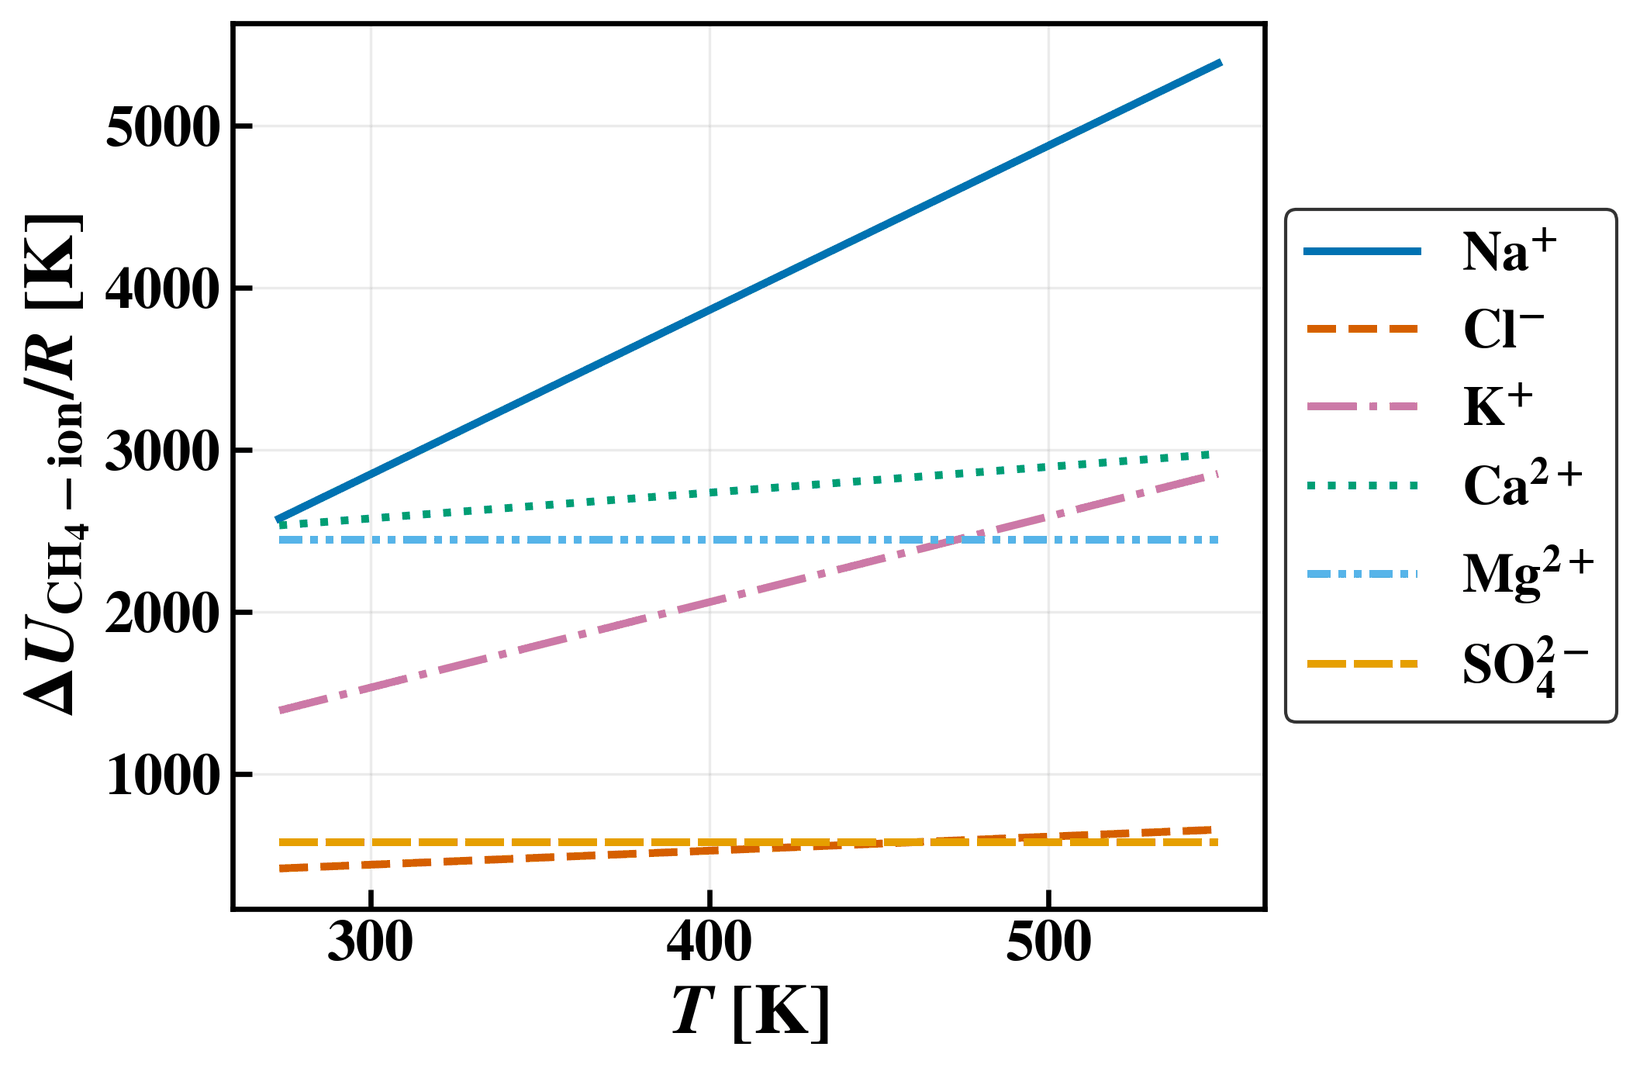

In [14]:
run('scripts/fig_param_fits.py')
show('delta_U_ch4_ions.png')


<a id="sfigS2"></a>

**Figure S2.** Binary interaction energy $\Delta U_{hi}$ between $\mathrm{CH_{4}}$ and each ion after optimization.

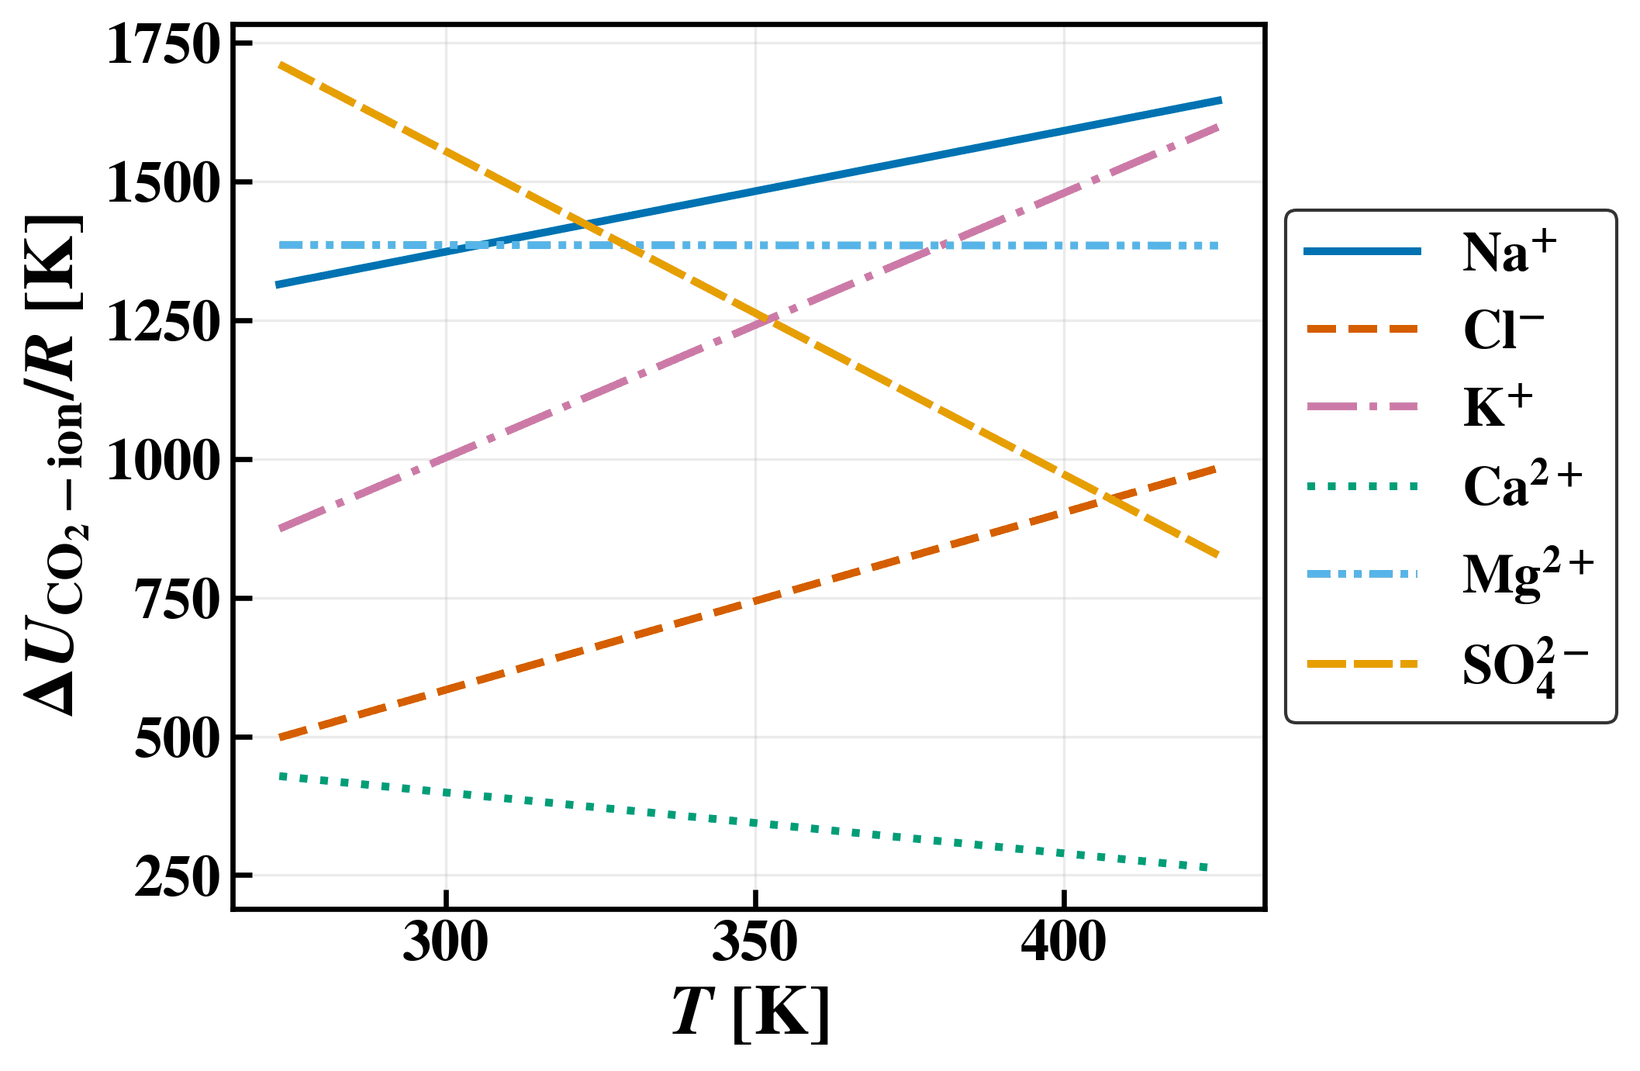

In [15]:
run('scripts/fig_param_fits.py')
show('delta_U_co2_ions.png')


<a id="sfigS3"></a>

**Figure S3.** Binary interaction energy $\Delta U_{ci}$ between $\mathrm{CO_{2}}$ and each ion after optimization.

Finally, the ion-specific temperature-dependent Péneloux volume translation coefficients defined in Eq. (18) of the main text and optimized against brine density are listed in Table S4; the corresponding $\Upsilon_i(T)$ curves are shown in Fig. S4.


<a id="stabS4"></a>

**Table S4.** Temperature-dependent Péneloux volume-translation coefficients fitted to the brine density data of Al Ghafri et al.<sup>[6](#sref6),[7](#sref7)</sup>. <sup>a</sup>$\mathrm{Ca^{2+}}$ constant re-anchored to the $\mathrm{CaCl_{2}}$ densities of Al Ghafri et al.<sup>[6](#sref6)</sup> after the correction of the $\mathrm{Ca^{2+}}$ row (Section S8).

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Ion</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>A</em><sub><em>i</em></sub><sup><em>Υ</em></sup></span> (cm<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−1</sup></span>)</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>B</em><sub><em>i</em></sub><sup><em>Υ</em></sup></span> (cm<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−1</sup></span>)</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Na<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−19.86</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−27.77</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Cl<sup>−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−15.79</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−30.59</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">K<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−63.65</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−7.07</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Ca<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">30.47</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−58.83<sup><em>a</em></sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Mg<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">46.75</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−105.77</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">SO<sub>4</sub><sup>2−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.80</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.27</span></td>
</tr>
</tbody>
</table>


In [16]:
# The values of Table S4 as they are set in ms_ecpa/parameters.py
import pandas as pd
import ms_ecpa.parameters as p

show_table(pd.DataFrame([{"Ion": ion, "A (cm³/mol)": f"{p.A_Peni[i]:.2f}", "B (cm³/mol)": f"{p.B_Peni[i]:.2f}"}
                         for i, ion in enumerate(["Na⁺", "Cl⁻", "K⁺", "Ca²⁺", "Mg²⁺", "SO₄²⁻"])]))


Ion,A (cm³/mol),B (cm³/mol)
Na⁺,-19.86,-27.77
Cl⁻,-15.79,-30.59
K⁺,-63.65,-7.07
Ca²⁺,30.47,-58.83
Mg²⁺,46.75,-105.77
SO₄²⁻,0.80,-1.27


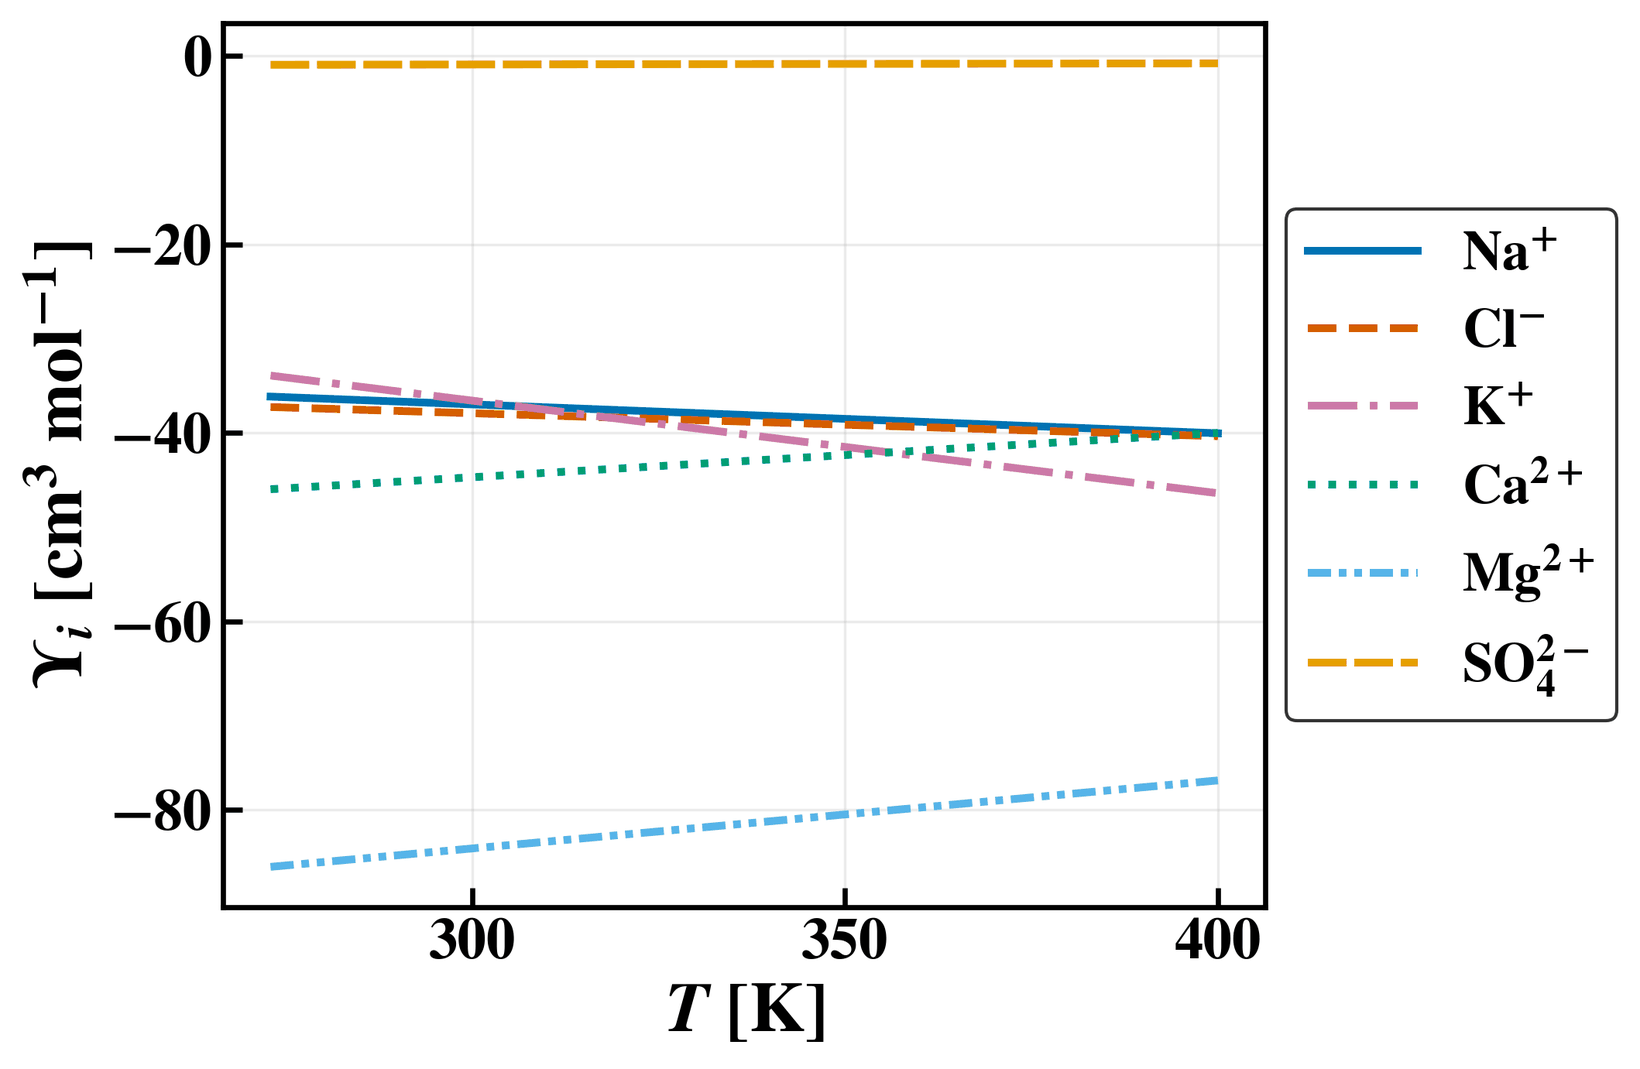

In [17]:
run('scripts/fig_param_fits.py')
show('peneloux_ions.png')


<a id="sfigS4"></a>

**Figure S4.** Optimized temperature-dependent Péneloux volume-translation coefficient $\Upsilon_i(T)$ for each ion.

<a id="ssecS7"></a>

## S7 Calibration data inventory

This section catalogs the full inventory of experimental data used to fit ms-ms-eCPA parameterization. The data span $\mathrm{CO_{2}}$–brine VLE (Table S5), the salt-free $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ binary (Table S6), and $\mathrm{CH_{4}}$–brine VLE (Table S7). For each source we list the temperature and pressure window, the salt molality range, the number of points $N_p$, and the resulting per-source AAD of the predicted gas solubility in brine.


<a id="ssecS7_1"></a>

### S7.1 Data collection, screening, and inter-source reproducibility

Every point in the tables below is transcribed from a published table and held in a plain-text file that names its source, so each row of the fitting set remains traceable to the publication it came from. Temperatures are recorded as measured rather than as the nominal isotherm, since a nominal $343$ K is a $70\thinspace ^{\circ}$C isotherm for one laboratory and $344.26$ K, a $160\thinspace ^{\circ}$F setting, for another. The same compilation, with its ion vectors and per-source provenance, is released as the open database GasBrineBench.

Screening is by rule, applied uniformly to every row, and each rule tests a row against itself rather than against the model. The concentration convention — molality or salt-free mole fraction — is read from each file’s own column header and normalized to a single basis; rows with missing or non-numeric fields are rejected; and the six-ion vector must satisfy electroneutrality to $|\sum_i z_i m_i| \le 10^{-6}\max(1, \sum_i |m_i|)$, which checks the transcribed brine composition for internal consistency.

No point is excluded for lying far from the model. The reason is measured rather than a matter of principle: the disagreement between independent laboratories at matched conditions is of the same size as the deviations the model is judged by. Comparing sources within the $\mathrm{CO_{2}}$–brine set at matched conditions — same six-ion composition, temperatures within $1$ K, one source’s isotherm interpolated linearly in pressure onto the other’s pressures inside the overlapping range — yields $223$ comparisons across $36$ distinct pairs of sources, with a median relative disagreement of $4.7$%, a mean of $6.5$%, and one comparison in ten above $16.3$%. The per-salt AAD of the model on the same data, in the table below, is $4.3$–$11.1$%. At $373$ K, near $50$ bar, in $1$ mol kg$^{-1}$ $\mathrm{NaCl}$, for example, Koschel et al.<sup>[10](#sref10)</sup>, Messabeb et al.<sup>[11](#sref11)</sup> and Yan et al.<sup>[13](#sref13)</sup> report $0.335$, $0.376$ and $0.428$ mol kg$^{-1}$ respectively, a span of $24.6$% about the median, and nothing in the data marks one of the three as erroneous. Deleting points that disagree with the model would lower the AAD values below by construction and would make them incomparable with AAD values published on full data sets. The per-source AAD column of each table instead shows which sources drive each salt’s average. The sources of the $\mathrm{CH_{4}}$–brine set overlap far less in condition, so no measured reproducibility floor is quoted for $\mathrm{CH_{4}}$.


<a id="stabS5"></a>

**Table S5.** Experimental $\mathrm{CO_{2}}$–brine VLE compared with the model, with the AAD of the predicted $\mathrm{CO_{2}}$ solubility in brine (AAD $= N_p^{-1}\sum |m_c^\text{calc}-m_c^\text{exp}|/m_c^\text{exp}$). Data are grouped by salt; the per-salt “Global” row summarises the cumulative $N_p$ and the point-weighted AAD for that salt. The gas–ion energies were fitted to the $511$ points at $323$, $373$ and $423$ K; the remaining points are out of sample.

In [18]:
import pandas as pd

run("scripts/build_paper_tables.py")
released = latex_table(nbtools.TAB / "tables" / "exp_co2_brine.tex", 6)
published = pd.read_csv("reproduce/published/paper_II_table_S5_exp_co2_brine.csv",
                        dtype=str, keep_default_na=False)
print("identical to the published table:", released.equals(published))
show_table(released)


identical to the published table: True


<a id="stabS6"></a>

**Table S6.** Experimental $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ VLE used in the CPA parameterization, with the resulting AAD of the predicted mutual solubilities of the aqueous ($W$) and $\mathrm{CH_{4}}$-rich ($H$) phases. $N_p^W$ and $N_p^H$ denote the number of points used for each phase.

In [19]:
import pandas as pd

run("scripts/build_paper_tables.py")
released = latex_table(nbtools.TAB / "tables" / "exp_ch4_h2o.tex", 7)
published = pd.read_csv("reproduce/published/paper_II_table_S6_exp_ch4_h2o.csv",
                        dtype=str, keep_default_na=False)
# The released code does not reproduce this published table (see
# multisalt/PUBLISHED_VS_RELEASED.md). Where the two differ, a cell holds the
# released value followed by the published one in parentheses.
show_table(nbtools.side_by_side(published, released, on=["group", "Reference"],
                                cols=["T (K)", "P (bar)", "N_p^W", "AAD^W (%)", "N_p^H", "AAD^H (%)"]))


Reference,T (K),P (bar),N_p^W,AAD^W (%),N_p^H,AAD^H (%)
CHAPOY2004,275–313,10–180,16,3.8,0,—
LEKVAM1997,275–286,6–91,15,6.7,0,—
OU2015,275–603,50–1400,204,6.6 (published: 8.0),0,—
Chapoy2005,278–298,5–44,0,—,21,3.4
BOTTGER2016,283–298,12–104,14,2.8,0,—
CHAPOY2003,283–318,10–346,0,—,39,51.3
Frost2014,283–323,48–195,21,11.8,21,17.3
WANG1995,283–298,11–52,21,4.0,0,—
WANG2003,283–303,20–400,17,4.7,0,—
Addicks2002,298,74–178,4,1.8,0,—


<a id="stabS7"></a>

**Table S7.** Experimental $\mathrm{CH_{4}}$–brine VLE used in the ms-eCPA parameterization, with the resulting AAD of the predicted $\mathrm{CH_{4}}$ solubility in brine (AAD $= N_p^{-1}\sum |m_h^\text{calc}-m_h^\text{exp}|/m_h^\text{exp}$). Data are grouped by salt; the per-salt “Global” row summarises the cumulative $N_p$ and the AAD averaged over all sources for that salt. Susak and McGee<sup>[45](#sref45)</sup> coverage extends up to $T = 598$ K via the “stability_flash” compute path in `scripts/build_paper_tables.py` (bypassing the `solve_elv` T = 533 K guess-table validity window).

In [20]:
import pandas as pd

run("scripts/build_paper_tables.py")
released = latex_table(nbtools.TAB / "tables" / "exp_ch4_brine.tex", 6)
published = pd.read_csv("reproduce/published/paper_II_table_S7_exp_ch4_brine.csv",
                        dtype=str, keep_default_na=False)
# The released code does not reproduce this published table (see
# multisalt/PUBLISHED_VS_RELEASED.md). Where the two differ, a cell holds the
# released value followed by the published one in parentheses.
show_table(nbtools.side_by_side(published, released, on=["group", "Reference"],
                                cols=["T (K)", "P (bar)", "m_s (m)", "N_p", "AAD (%)"]))


<a id="stabS8"></a>

**Table S8.** Salinity coverage of the data behind the parameterization. Molality ranges for the $\mathrm{CO_{2}}$-brine and $\mathrm{CH_{4}}$-brine sets are those of Tables S5 and S7; the density column is the Al Ghafri set of Section 2.3. $I_\text{max}$ is the ionic strength at the largest molality reached by any of the three, and $w_\text{max}$ the corresponding salt mass fraction.

In [21]:
import pandas as pd

run("scripts/build_paper_tables.py")
run("scripts/fig_brine_density.py")
co2 = latex_table(nbtools.TAB / "tables" / "exp_co2_brine.tex", 6)
ch4 = latex_table(nbtools.TAB / "tables" / "exp_ch4_brine.tex", 6)
rho = pd.read_parquet("results_cache/fig_brine_density_data.parquet").query("kind == 'model_at_exp'")

def global_m(t, group):
    g = t[(t["group"].str.replace(" ", "") == group) & t["Reference"].str.startswith("Global")]
    return g["m_s (m)"].iloc[0] if len(g) else "—"

# salt: (table group name, density key, ionic-strength factor, molar mass g/mol)
salts = {"NaCl": ("NaCl", "NaCl", 1, 58.44), "KCl": ("KCl", "KCl", 1, 74.55),
         "CaCl₂": ("CaCl₂", "CaCl", 3, 110.98), "MgCl₂": ("MgCl₂", "MgCl", 3, 95.21),
         "Na₂SO₄": ("Na₂SO₄", "NaSO", 3, 142.04), "MgSO₄": ("MgSO₄", None, 4, 120.37)}
rows = []
for salt, (grp, dk, f, M) in salts.items():
    mr = rho[rho.salt == dk]["m_salt_mol_kg"] if dk else pd.Series(dtype=float)
    ms = [float(x) for r in (global_m(co2, grp), global_m(ch4, grp)) if r != "—"
          for x in r.split("–")] + list(mr)
    m = max(ms)
    rows.append({"Salt": salt, "CO₂ brine m (mol/kg)": global_m(co2, grp),
                 "CH₄ brine m (mol/kg)": global_m(ch4, grp),
                 "density m (mol/kg)": f"{mr.min():.2f}–{mr.max():.2f}" if len(mr) else "—",
                 "I_max (w_max)": f"{f * m:.1f} ({100 * m * M / (1000 + m * M):.0f} %)"})
released = pd.DataFrame(rows)
published = pd.read_csv("reproduce/published/paper_II_table_S8_salinity_coverage.csv",
                        dtype=str, keep_default_na=False)
# The published lower
# ends of the CO2-brine ranges for NaCl, CaCl2 and MgCl2 do not agree with the
# published Table S5, which reaches 0.17, 0.09 and 0.11 mol/kg; the CH4 ranges
# differ because GasBrineBench v1.1.1 adds data (see PUBLISHED_VS_RELEASED.md).
# Where the two differ, a cell holds the released value followed by the
# published one in parentheses.
show_table(nbtools.side_by_side(published, released, on=["Salt"], cols=list(released.columns[1:])))


Salt,CO₂ brine m (mol/kg),CH₄ brine m (mol/kg),density m (mol/kg),I_max (w_max)
NaCl,0.17–6 (published: 1–6),0.5–6 (published: 0.5–4.3),1.06–6.00,6.0 (26 %)
KCl,0.5–4.5,0.5–4,1.06–4.49,4.5 (25 %)
CaCl₂,0.09–6 (published: 0.67–6),0.25–5.6 (published: 0.5–2),1.00–6.00,18.0 (40 %)
MgCl₂,0.11–5 (published: 0.67–5),0.5–2.2,1.00–5.00,15.0 (32 %)
Na₂SO₄,0.67–2.7,0.5–1,0.78–1.50,8.1 (28 %)
MgSO₄,—,0.5–1.5,—,6.0 (15 %)


<a id="ssecS8"></a>

## S8 Ion-parameter provenance and the $\mathrm{Ca^{2+}}$ correction

This section documents the provenance of the ion-specific parameters, the colligative verification of the adopted set, and the evidence behind the two corrections introduced in this work (the $\mathrm{Ca^{2+}}$ row and the $\mathrm{Mg^{2+}}$ polarizability; Section 2.4 of the main text).


<a id="ssecS8_1"></a>

### S8.1 Provenance of the ion parameters

The ion hard-sphere diameters $\sigma_i$, Born radii $R_{B,i}$, water–ion energies $\Delta U_{wi}$, and Péneloux shifts are adopted from Table 4 of Schlaikjer et al.<sup>[5](#sref5)</sup>; the polarizabilities $\alpha_{0,i}$ are from Maribo-Mogensen et al.<sup>[4](#sref4)</sup>. Every adopted value was verified digit-for-digit against these primary sources. None of the $\sigma_i$ or $R_{B,i}$ are physical constants: Schlaikjer et al.<sup>[5](#sref5)</sup> document $\sigma_i$ as fitted outcomes of their 55-salt optimization and $R_{B,i}$ as adjusted to hydration enthalpies. Table S9 places the printed values next to the community reference scales — the bare-ion diameters of Marcus<sup>[59](#sref59)</sup> and Shannon<sup>[60](#sref60)</sup>, the hydrated-ion ePC-SAFT diameters of Held et al.<sup>[61](#sref61)</sup>, the covalent Born radii of Rashin and Honig<sup>[62](#sref62)</sup>, and the ab-initio free-ion polarizabilities of Pyper et al.<sup>[63](#sref63)</sup> — together with the values adopted in this work where they differ from the printed row. Two anomalies stand out: the printed $\sigma_{\mathrm{Ca}} = 1.17$ Å lies below every physical scale (and inverts the $\mathrm{Mg}$/$\mathrm{Ca}$ size ordering of every reference scale), and $\alpha_0(\mathrm{Mg^{2+}})$ cannot be traced in any of the primary sources and equals the $\mathrm{Ca^{2+}}$ value. The Born radii, by contrast, sit within ${\sim}0.13$ Å of the Rashin and Honig<sup>[62](#sref62)</sup> values for the cations, reflecting the hydration-enthalpy constraint under which they were adjusted.


<a id="stabS9"></a>

**Table S9.** Ion parameters against physical reference scales. “Printed” columns: Schlaikjer et al.<sup>[5](#sref5)</sup> Table 4 verbatim ($\alpha_0$ from Maribo-Mogensen et al.<sup>[4](#sref4)</sup>); “adopted” columns: values corrected in this work (blank = printed value retained). Reference scales: bare-ion diameters $2R_\text{ion}$ of Marcus<sup>[59](#sref59)</sup> and Shannon<sup>[60](#sref60)</sup>, hydrated-ion ePC-SAFT diameters of Held et al.<sup>[61](#sref61)</sup>, covalent Born radii of Rashin and Honig<sup>[62](#sref62)</sup>, and ab-initio free-ion polarizabilities of Pyper et al.<sup>[63](#sref63)</sup>. The $\mathrm{Ca^{2+}}$ correction also moves $\Delta U^\text{ref}_{w,\mathrm{Ca}}/R$ to $+117.2$ K (Table S3) and re-anchors the $\mathrm{Ca^{2+}}$ Péneloux constant (Table S4). Boldface marks the anomalous printed entries discussed in Sections S8.3–S8.4.

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td colspan="5" style="padding:2px 8px;border:none;text-align:center"><span class="math inline"><em>σ</em></span> [Å]</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td colspan="3" style="padding:2px 8px;border:none;text-align:center"><span class="math inline"><em>R</em><sub><em>B</em></sub></span> [Å]</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td colspan="3" style="padding:2px 8px;border:none;text-align:center"><span class="math inline"><em>α</em><sub>0</sub></span> [<span class="math inline">10<sup>−40</sup></span> C<span class="math inline"><sup>2</sup></span> m<span class="math inline"><sup>2</sup></span> J<span class="math inline"><sup>−1</sup></span>]</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Ion</td>
<td style="padding:2px 8px;border:none;text-align:left">printed</td>
<td style="padding:2px 8px;border:none;text-align:left">adopted</td>
<td style="padding:2px 8px;border:none;text-align:left"><sup><a href="#sref59">59</a></sup></td>
<td style="padding:2px 8px;border:none;text-align:left"><sup><a href="#sref60">60</a></sup></td>
<td style="padding:2px 8px;border:none;text-align:left"><sup><a href="#sref61">61</a></sup></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">printed</td>
<td style="padding:2px 8px;border:none;text-align:left">adopted</td>
<td style="padding:2px 8px;border:none;text-align:left"><sup><a href="#sref62">62</a></sup></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">printed</td>
<td style="padding:2px 8px;border:none;text-align:left">adopted</td>
<td style="padding:2px 8px;border:none;text-align:left"><sup><a href="#sref63">63</a></sup></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Na<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">2.63</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">2.04</td>
<td style="padding:2px 8px;border:none;text-align:left">2.04</td>
<td style="padding:2px 8px;border:none;text-align:left">2.41</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">1.54</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">1.68</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">2.221</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">0.165</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Cl<sup>−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">3.57</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">3.60</td>
<td style="padding:2px 8px;border:none;text-align:left">3.62</td>
<td style="padding:2px 8px;border:none;text-align:left">3.06</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">1.99</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">1.94</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">3.557</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">K<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">2.90</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">2.82</td>
<td style="padding:2px 8px;border:none;text-align:left">2.76</td>
<td style="padding:2px 8px;border:none;text-align:left">2.97</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">2.04</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">2.17</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">3.166</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">0.880</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Ca<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>1.17</strong></td>
<td style="padding:2px 8px;border:none;text-align:left">2.75</td>
<td style="padding:2px 8px;border:none;text-align:left">2.06</td>
<td style="padding:2px 8px;border:none;text-align:left">2.00</td>
<td style="padding:2px 8px;border:none;text-align:left">2.89</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">1.73</td>
<td style="padding:2px 8px;border:none;text-align:left">1.60</td>
<td style="padding:2px 8px;border:none;text-align:left">1.86</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">5.138</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">0.526</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Mg<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>3.42</strong></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">1.40</td>
<td style="padding:2px 8px;border:none;text-align:left">1.44</td>
<td style="padding:2px 8px;border:none;text-align:left">2.32</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">1.46</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">1.46</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>5.138</strong></td>
<td style="padding:2px 8px;border:none;text-align:left">1.61</td>
<td style="padding:2px 8px;border:none;text-align:left">0.080</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">SO<sub>4</sub><sup>2−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">3.14</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">4.84</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.45</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">2.40</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">5.775</td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
</tbody>
</table>


<a id="ssecS8_2"></a>

### S8.2 Colligative verification

The adopted parameter set was verified against the osmotic-coefficient standard at 298.15 K and 1 bar. The osmotic coefficient is computed from the total-mole water activity exactly as the published formulation defines it — the ions are ordinary mole-counted components of the aqueous equation of state, and $\ln a_w = \ln f_w^\text{brine}(T,P) - \ln f_w^\text{pure}(T,P)$, $\phi_\text{osm} = -55.5084 \ln a_w / (\nu m)$ — and compared with the Pitzer ion-interaction correlations using the constants of Pitzer and Mayorga<sup>[64](#sref64)</sup>. Implementation fidelity was established independently of the comparison itself: every Helmholtz contribution of the model (Huron–Vidal mixing, Wertheim association, Debye–Hückel, Born, and the permittivity closure) was checked against separate re-implementations of the published equations, matching to a few parts in $10^{4}$ in $\ln\hat\phi_w$; the Debye–Hückel limiting law is recovered essentially exactly ($\phi_\text{osm}(0.001\thinspace m \mathrm{NaCl}) = 0.9882$ against the Pitzer value 0.9884); and the computed $\mathrm{Na_{2}SO_{4}}$ curve reproduces the source paper’s own published curve to within ${\sim}0.01$ in $\phi_\text{osm}$ at both 298 and 373 K. On this basis, $\mathrm{NaCl}$, $\mathrm{KCl}$, $\mathrm{MgCl_{2}}$, and $\mathrm{Na_{2}SO_{4}}$ reproduce the accuracies reported by the parameter set’s original authors (Table 3 of the main text), and the $\mathrm{CaCl_{2}}$ discrepancy discussed next is attributable to the printed $\mathrm{Ca^{2+}}$ row itself rather than to the implementation. Figure S5 shows the five-salt comparison over the full plotted molality ranges.


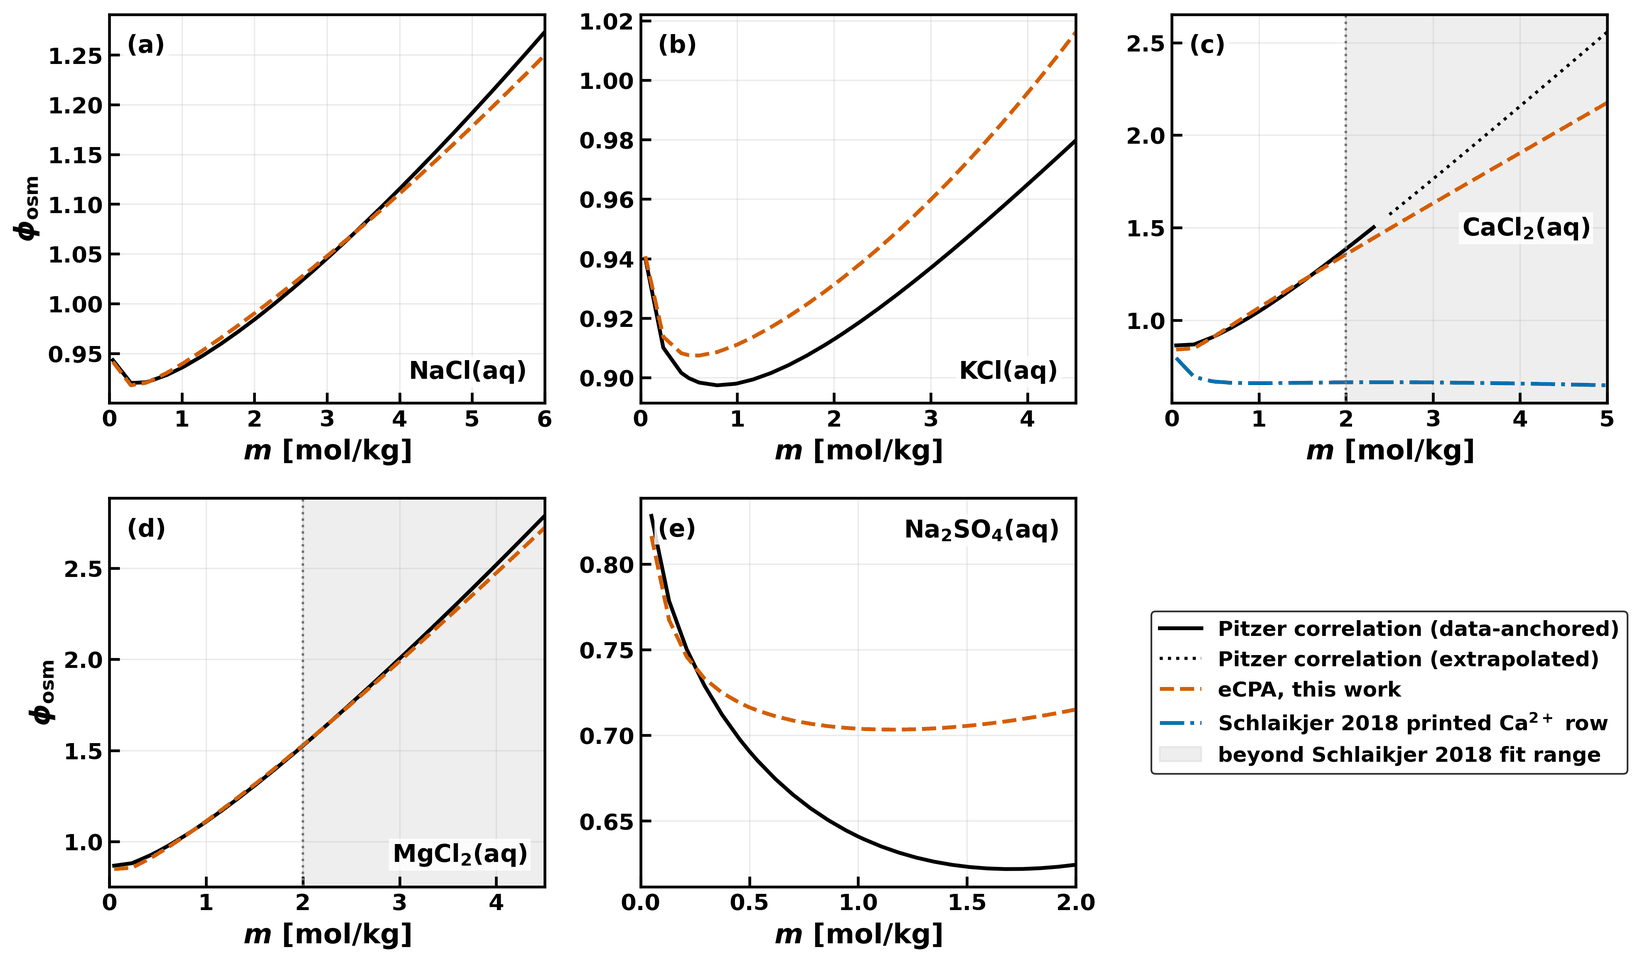

In [22]:
run('scripts/fig_colligative.py')
show('colligative_SI.png')


<a id="sfigS5"></a>

**Figure S5.** Osmotic coefficient at 298.15 K for the five brines of this work: Pitzer correlation with the Pitzer and Mayorga<sup>[64](#sref64)</sup> constants (solid within the molality range anchored to experimental data, dotted beyond) versus the ms-eCPA water activity with the adopted parameter set (dashed). Panel (c) additionally shows the printed $\mathrm{Ca^{2+}}$ row of Schlaikjer et al.<sup>[5](#sref5)</sup> (dash-dotted), superseded by the correction of Section S8.3. Gray shading marks molalities beyond the Schlaikjer et al.<sup>[5](#sref5)</sup> fit range for that salt.

<a id="ssecS8_3"></a>

### S8.3 The $\mathrm{Ca^{2+}}$ correction

With every Helmholtz term verified and every adopted input checked digit-for-digit against the printed tables, the $\mathrm{CaCl_{2}}$ osmotic coefficient computed with the printed $\mathrm{Ca^{2+}}$ row deviates from the Pitzer reference by -27.0%, -37.0%, and -52.1% at $m = 0.5$, $1$, and $2$ mol kg$^{-1}$ — inside the fit range for which Schlaikjer et al.<sup>[5](#sref5)</sup> report a deviation of 5.0% (and Maribo-Mogensen et al.<sup>[8](#sref8)</sup> report 5.2% for $m \le 3$). The other divalent chloride of the suite, $\mathrm{MgCl_{2}}$, reproduces its reported accuracy under the same implementation, which rules out a divalent-cation limitation of the formulation. Plausible single-entry misprints were probed directly: setting $\sigma_{\mathrm{Ca}}$ to 2.17, 2.42, or 3.17 Å yields $\phi_\text{osm}(1\thinspace m) = 0.84$–$0.86$, and reversing the sign of $\Delta U^\text{ref}_{w,\mathrm{Ca}}$ yields 0.80, against the Pitzer target of 1.05; no single-entry correction closes the gap. The printed row is therefore internally inconsistent with the source paper’s own reported $\mathrm{CaCl_{2}}$ accuracy, in line with its unphysical $\sigma_{\mathrm{Ca}}$ (Table S9).

The origin of the inconsistency can be narrowed, though not settled from the published record alone.

*A unit or length-convention error is excluded on inspection.* The diameter $\sigma_i$ enters twice — as the Debye–Hückel size and, through $b_i = \tfrac{2}{3}\pi N_A \sigma_i^3$, as the SRK co-volume<sup>[5](#sref5)</sup> — so a factor-of-ten slip would change $b_{\mathrm{Ca}}$ by $10^3$ and be unmistakable. The one plausible convention slip, a radius printed where a diameter belongs ($\sigma_{\mathrm{Ca}} = 2.34$ Å), falls between the 2.17 and 2.42 Å probes above, both of which leave $\phi_\text{osm}(1\thinspace m)$ at 0.84–0.86.

*A single-entry typographical error is unlikely*, because the printed row fails in the shape of the curve and not only in its level. At 298.15 K, inside the molality range of the original fit, the Pitzer reference rises from 0.915 at $m = 0.5$ to 1.384 at $m = 2$ mol kg$^{-1}$, while the printed row gives 0.667, 0.659 and 0.664 at $m = 0.5$, 1 and 2 mol kg$^{-1}$ and stays flat beyond it; no adjustment of a single entry restores the slope. The anomaly is also local to $\mathrm{Ca^{2+}}$ rather than to a class of ions: $\mathrm{NaCl}$ and $\mathrm{KCl}$ exercise the same $\mathrm{Cl^{-}}$ row, and $\mathrm{MgCl_{2}}$ is likewise divalent, and all three reproduce the Pitzer reference at the level of the deviations reported for them.

*What remains is the parameter estimation*, on which the source paper is informative. In moving from a salt-specific to an ion-specific parameterization, $\sigma_i$ changed status from a literature value to an adjustable one constrained only to be positive, while the co-volume continued to be computed from it, so one number carries two physical roles<sup>[5](#sref5)</sup>. The printed $\sigma_{\mathrm{Ca}} = 1.17$ Å implies $b_{\mathrm{Ca}} = 2.02$ cm$^3$ mol$^{-1}$, one eleventh of $b_{\mathrm{Na}} = 22.94$ cm$^3$ mol$^{-1}$ from the same relation and one seventh of the co-volume carried for water in that work (14.52 cm$^3$ mol$^{-1}$). Schlaikjer et al.<sup>[5](#sref5)</sup> record that in estimating their 17-ion set against 55 salts a few ion parameters took values that were not physically reasonable, and that their procedure introduces ions one at a time, re-adjusting all previously estimated parameters at each addition before a final global adjustment. A printed row and a printed deviation belonging to different rounds of such a procedure would account for what is observed. The published record does not allow this reading to be distinguished from the alternatives.

The practical consequence is narrow. The comparison here uses the source’s own no-$k_{ij}$ column, 5.0% for $\mathrm{CaCl_{2}}$; the tabulated $\mathrm{Ca}$–$\mathrm{Cl}$ $k_{ij} = 0.4090$ brings it to 3.9% and does not change the picture. That figure is a whole-set average over 163 osmotic points from 273 to 445 K, while the deviations above are pointwise at 298.15 K, and the five other ion rows adopted here behave as their reported deviations lead one to expect. Only the $\mathrm{Ca^{2+}}$ row requires re-checking against a colligative standard before it is used for water activity; the bracketed replacement values below are offered for that purpose.

Because $\mathrm{Ca^{2+}}$ appears in no other salt of the suite, its parameters can be refit without affecting any other system (verified to machine precision). The triple $\lbrace \sigma_{\mathrm{Ca}}, R_{B,\mathrm{Ca}}, \Delta U^\text{ref}_{w,\mathrm{Ca}}\rbrace$ was refit against the Pitzer $\mathrm{CaCl_{2}}$ targets over the original fit range ($m \le 2$ mol kg$^{-1}$), with $\sigma_{\mathrm{Ca}}$ constrained to the crystallographic-to-hydrated bracket 2.0–2.9 Å<sup>[60](#sref60),[61](#sref61)</sup> and $R_{B,\mathrm{Ca}}$ anchored near the Rashin and Honig<sup>[62](#sref62)</sup> value. The result, $\sigma_{\mathrm{Ca}} = 2.75$ Å, $R_{B,\mathrm{Ca}} = 1.60$ Å, $\Delta U^\text{ref}_{w,\mathrm{Ca}}/R = +117.2$ K, restores the $\mathrm{CaCl_{2}}$ osmotic coefficient to 1.39% over the fit range. The physical bounds are essential: released without them, the fit migrates to $\sigma_{\mathrm{Ca}} = 4.24$ Å, which further improves the 298 K osmotic residual but severely degrades the predicted $\mathrm{CaCl_{2}}$ brine density — the same compensation behavior that plausibly produced the printed values in the first place. The $\mathrm{CaCl_{2}}$ density is restored to the accuracy of Section S5 by re-anchoring the single $\mathrm{Ca^{2+}}$ Péneloux constant (Table S4). A caveat carries over to any future refit: the 298 K osmotic data determine the $\mathrm{CaCl_{2}}$ curve more tightly than the individual parameter values (the optimum is a shallow $\sigma$–$\Delta U$ trade-off), so the corrected row should be read as the physically-bracketed first iteration of the full multi-property co-refit deferred to follow-up work.

The gas–ion interactions of this work were originally calibrated with the printed row in place and partially compensate for it, so adopting the corrected row requires co-refitting the $\mathrm{CO_{2}}$–$\mathrm{Ca^{2+}}$ and $\mathrm{CH_{4}}$–$\mathrm{Ca^{2+}}$ reference energies against the same experimental gas–brine data and with the same procedure as the original calibration. Table S10 traces the three configurations: the intermediate state (corrected row, unchanged gas–ion energies) degrades the gas solubilities exactly as the compensation picture predicts, and one refit reference energy per gas restores — in fact slightly improves — both, while the colligative column is untouched (no gas–ion parameter enters a gas-free brine). Table S11 lists the parameter changes; the temperature-dependence coefficients $A^{\Delta U}_{gi}$ did not need to move. The large shifts in the reference energies are expected: with a physically sensible water–$\mathrm{Ca^{2+}}$ description, much less gas–$\mathrm{Ca^{2+}}$ repulsion is required.


<a id="stabS10"></a>

**Table S10.** Effect of the $\mathrm{Ca^{2+}}$ correction on the $\mathrm{CaCl_{2}}$ observables. The middle row is the expected intermediate state: the original gas–$\mathrm{Ca^{2+}}$ energies were fitted with the printed row in place and compensate for it, so exchanging the row without refitting them degrades the gas side; one refit reference energy per gas restores both solubilities. The osmotic-coefficient column cannot be affected by the gas–ion refit. The third row is the configuration adopted in this work.

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Configuration</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline">CO<sub>2</sub></span>–<span class="math inline">CaCl<sub>2</sub></span> AAD (133 exp. points)</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline">CH<sub>4</sub></span>–<span class="math inline">CaCl<sub>2</sub></span> AAD (39 exp. points)</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline">CaCl<sub>2</sub></span> <span class="math inline"><em>ϕ</em><sub>osm</sub></span> RAD (<span class="math inline"><em>m</em> ≤ 2</span>, vs. Pitzer)</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">printed row <span class="math inline">+</span> original gas–ion fits</td>
<td style="padding:2px 8px;border:none;text-align:left">13.10%</td>
<td style="padding:2px 8px;border:none;text-align:left">4.93%</td>
<td style="padding:2px 8px;border:none;text-align:left">35.41%</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">corrected row <span class="math inline">+</span> original gas–ion fits</td>
<td style="padding:2px 8px;border:none;text-align:left">43.26%</td>
<td style="padding:2px 8px;border:none;text-align:left">26.47%</td>
<td style="padding:2px 8px;border:none;text-align:left">1.39%</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">corrected row <span class="math inline">+</span> refit gas–ion energies</td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>12.34%</strong></td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>4.72%</strong></td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>1.39%</strong></td>
</tr>
</tbody>
</table>


*Note on reproduction.* The values in this table come from the parameter study of the Ca²⁺ correction (Section S8.3), which is not part of the code release; the table is shown as published. The adopted parameters (the last row) are those of `ms_ecpa/parameters.py`, used by every other figure and table of this notebook.

<a id="stabS11"></a>

**Table S11.** Gas–ion reference energies $B^{\Delta U}_{gi}$ (Eq. S16) before and after the co-refit that accompanies the corrected $\mathrm{Ca^{2+}}$ row, with the corresponding gas-solubility deviations against the experimental data (same sets as Table S10). The temperature-dependence coefficients $A^{\Delta U}_{gi}$ are unchanged.

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Gas–ion pair</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>B</em><sub><em>g</em><em>i</em></sub><sup><em>Δ</em><em>U</em></sup></span>, original [J mol<span class="math inline"><sup>−1</sup></span>]</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>B</em><sub><em>g</em><em>i</em></sub><sup><em>Δ</em><em>U</em></sup></span>, refit [J mol<span class="math inline"><sup>−1</sup></span>]</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">AAD, printed row <span class="math inline">+</span> original fit</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">AAD, corrected row <span class="math inline">+</span> refit</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CO<sub>2</sub></span>–<span class="math inline">Ca<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">24425.6</td>
<td style="padding:2px 8px;border:none;text-align:left">6049.7</td>
<td style="padding:2px 8px;border:none;text-align:left">13.10%</td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>12.34%</strong></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CH<sub>4</sub></span>–<span class="math inline">Ca<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">33058.2</td>
<td style="padding:2px 8px;border:none;text-align:left">17458.1</td>
<td style="padding:2px 8px;border:none;text-align:left">4.93%</td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>4.72%</strong></td>
</tr>
</tbody>
</table>


*Note on reproduction.* The values in this table come from the parameter study of the Ca²⁺ correction (Section S8.3), which is not part of the code release; the table is shown as published. The adopted parameters (the last row) are those of `ms_ecpa/parameters.py`, used by every other figure and table of this notebook.

<a id="ssecS8_4"></a>

### S8.4 The $\mathrm{Mg^{2+}}$ polarizability

The polarizability $\alpha_0(\mathrm{Mg^{2+}})$ is absent from the primary sources (Maribo-Mogensen et al.<sup>[4](#sref4)</sup>, Maribo-Mogensen et al.<sup>[8](#sref8)</sup>, and the associated thesis), and the inherited value is a copy of the $\mathrm{Ca^{2+}}$ entry. Although $\alpha_0$ enters only the infinite-frequency permittivity, a direct scan shows that the copied value depresses the $\mathrm{MgCl_{2}}$ osmotic coefficient by 5–15% through the composition derivatives of the permittivity closure. Fitting $\alpha_0(\mathrm{Mg^{2+}})$ alone against the $\mathrm{MgCl_{2}}$ osmotic-coefficient targets — with the ion geometry untouched — gives $1.61 \times 10^{-40}$ C$^2$ m$^2$ J$^{-1}$, consistent with the expectation from the ab-initio free-ion value of Pyper et al.<sup>[63](#sref63)</sup> (the free $\mathrm{Mg^{2+}}$ polarizability is approximately seven-fold smaller than that of free $\mathrm{Ca^{2+}}$), and reduces the $\mathrm{MgCl_{2}}$ deviation from 5.2% to 1.2% with no measurable effect on the predicted density or gas solubility. Refitting the $\mathrm{Mg^{2+}}$ geometry instead does not work: the best $\sigma_{\mathrm{Mg}}$ inside the physical bracket fits worse and degrades both density and VLE, and an unconstrained fit again runs to an unphysical $\sigma \approx 4.2$ Å. The defect is the polarizability, not the size, and the value $1.61 \times 10^{-40}$ C$^2$ m$^2$ J$^{-1}$ is adopted in Table 1 of the main text.


<a id="ssecS8_5"></a>

### S8.5 $\mathrm{K^{+}}$ refinement and the $\mathrm{Na_{2}SO_{4}}$ limitation

For completeness, the same verification-and-refit procedure was applied to the remaining ions (with $\mathrm{Na^{+}}$ and $\mathrm{Cl^{-}}$ frozen at the printed values, so that each refit is confined to a single salt). For $\mathrm{K^{+}}$ the printed row is adequate — $\mathrm{KCl}$ already reproduces the reported accuracy (Table 3 of the main text) — and the refit serves as a control: released without bounds and from multiple starting points, it converges to a single optimum at $\sigma_{\mathrm{K}} = 2.65$ Å (just below the Shannon<sup>[60](#sref60)</sup> and Marcus<sup>[59](#sref59)</sup> diameters), $R_{B,\mathrm{K}} = 1.91$ Å, and $\Delta U^\text{ref}_{w,\mathrm{K}}/R = +114$ K, placing the $\mathrm{KCl}$ curve on the Pitzer reference to better than 0.1%. This refinement is available but is not adopted here, since the printed row meets the accuracy targets of this work.

For $\mathrm{Na_{2}SO_{4}}$ the adopted parameters match the original authors’ own no-$k_{ij}$ accuracy (8.57% against their reported 9.37%), and the computed curve reproduces their published curve rather than the experimental data. The remedy identified by the original authors — a $\mathrm{Na^{+}}$–$\mathrm{SO_{4}^{2-}}$ interaction ($k_{ij} = -0.48$ in their salt-specific variant) — corresponds to a single ion–ion energy, $\Delta U(\mathrm{Na^{+}},\mathrm{SO_{4}^{2-}})/R \approx -476$ K, which brings the 298 K deviation from 7.7% to 1.2% and the 373 K deviation from 10.2% to 3.6% with no effect on the volumetric properties. The Huron–Vidal mixing rule of this work carries water–ion and gas–ion energies only (Section 2.1 of the main text), so adopting this term requires a small, well-defined extension of the mixing rule; it is left to follow-up work. A water–ion refit is not a substitute: it can match the 298 K curve almost exactly but then misses 373 K by 18%, worse than the printed row.


<a id="ssecS9"></a>

## S9 Expanded validation

To validate the ms-eCPA model more rigorously than space in the main text permits, this section presents the full per-salt and per-source set of comparisons against literature data. Each subsection mirrors the corresponding subsection of Section 3 of the main text and provides additional figures at all calibration isotherms, salinities, and brine recipes used to compute the AAD statistics summarized there.


<a id="ssecS9_1"></a>

### S9.1 Brine density isotherms

The brine-density data of Al Ghafri et al.<sup>[6](#sref6),[7](#sref7)</sup> are shown below for the four single-salt brines ($\mathrm{KCl}$, $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$, $\mathrm{Na_{2}SO_{4}}$) not shown in Fig. 1 of the main text. Together with the $\mathrm{NaCl}$ panel of Fig. 1, the four figures in this subsection cover the full five-salt $\times$ three-isotherm grid (298, 348, 398 K) that anchors the brine-density performance summary in Section 3.1 of the main text.


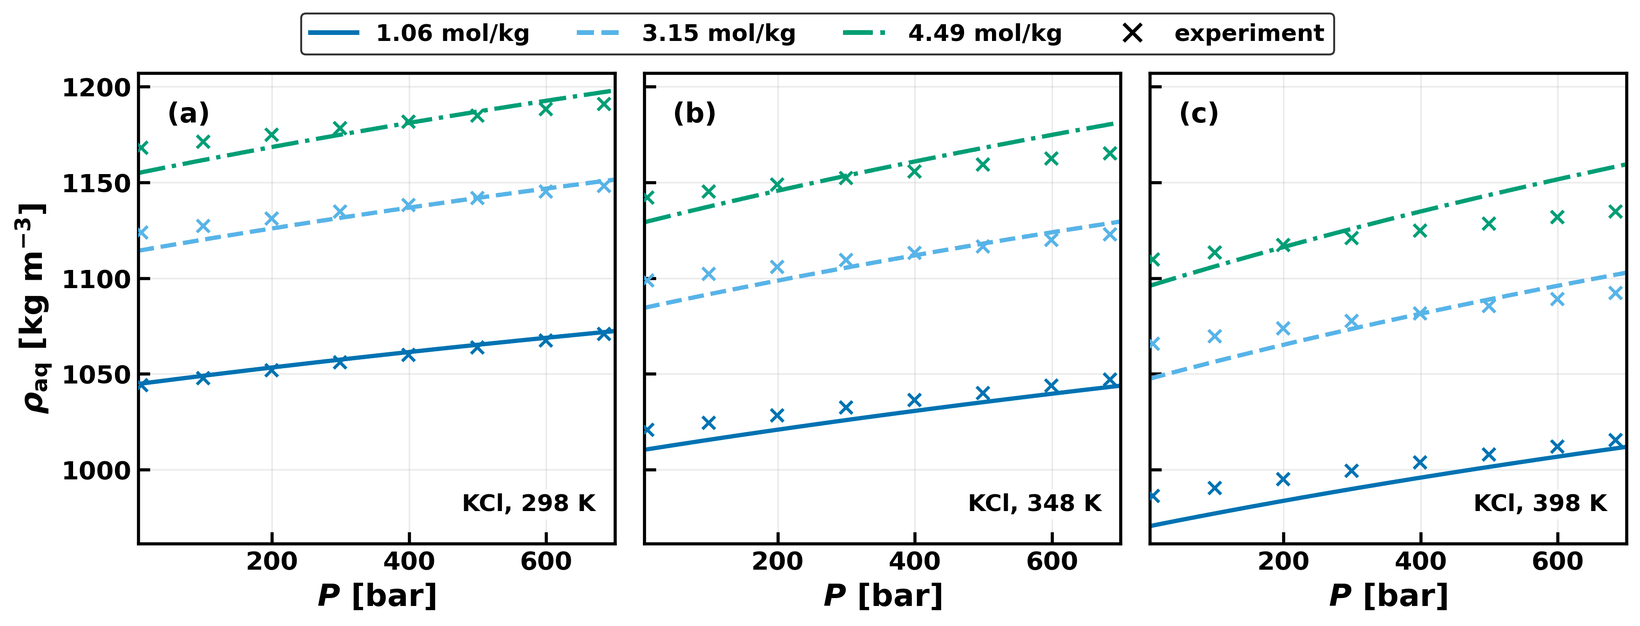

In [23]:
run('scripts/fig_brine_density.py')
show('brine_density_SI_KCl.png')


<a id="sfigS6"></a>

**Figure S6.** $\mathrm{KCl}$ brine density from ms-eCPA (continuous lines) and experiments<sup>[6](#sref6),[7](#sref7)</sup> (discrete symbols) at $T = 298$, 348, and 398 K.

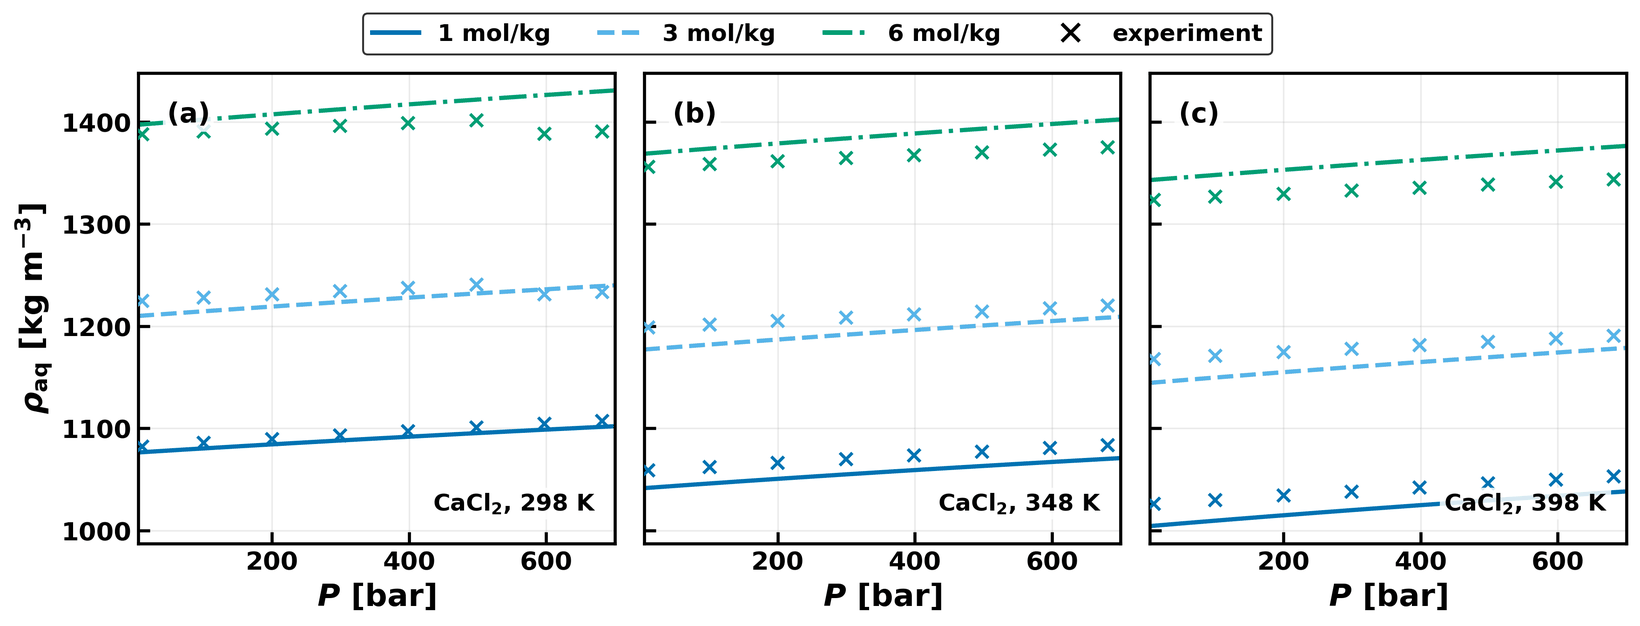

In [24]:
run('scripts/fig_brine_density.py')
show('brine_density_SI_CaCl.png')


<a id="sfigS7"></a>

**Figure S7.** $\mathrm{CaCl_{2}}$ brine density from ms-eCPA (continuous lines) and experiments<sup>[6](#sref6),[7](#sref7)</sup> (discrete symbols) at $T = 298$, 348, and 398 K.

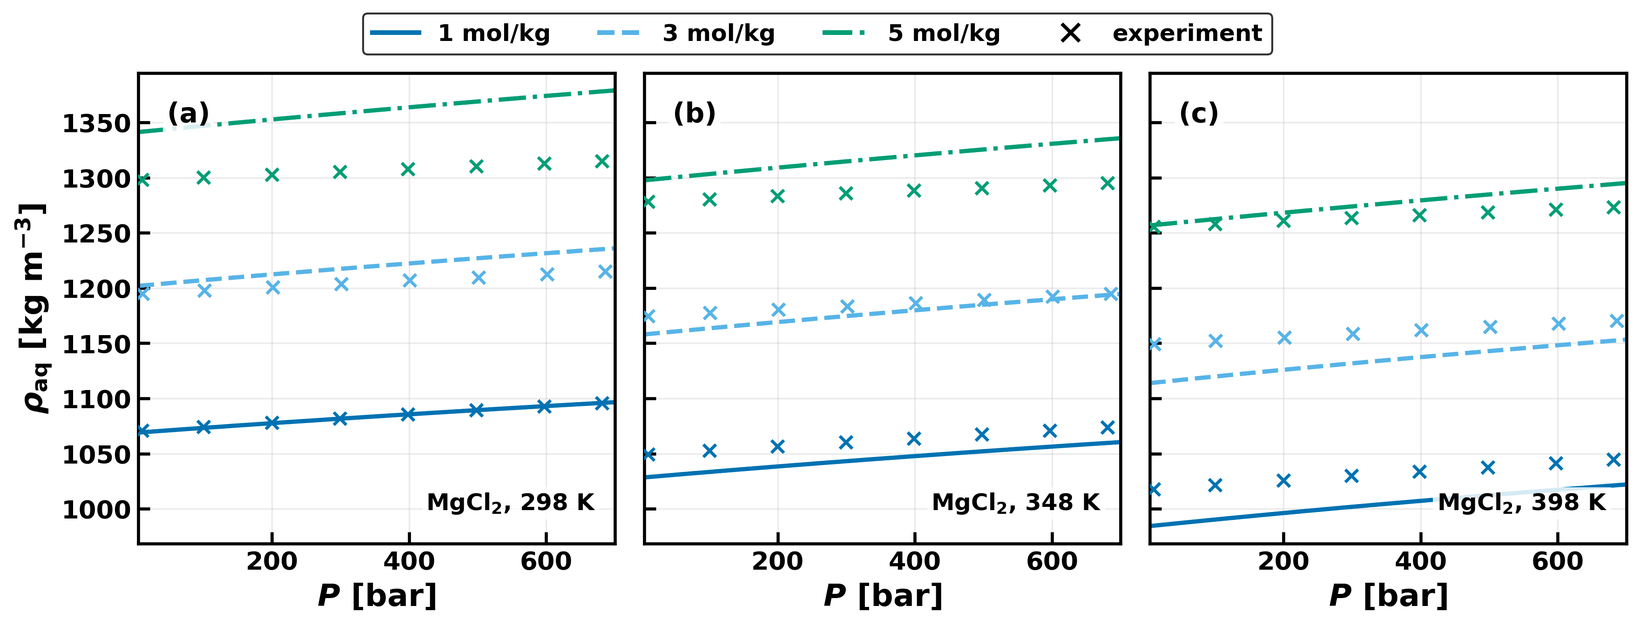

In [25]:
run('scripts/fig_brine_density.py')
show('brine_density_SI_MgCl.png')


<a id="sfigS8"></a>

**Figure S8.** $\mathrm{MgCl_{2}}$ brine density from ms-eCPA (continuous lines) and experiments<sup>[6](#sref6),[7](#sref7)</sup> (discrete symbols) at $T = 298$, 348, and 398 K.

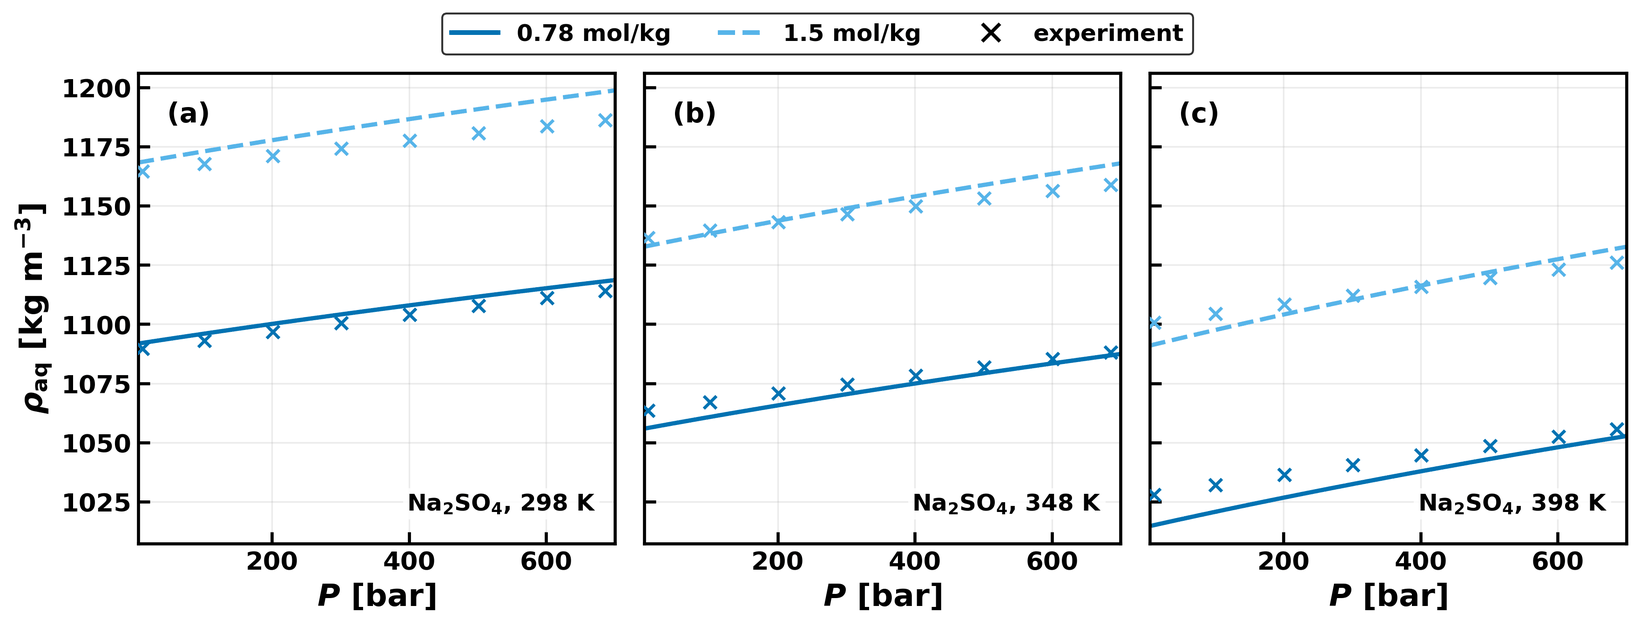

In [26]:
run('scripts/fig_brine_density.py')
show('brine_density_SI_NaSO.png')


<a id="sfigS9"></a>

**Figure S9.** $\mathrm{Na_{2}SO_{4}}$ brine density from ms-eCPA (continuous lines) and experiments<sup>[6](#sref6),[7](#sref7)</sup> (discrete symbols) at $T = 298$, 348, and 398 K. Together with the three additional brines above and the $\mathrm{NaCl}$ brine in the main text, this completes the five-salt brine-density validation summarized in Section 3.1 of the main text.

<a id="ssecS9_2"></a>

### S9.2 $\mathrm{CO_{2}}$ solubility in single-salt brines

The $\mathrm{CO_{2}}$-in-brine isotherms at 323, 373, and 423 K for all five single-salt brines ($\mathrm{NaCl}$, $\mathrm{KCl}$, $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$, $\mathrm{Na_{2}SO_{4}}$) are laid out below, one figure per salt (Figs. S10–S14). Together these cover every literature source and salinity that contributes to the per-salt AAD values reported in Table S5, of which Section 3.4 of the main text shows only the $\mathrm{NaCl}$, 323 K and $\mathrm{CaCl_{2}}$, 423 K representative panels (Fig. 4 of the main text).


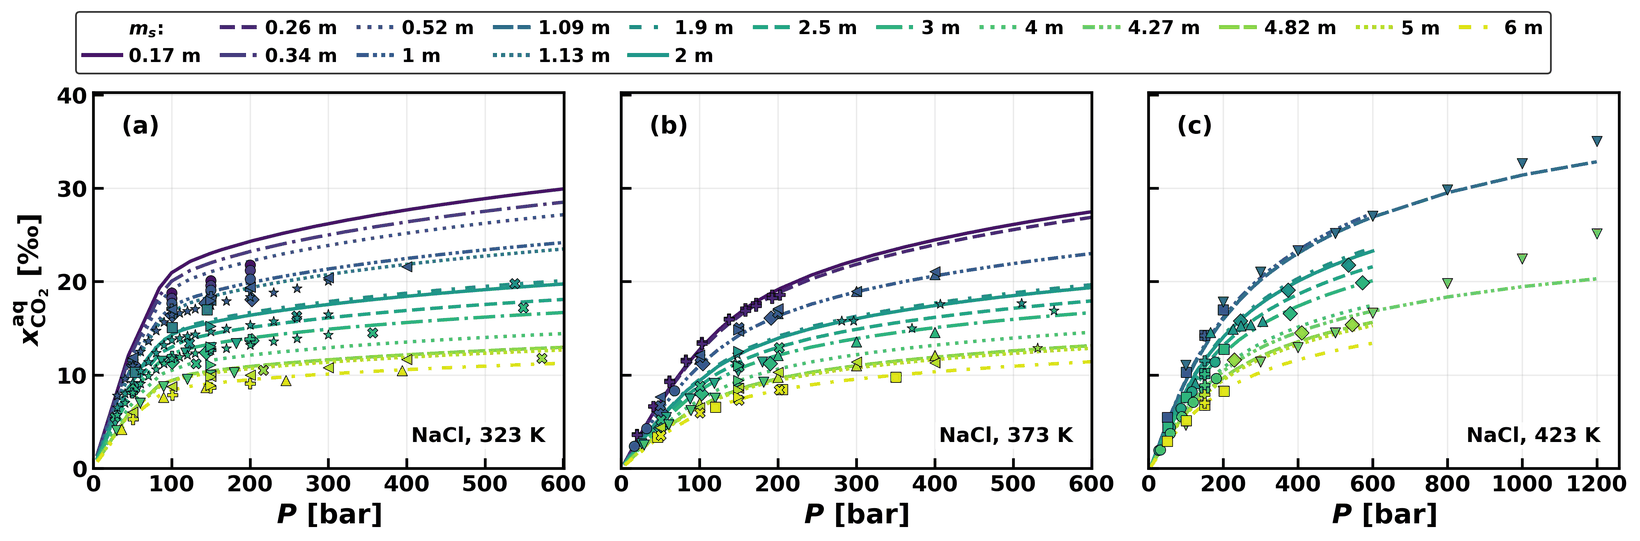

In [27]:
run('scripts/fig_co2_singlesalt.py')
show('co2_singlesalt_SI_NaCl.png')


<a id="sfigS10"></a>

**Figure S10.** $\mathrm{CO_{2}}$ solubility in $\mathrm{NaCl}$ brine from ms-eCPA (continuous lines) versus experiments (discrete symbols) at $T = 323$, 373, and 423 K. AAD reported in Table S5.

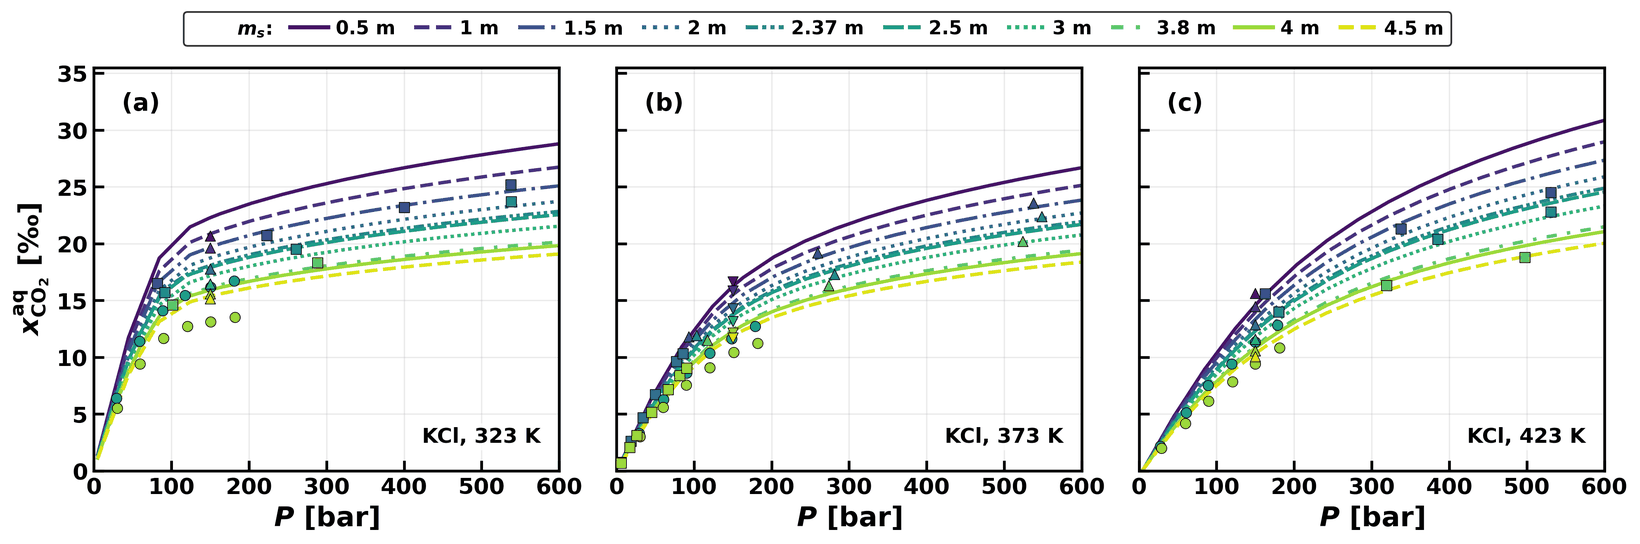

In [28]:
run('scripts/fig_co2_singlesalt.py')
show('co2_singlesalt_SI_KCl.png')


<a id="sfigS11"></a>

**Figure S11.** $\mathrm{CO_{2}}$ solubility in $\mathrm{KCl}$ brine from ms-eCPA (continuous lines) versus experiments (discrete symbols) at $T = 323$, 373, and 423 K.

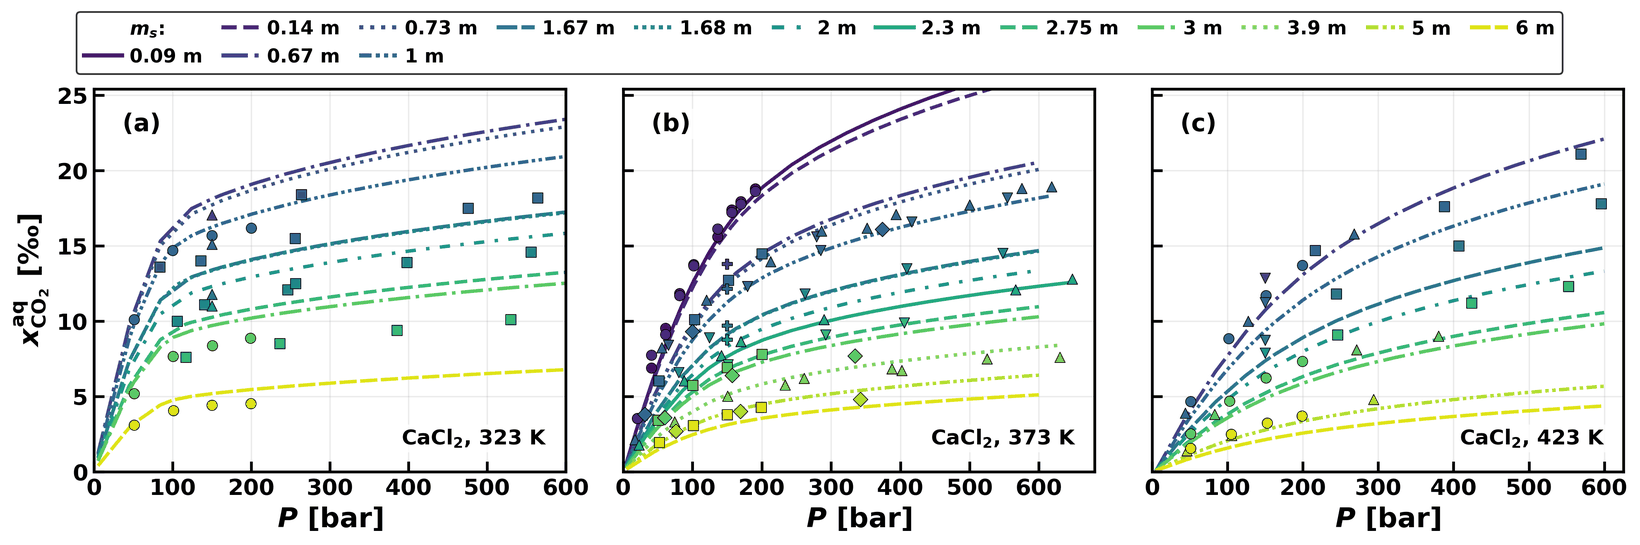

In [29]:
run('scripts/fig_co2_singlesalt.py')
show('co2_singlesalt_SI_CaCl.png')


<a id="sfigS12"></a>

**Figure S12.** $\mathrm{CO_{2}}$ solubility in $\mathrm{CaCl_{2}}$ brine from ms-eCPA (continuous lines) versus experiments (discrete symbols) at $T = 323$, 373, and 423 K.

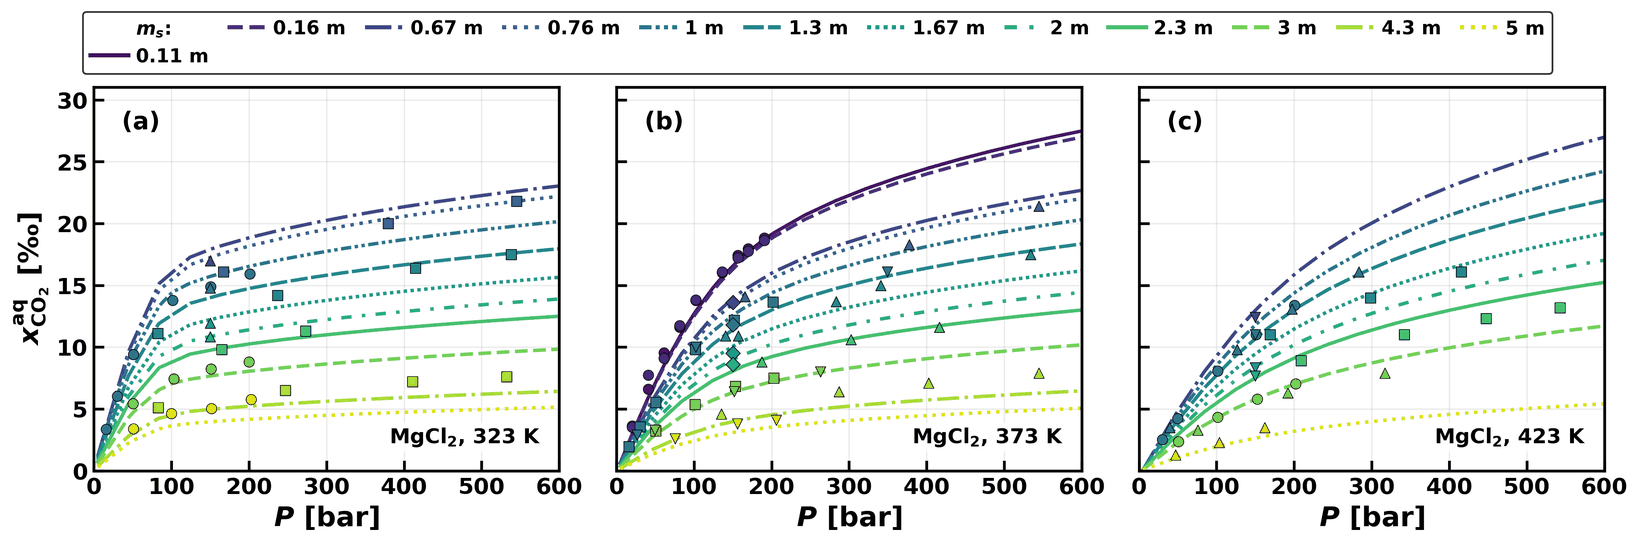

In [30]:
run('scripts/fig_co2_singlesalt.py')
show('co2_singlesalt_SI_MgCl.png')


<a id="sfigS13"></a>

**Figure S13.** $\mathrm{CO_{2}}$ solubility in $\mathrm{MgCl_{2}}$ brine from ms-eCPA (continuous lines) versus experiments (discrete symbols) at $T = 323$, 373, and 423 K.

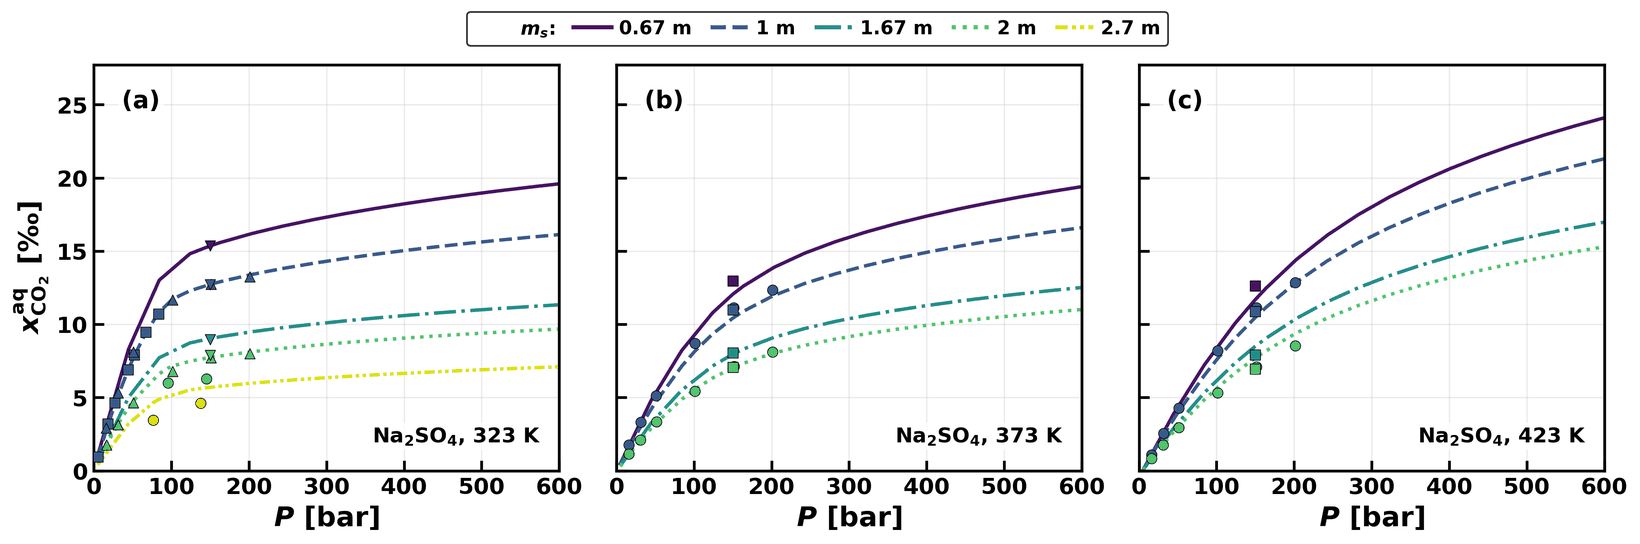

In [31]:
run('scripts/fig_co2_singlesalt.py')
show('co2_singlesalt_SI_NaSO.png')


<a id="sfigS14"></a>

**Figure S14.** $\mathrm{CO_{2}}$ solubility in $\mathrm{Na_{2}SO_{4}}$ brine from ms-eCPA (continuous lines) versus experiments (discrete symbols) at $T = 323$, 373, and 423 K.

<a id="ssecS9_3"></a>

### S9.3 $\mathrm{CH_{4}}$ solubility in single-salt brines

The $\mathrm{CH_{4}}$-in-brine validation is split into four figures, one per salt family: $\mathrm{NaCl}$ at all twelve calibration isotherms from 298 to 523 K (Fig. S15), $\mathrm{KCl}$ (Fig. S16), $\mathrm{CaCl_{2}}$ (Fig. S17), and the remaining three single-salt brines ($\mathrm{MgCl_{2}}$, $\mathrm{Na_{2}SO_{4}}$, $\mathrm{MgSO_{4}}$) collected in Fig. S18. The high-$T$ $\mathrm{NaCl}$ panels include the Susak and McGee<sup>[45](#sref45)</sup> calibration range up to 523 K and 1380 bar. Per-salt AADs and the literature sources are reported in Table S7; Section 3.5 of the main text shows only the $\mathrm{NaCl}$, 298 K and $\mathrm{CaCl_{2}}$, 343 K representative panels (Fig. 5 of the main text).


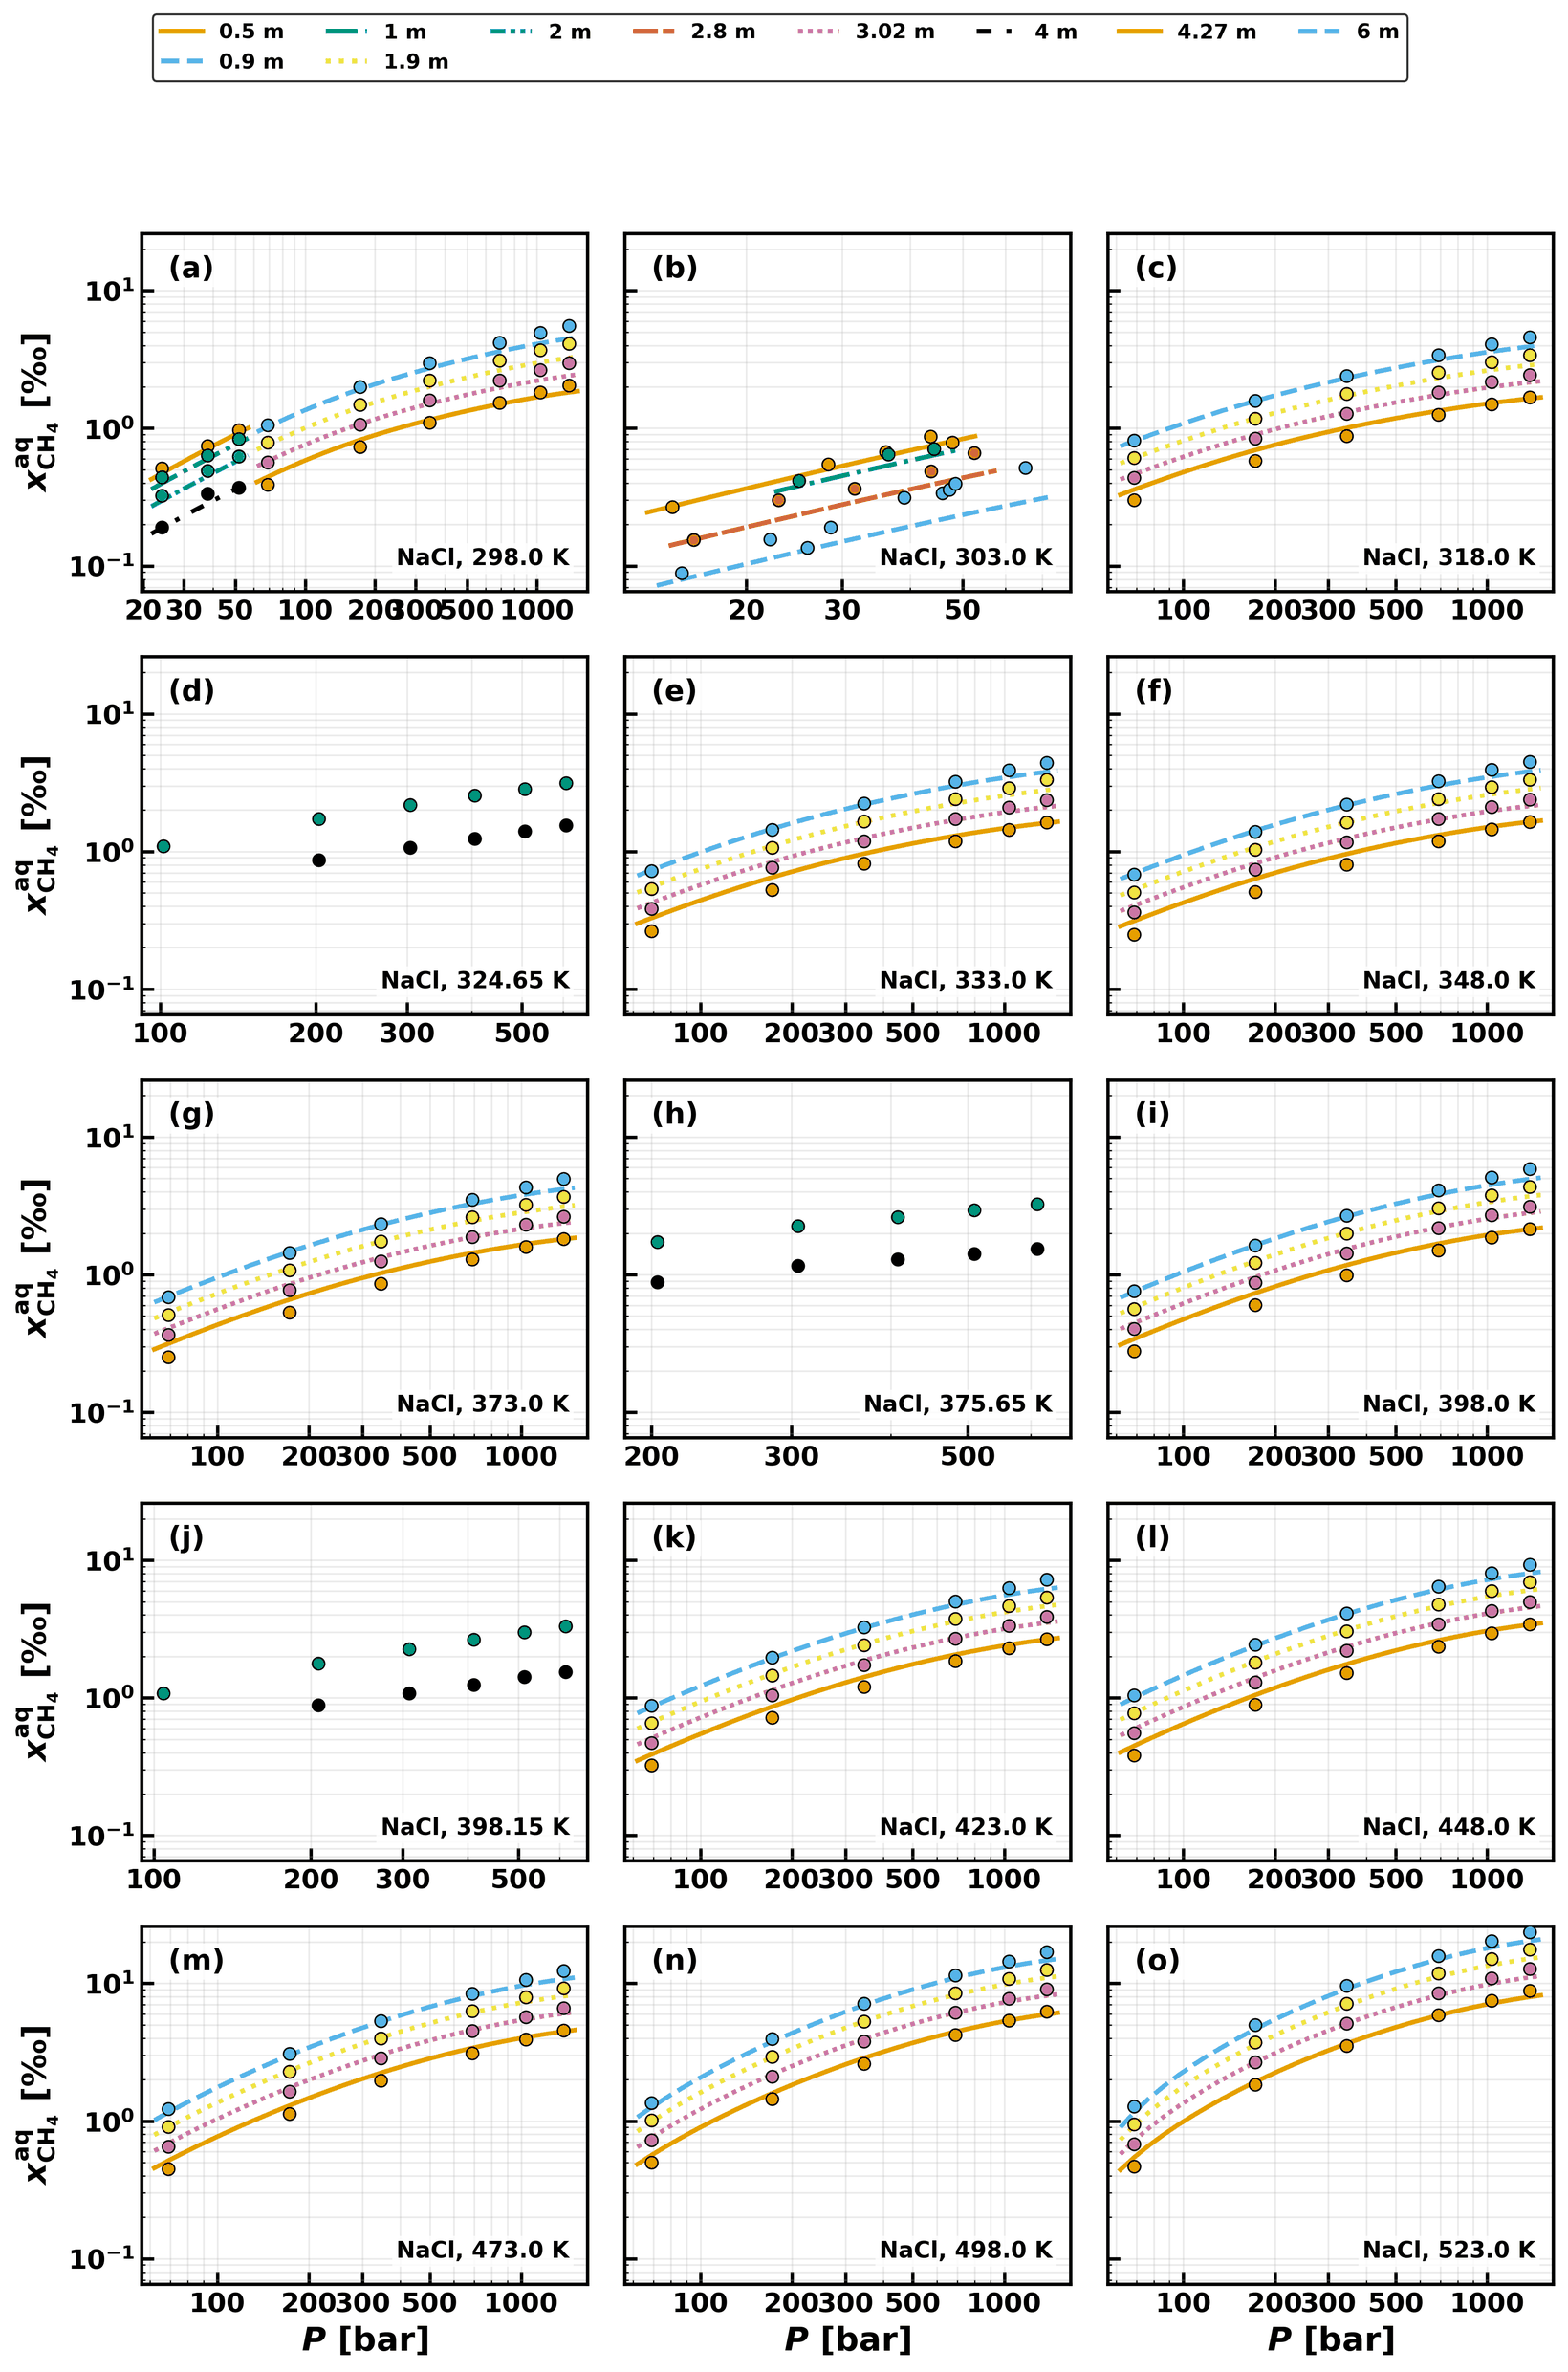

In [32]:
run('scripts/fig_ch4_singlesalt.py')
show('ch4_singlesalt_SI_NaCl.png')


<a id="sfigS15"></a>

**Figure S15.** $\mathrm{CH_{4}}$ solubility in $\mathrm{NaCl}$ brine from ms-eCPA (continuous lines) versus experiments<sup>[44](#sref44),[45](#sref45),[54](#sref54)</sup> (discrete symbols) at all twelve literature isotherms from 298 to 523 K. The high-$T$ panels cover the Susak and McGee<sup>[45](#sref45)</sup> calibration range up to 1380 bar.

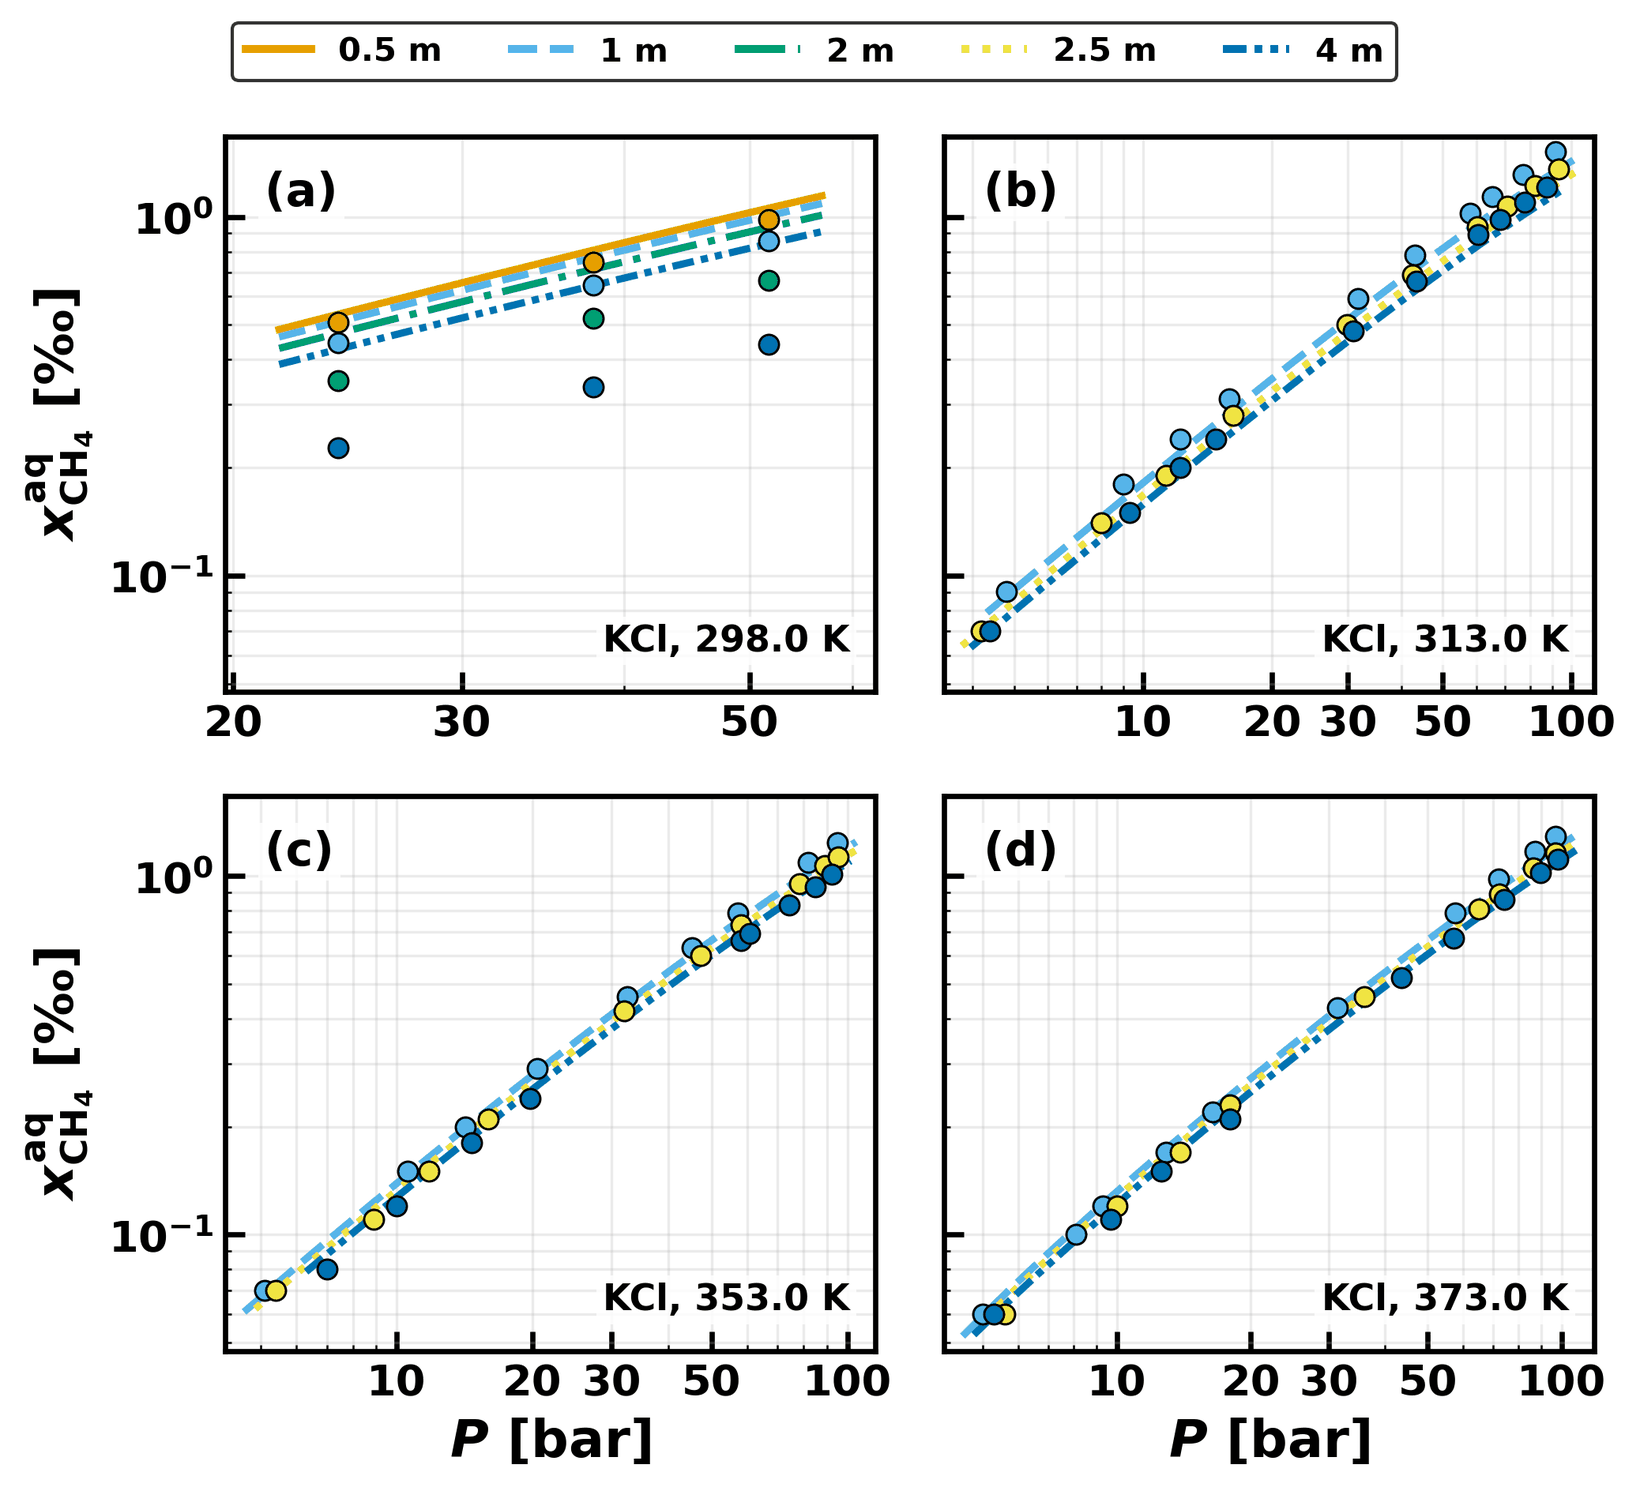

In [33]:
run('scripts/fig_ch4_singlesalt.py')
show('ch4_singlesalt_SI_KCl.png')


<a id="sfigS16"></a>

**Figure S16.** $\mathrm{CH_{4}}$ solubility in $\mathrm{KCl}$ brine from ms-eCPA (continuous lines) versus experiments<sup>[44](#sref44),[52](#sref52)</sup> (discrete symbols) at the four literature isotherms.

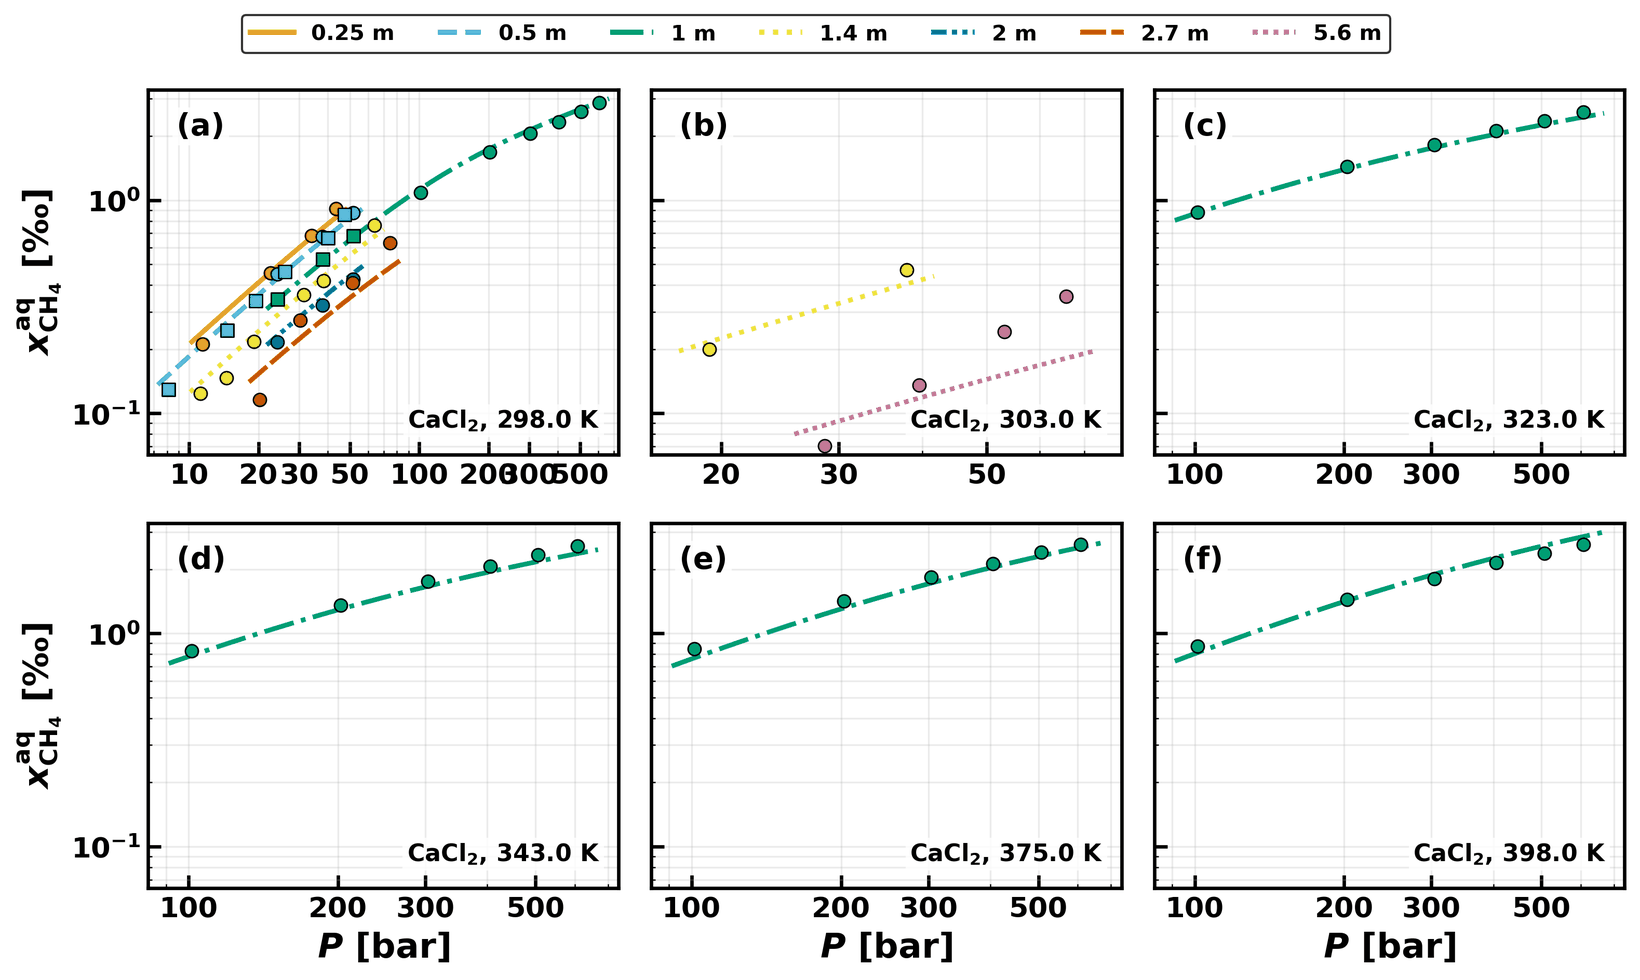

In [34]:
run('scripts/fig_ch4_singlesalt.py')
show('ch4_singlesalt_SI_CaCl2.png')


<a id="sfigS17"></a>

**Figure S17.** $\mathrm{CH_{4}}$ solubility in $\mathrm{CaCl_{2}}$ brine from ms-eCPA (continuous lines) versus experiments<sup>[44](#sref44),[58](#sref58)</sup> (discrete symbols) at the five literature isotherms.

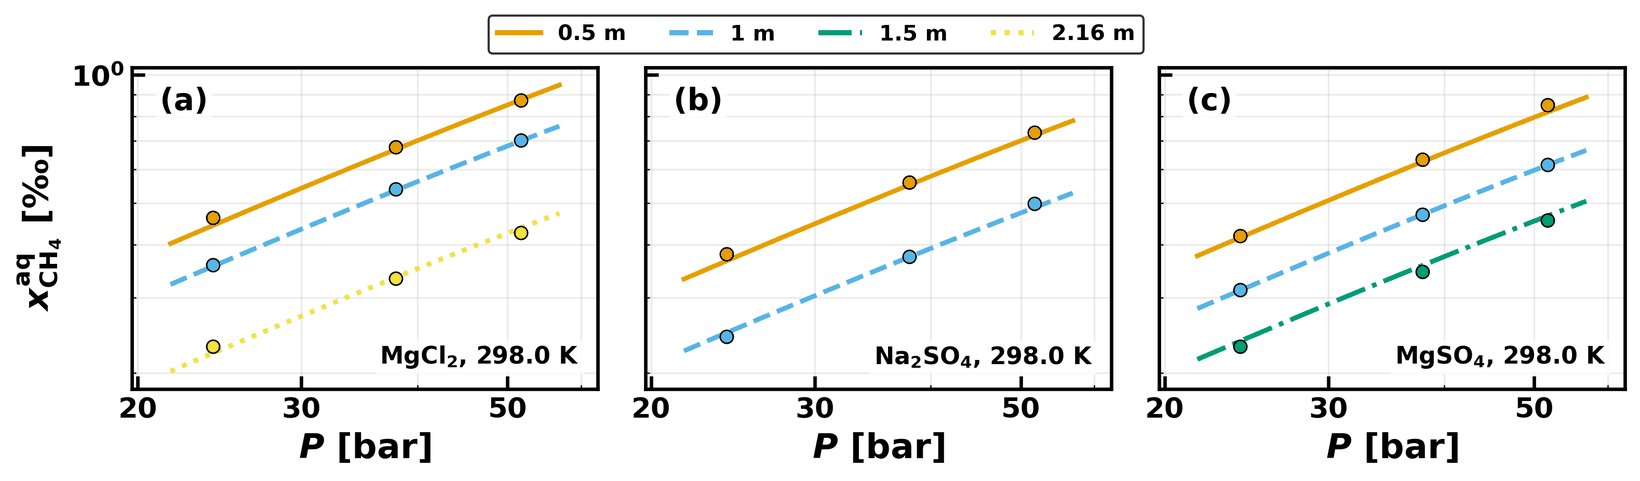

In [35]:
run('scripts/fig_ch4_singlesalt.py')
show('ch4_singlesalt_SI_other.png')


<a id="sfigS18"></a>

**Figure S18.** $\mathrm{CH_{4}}$ solubility in $\mathrm{MgCl_{2}}$, $\mathrm{Na_{2}SO_{4}}$, and $\mathrm{MgSO_{4}}$ brines from ms-eCPA (continuous lines) versus the experiments of Stoessell and Byrne<sup>[44](#sref44)</sup> (discrete symbols), each available only at 298 K.

<a id="ssecS9_4"></a>

### S9.4 Mixed-salt brines

The mixed-brine validation is split by literature reference into five figures: the six Liu et al.<sup>[65](#sref65)</sup> brines (Fig. S19), the four Wang et al.<sup>[66](#sref66)</sup> brines (Fig. S20), the Poulain et al.<sup>[67](#sref67)</sup> brines (Fig. S21), the Zhao et al.<sup>[68](#sref68)</sup> brines (Fig. S22), and a final figure for the five single-brine sources (El-Maghraby et al.<sup>[69](#sref69)</sup>, Li et al.<sup>[70](#sref70)</sup>, Portier and Rochelle<sup>[71](#sref71)</sup>, Mousavi et al.<sup>[72](#sref72)</sup>, Tong et al.<sup>[22](#sref22)</sup>; Fig. S23). Each of the five figures compares measured $\mathrm{CO_{2}}$ solubility (discrete symbols, one color per isotherm) with the model (continuous lines of the same color) for one author’s brines, with one panel per author–brine recipe; the header of each panel gives the source, the recipe — the ion molalities and the ionic strength $I_c$ — and the average absolute deviation of the model for that recipe. Section 3.6 of the main text shows the two representative panels (Liu et al.<sup>[65](#sref65)</sup> B1 and Wang et al.<sup>[66](#sref66)</sup> B1; Fig. 6 of the main text).


<a id="stabS12"></a>

**Table S12.** AAD of the predicted $\mathrm{CO_{2}}$ molality for each of the nineteen mixed-brine recipes, grouped by literature source and ordered as in Figs. S19–S23. $I_c$ is the stoichiometric ionic strength of the recipe, AAD $= 100\thinspace N_p^{-1}\sum|m_{\mathrm{CO_{2}}}^{\text{calc}}-m_{\mathrm{CO_{2}}}^{\text{exp}}|          /m_{\mathrm{CO_{2}}}^{\text{exp}}$ in percent, and the subtotal and global rows are weighted by point. All $314$ points converge. No gas–ion or Péneloux coefficient was fitted to any point in this table. Sources marked $^{\dagger}$ also contributed single-salt measurements to the calibration set of Table S5; their mixed-salt points are nonetheless blind at the level of the individual datum. The mixed-salt brine of Mousavi et al.<sup>[72](#sref72)</sup> is the same material reported in the thesis of Teymouri<sup>[12](#sref12)</sup>, under which key its single-salt measurements appear in Table S5; the two are one dataset.

In [36]:
import numpy as np
import pandas as pd

SOURCES = {"LIU_2011": "Liu et al. (2011)", "WANG_2014": "Wang et al. (2014)",
           "POULANI_2019": "Poulain et al. (2019)", "ZHAOc_2015": "Zhao et al. (2015)",
           "ELMAGHRABY_2012": "El-Maghraby et al. (2012)", "LI_2004": "Li et al. (2004)",
           "PORTIER_2005": "Portier and Rochelle (2005)",
           "TEYMOURI_2017": "Mousavi et al. (2024)",      # same brine as Teymouri (2017)
           "TONG_2013": "Tong et al. (2013)"}
def recipe(mix_id):
    src, b = mix_id.rsplit("_", 1)
    return SOURCES[src], b

def num(v, d=1):
    """A value as printed in the tables: integers above 10 bar, a minus sign."""
    t = f"{v:.0f}" if d is None else f"{v:.{d}f}"
    return t.replace("-", "−")

def rng(values, d=1):
    lo, hi = num(min(values), d), num(max(values), d)
    if lo == hi:
        return lo
    # a range that involves a negative number reads "−2.5 to −2.3"
    return f"{lo} to {hi}" if "−" in lo + hi else f"{lo}–{hi}"

def prange(values, half_up=False):
    lo, hi = min(values), max(values)
    whole = (lambda v: str(int(v + 0.5))) if half_up else (lambda v: f"{v:.0f}")
    f = lambda v: f"{v:.2g}" if v < 10 else whole(v)
    return f(lo) if f(lo) == f(hi) else f"{f(lo)}–{f(hi)}"

run("scripts/fig_co2_mixed_brines.py")
d = pd.read_parquet("results_cache/fig_co2_mixed_brines_data.parquet").query("kind == 'exp'")
Z2 = {"m_Na": 1, "m_Cl": 1, "m_K": 1, "m_Ca": 4, "m_Mg": 4, "m_SO4": 4}
rows = []
for src in SOURCES:
    sub = d[d.mix_id.str.rsplit("_", n=1).str[0] == src]
    for mix_id, s in sub.groupby("mix_id", sort=True):
        name, b = recipe(mix_id)
        rows.append({"Source": name, "Recipe": b,
                     "I_c (m)": f"{0.5 * sum(s[c].iloc[0] * z for c, z in Z2.items()):.2f}",
                     "T (K)": rng(s.T_K, None), "P (bar)": prange(s.P_bar, half_up=True), "N_p": len(s),
                     "AAD (%)": f"{100 * np.mean(np.abs(s.mc_pred - s.mc_exp) / s.mc_exp):.1f}"})
    if sub.mix_id.nunique() > 1:
        rows.append({"Source": "source subtotal", "N_p": len(sub),
                     "AAD (%)": f"{100 * np.mean(np.abs(sub.mc_pred - sub.mc_exp) / sub.mc_exp):.1f}"})
rows.append({"Source": "All recipes", "T (K)": rng(d.T_K, None), "P (bar)": prange(d.P_bar, half_up=True),
             "N_p": len(d), "AAD (%)": f"{100 * np.mean(np.abs(d.mc_pred - d.mc_exp) / d.mc_exp):.1f}"})
print("converged:", int(d.converged.sum()), "of", len(d), "points")
show_table(pd.DataFrame(rows).fillna(""))


converged: 314 of 314 points


Source,Recipe,I_c (m),T (K),P (bar),N_p,AAD (%)
Liu et al. (2011),B1,1.01,308–328,21–159,24,4.2
Liu et al. (2011),B2,2.13,308–328,24–157,24,3.3
Liu et al. (2011),B3,3.20,308–328,13–156,27,3.8
Liu et al. (2011),B4,1.70,318,25–160,8,4.0
Liu et al. (2011),B5,2.45,318,25–160,8,3.8
Liu et al. (2011),B6,2.25,318,21–159,8,4.0
source subtotal,,,,,99,3.8
Wang et al. (2014),B1,1.29,318–348,80–110,16,5.4
Wang et al. (2014),B2,0.31,318–348,80–110,16,9.8
Wang et al. (2014),B3,0.95,318–348,80–110,16,6.0


Table S12 reports the accuracy (AAD) for all the mixed-brine recipes. Sixteen of the nineteen recipes lie between $2.5$% and $9.8$%, and the accuracy does not degrade with salinity: the two most concentrated recipes, at $I_c = 5.89$ and $4.98$ m, score $8.9$% and $2.5$%, and all three recipes above $10$% have $I_c < 1$ m. Those three are of two kinds. For Portier and Rochelle<sup>[71](#sref71)</sup> B1 ($12.8$%) and Wang et al.<sup>[66](#sref66)</sup> B4 ($10.7$%) the deviation is a one-sided offset rather than scatter: $33$ of the $35$ Portier points and $15$ of the $16$ Wang B4 points lie below the computed curve, and the signed mean deviations, $+12.4$% and $+10.5$%, account for almost the whole AAD in each case. The Portier set includes repeated measurements ($29$ of its $35$ points fall in ten groups at a common $(T,P)$), but those repeats agree with each other to $2.9$% expressed as a mean absolute deviation about the group mean — the same basis as the AAD — so the repeatability of the data bounds only a small part of the offset. For El-Maghraby et al.<sup>[69](#sref69)</sup> B1 ($13.6$%, six points) the deviations change sign with temperature, positive at $306$ and $323$ K and negative at all four $343$ K points; the largest one is at $3.4$ bar, the lowest pressure in the compilation, where the measured solubility is $0.045$ mol kg$^{-1}$ and the computed value $0.034$ mol kg$^{-1}$, and the remaining five points still average $11.3$%.


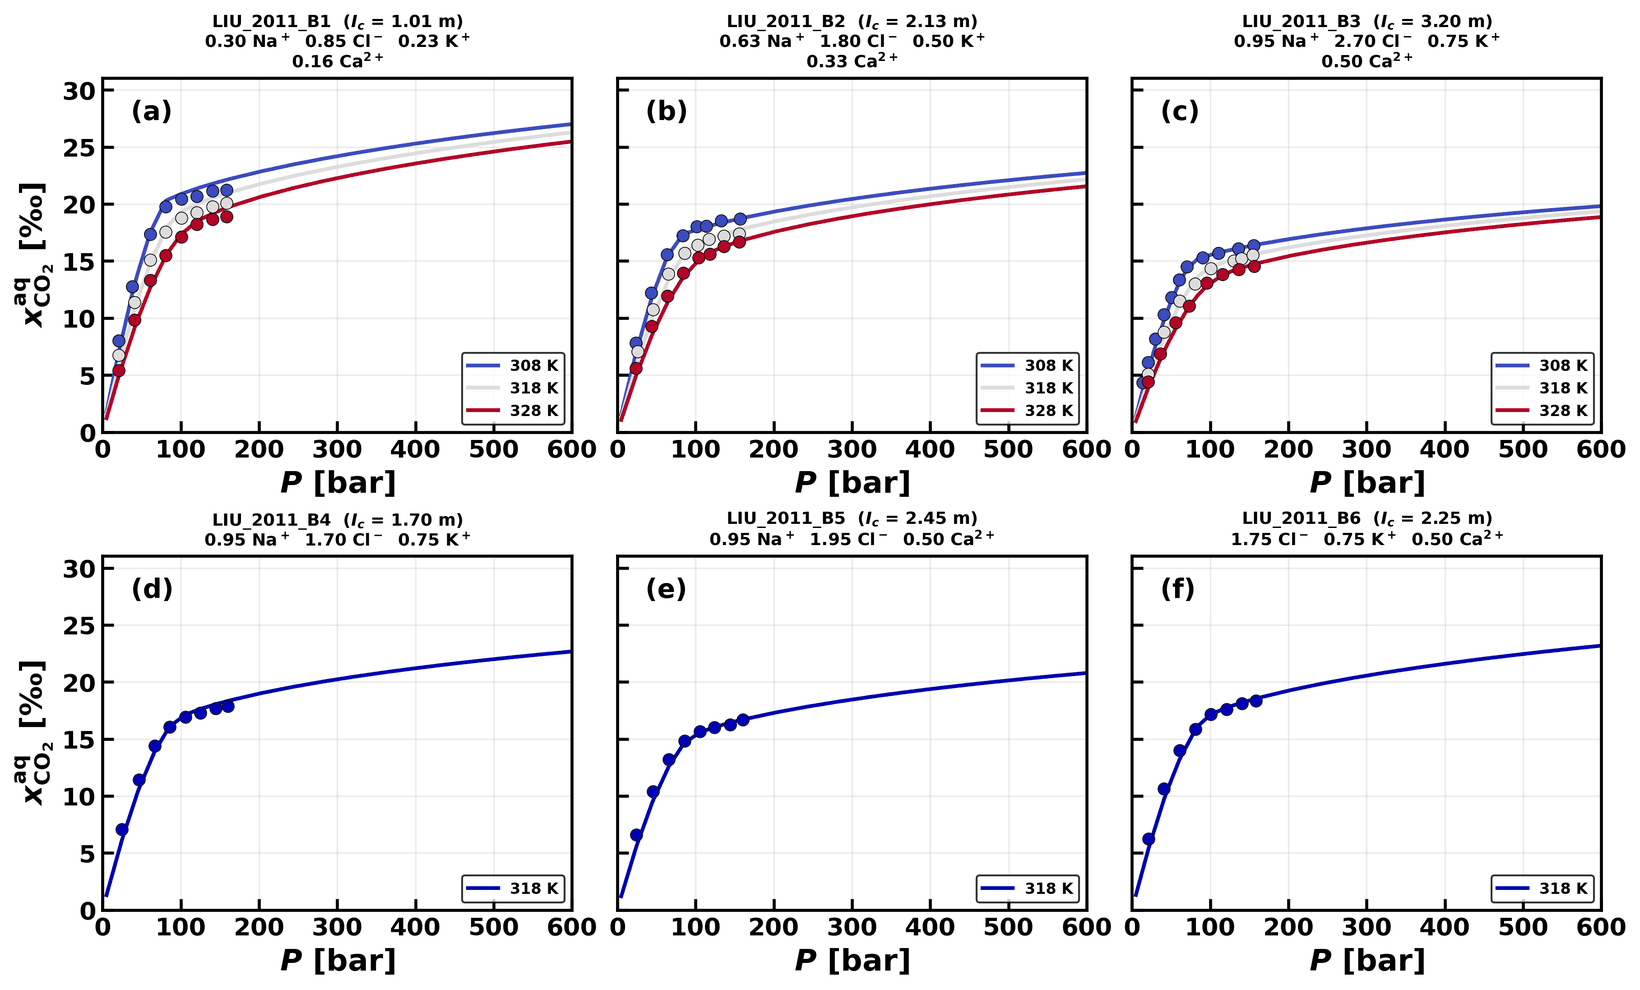

In [37]:
run('scripts/fig_co2_mixed_brines.py')
show('co2_mixed_brines_SI_LIU_2011.png')


<a id="sfigS19"></a>

**Figure S19.** $\mathrm{CO_{2}}$ solubility in mixed brines from ms-eCPA (continuous lines) versus the six Liu et al.<sup>[65](#sref65)</sup> brines (B1–B6), one panel per brine recipe.

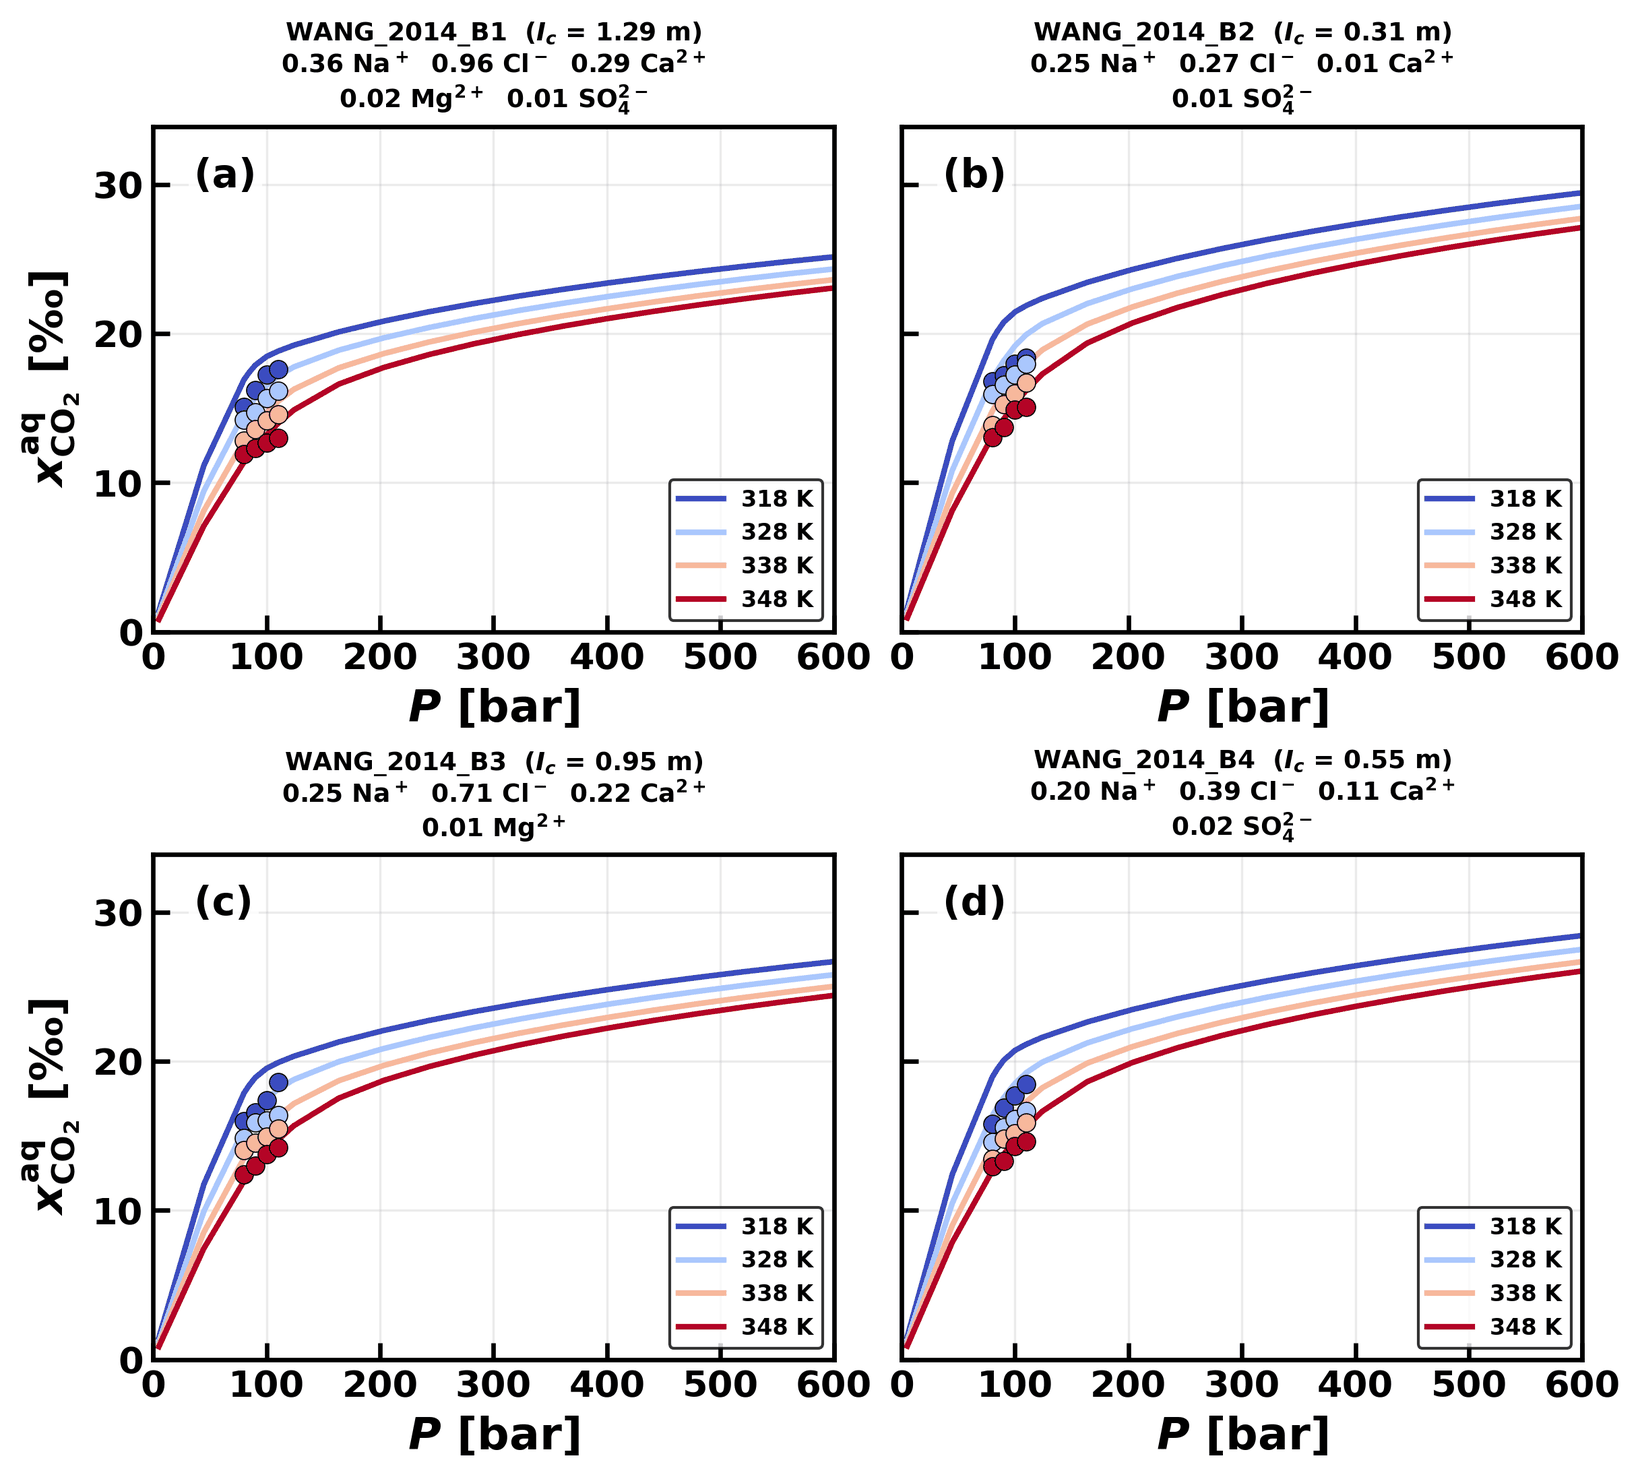

In [38]:
run('scripts/fig_co2_mixed_brines.py')
show('co2_mixed_brines_SI_WANG_2014.png')


<a id="sfigS20"></a>

**Figure S20.** $\mathrm{CO_{2}}$ solubility in mixed brines from ms-eCPA (continuous lines) versus the four Wang et al.<sup>[66](#sref66)</sup> brines (B1–B4).

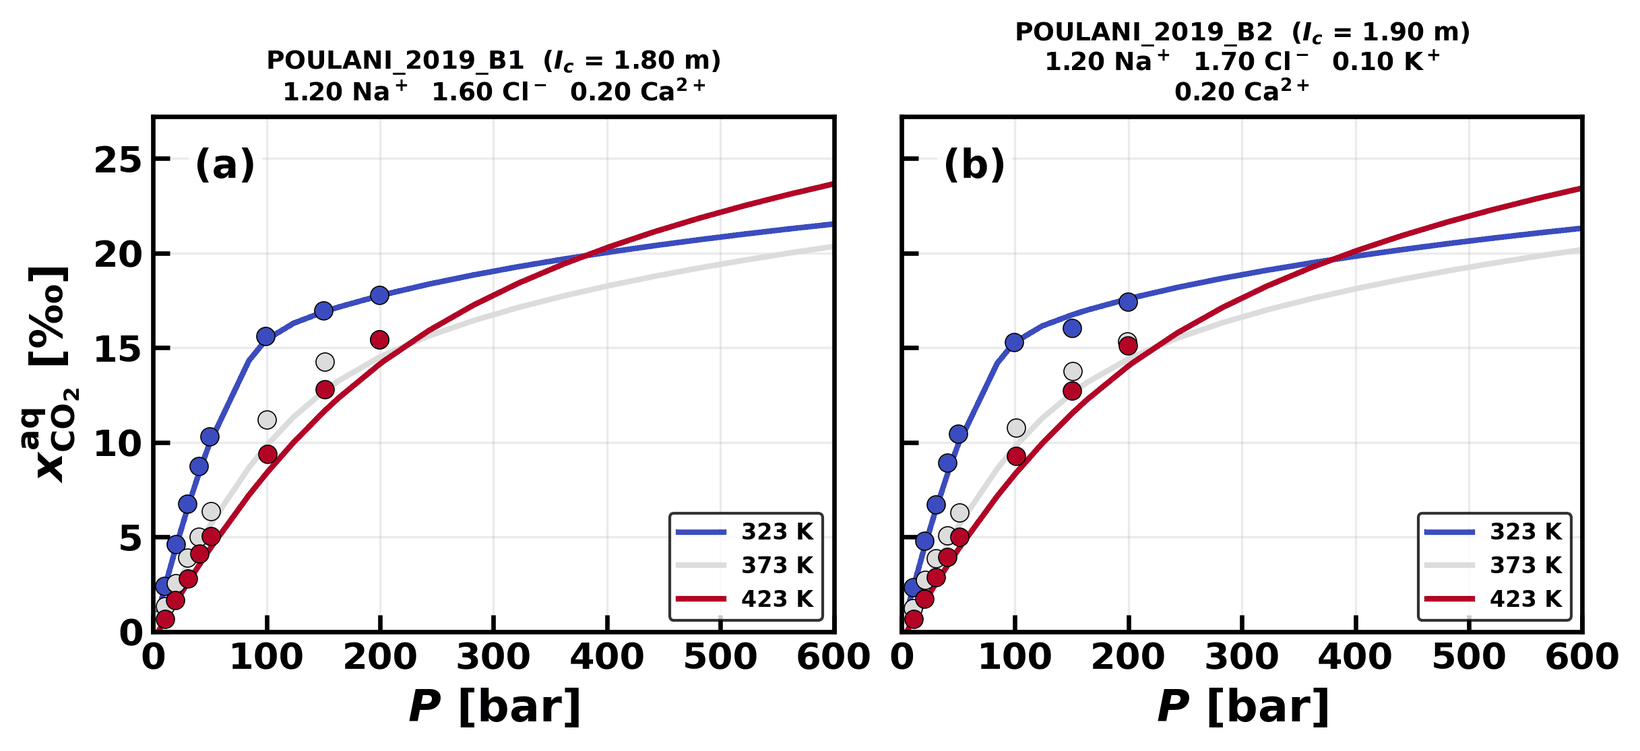

In [39]:
run('scripts/fig_co2_mixed_brines.py')
show('co2_mixed_brines_SI_POULANI_2019.png')


<a id="sfigS21"></a>

**Figure S21.** $\mathrm{CO_{2}}$ solubility in mixed brines from ms-eCPA (continuous lines) versus the two Poulain et al.<sup>[67](#sref67)</sup> brines.

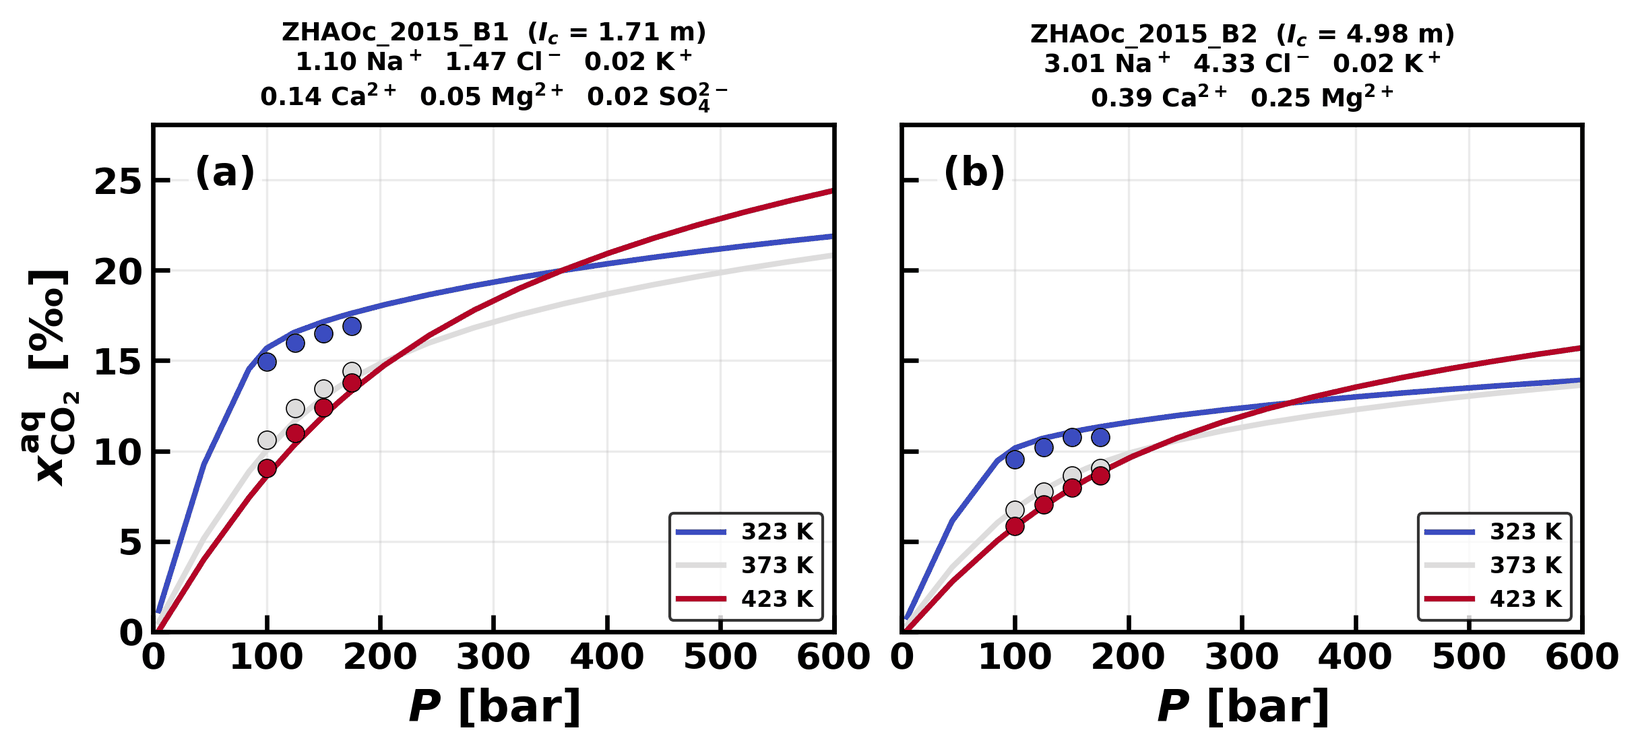

In [40]:
run('scripts/fig_co2_mixed_brines.py')
show('co2_mixed_brines_SI_ZHAOc_2015.png')


<a id="sfigS22"></a>

**Figure S22.** $\mathrm{CO_{2}}$ solubility in mixed brines from ms-eCPA (continuous lines) versus the two Zhao et al.<sup>[68](#sref68)</sup> brines.

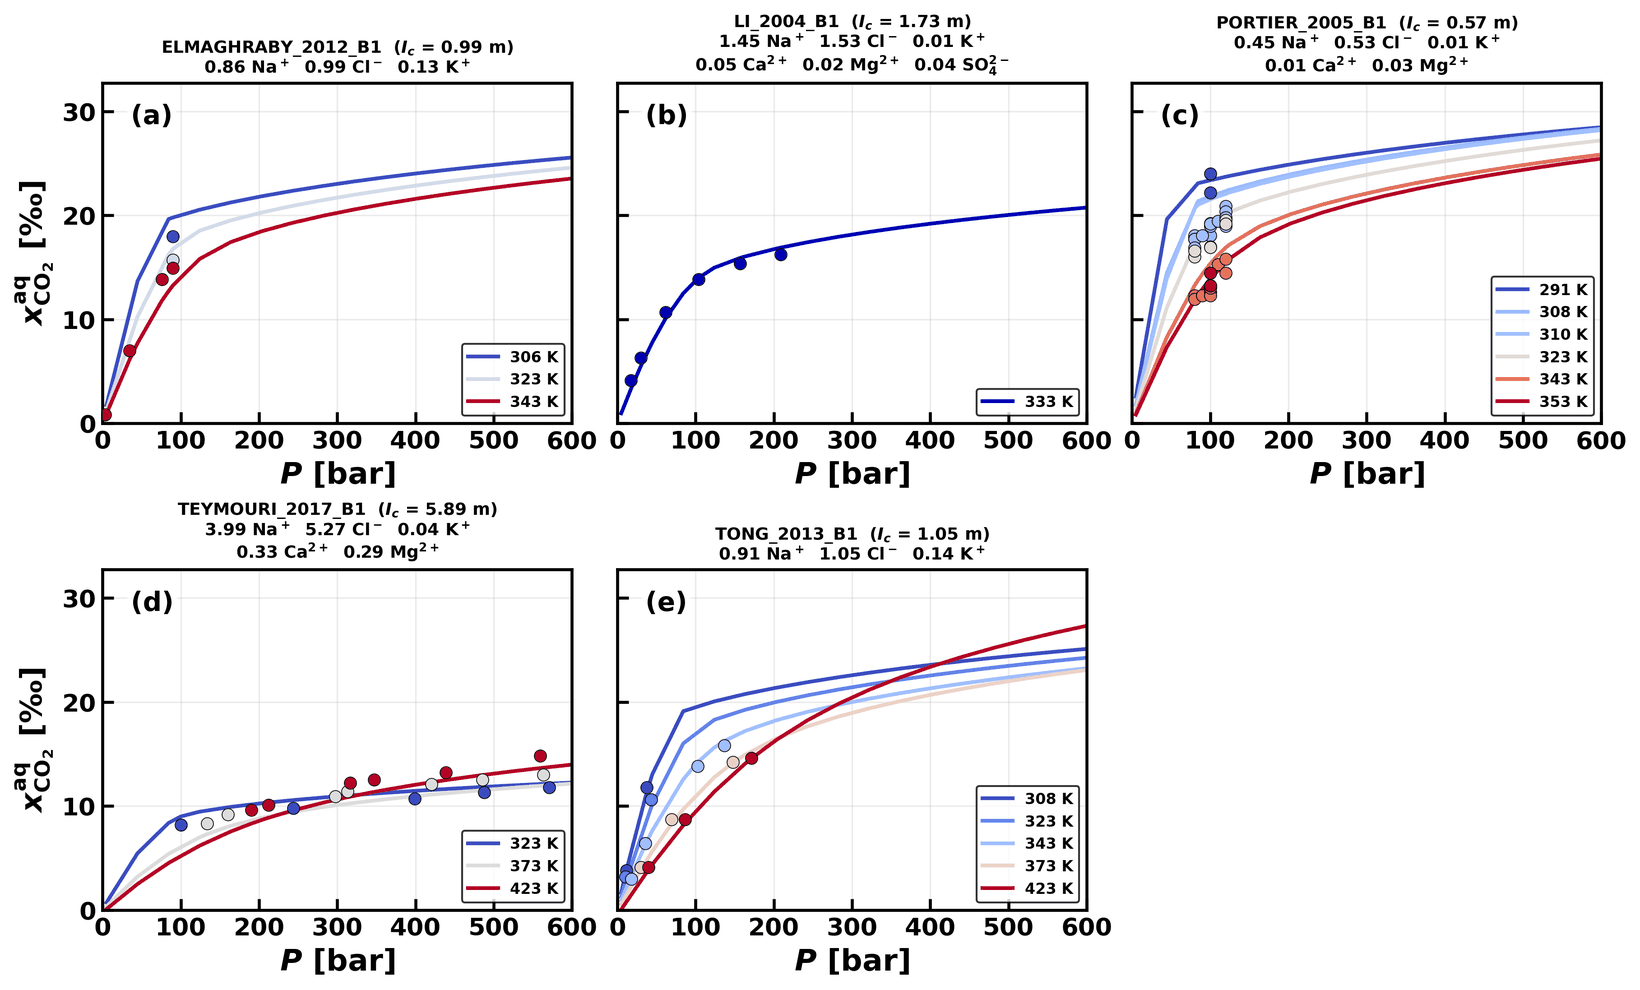

In [41]:
run('scripts/fig_co2_mixed_brines.py')
show('co2_mixed_brines_SI_other.png')


<a id="sfigS23"></a>

**Figure S23.** $\mathrm{CO_{2}}$ solubility in mixed brines from ms-eCPA (continuous lines) versus the single-brine datasets of El-Maghraby et al.<sup>[69](#sref69)</sup>, Li et al.<sup>[70](#sref70)</sup>, Portier and Rochelle<sup>[71](#sref71)</sup>, Mousavi et al.<sup>[72](#sref72)</sup>, and Tong et al.<sup>[22](#sref22)</sup>.

<a id="ssecS9_5"></a>

### S9.5 Henry’s-constant figures

The $\mathrm{CH_{4}}$ Henry’s-constant comparison of Fig. S24 complements the salt-free $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ validation of Section 3.3 (Fig. 3 of the main text) and the single-salt validation of Section 3.5 (Fig. 5 of the main text): the pure-water and $\mathrm{NaCl}$-brine panels overlay literature data, while the panels for the five remaining salts ($\mathrm{KCl}$, $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$, $\mathrm{Na_{2}SO_{4}}$, $\mathrm{MgSO_{4}}$) are model-only summaries of the salting-out trend captured by the ion-specific parameterization. The figure ties the salt-free absorption regime back to the high-salinity $\mathrm{CH_{4}}$-in-brine sections.


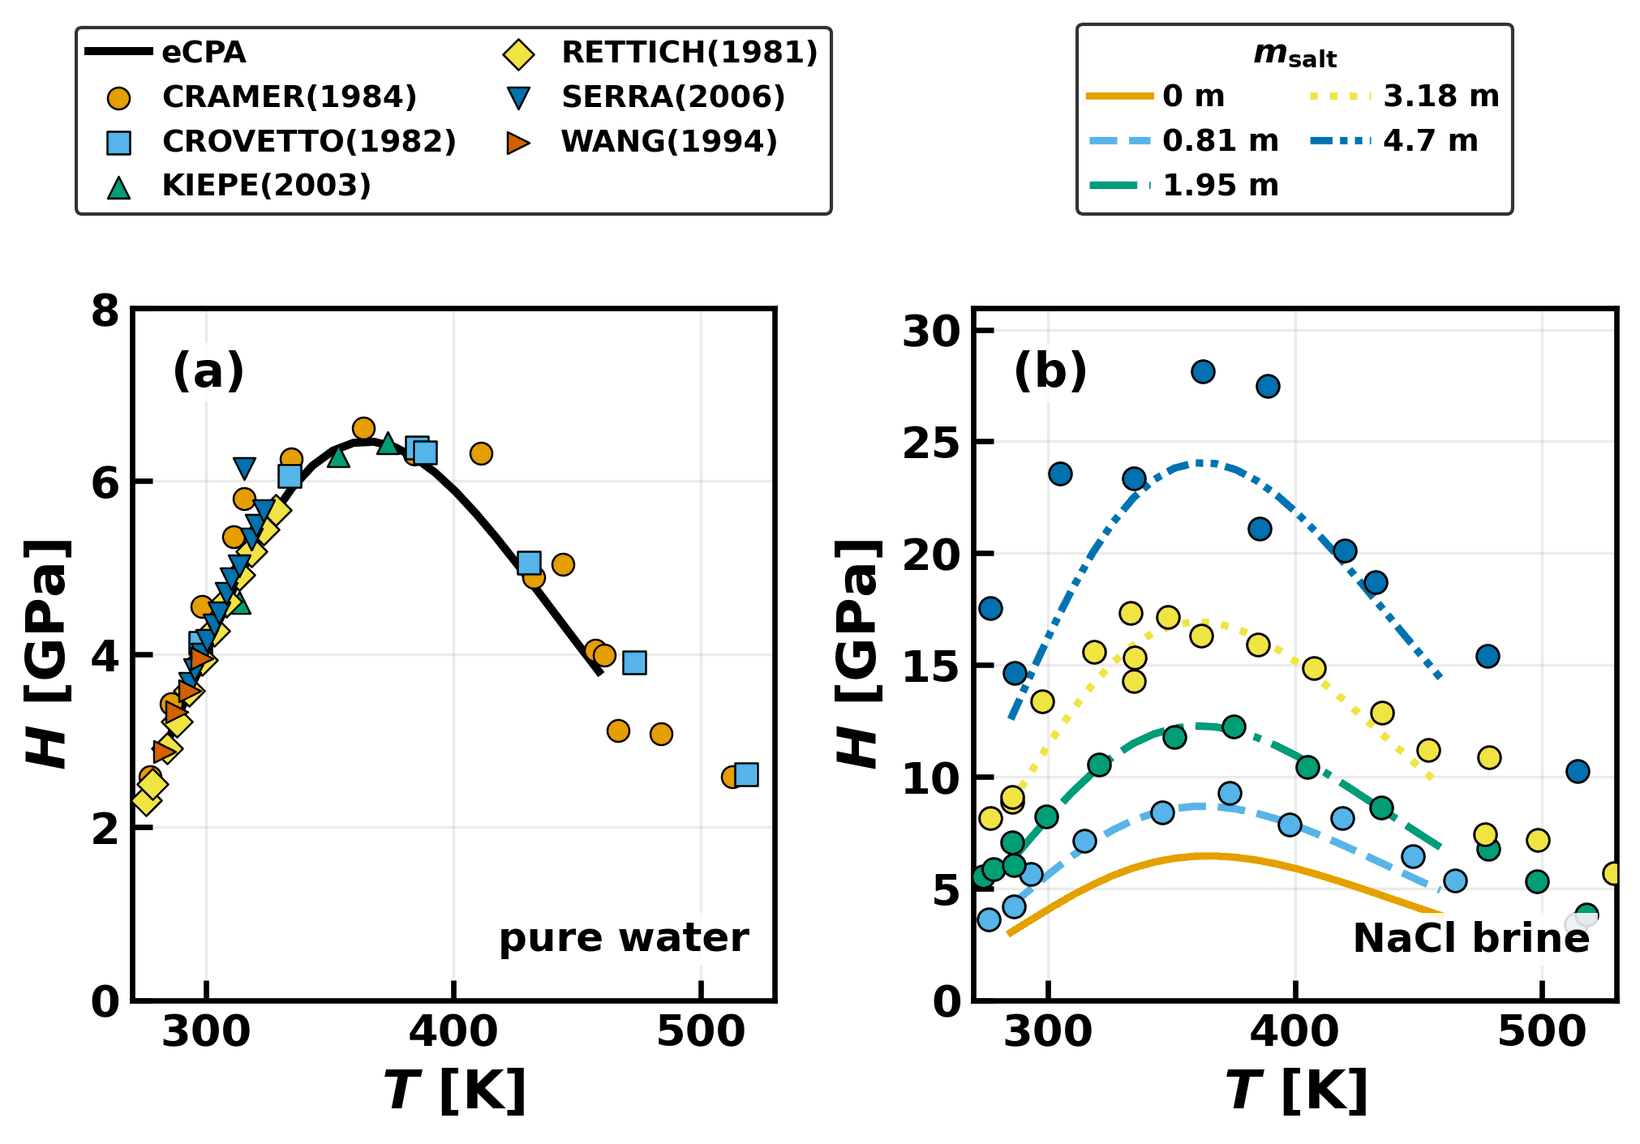

In [42]:
run('scripts/fig_ch4_henry.py')
show('henry_water_brine_SI.png')


<a id="sfigS24"></a>

**Figure S24.** $\mathrm{CH_{4}}$ Henry’s constant from ms-eCPA (continuous lines) compared with literature data<sup>[34](#sref34),[52](#sref52),[73](#sref73)–[76](#sref76)</sup> (discrete symbols) in pure water and in single-salt brines. The pure-water and $\mathrm{NaCl}$-brine panels include experimental literature comparisons.

<a id="ssecS9_6"></a>

### S9.6 Predicted $\mathrm{CH_{4}}$ and $\mathrm{CO_{2}}$–$\mathrm{CH_{4}}$ behavior in mixed-brine recipes

No mixed-salt $\mathrm{CH_{4}}$ solubility data and no $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–brine mutual-solubility data are available to us, so the entries below are predictions, not validations. For each of the nineteen recipes of Section S9.4, Table S13 compares the ion-specific ms-eCPA prediction with a $\mathrm{NaCl}$ brine of the same ionic strength $I_c$, and Table S14 repeats that comparison over each recipe’s own measured temperature–pressure window. Both columns of each pair are computed the same way: a two-phase stability test and flash on a feed of 30 mol % gas whose water-free $\mathrm{CO_{2}}$–$\mathrm{CH_{4}}$ ratio is equimolar, with the brine composition of the recipe (or its equal-$I_c$ $\mathrm{NaCl}$ surrogate) held at the prepared molalities. The equilibrium vapor stays close to the feed ratio, $y_{\mathrm{CO_{2}}} = 0.484$–$0.500$ on a water-free basis, at every state. $m_{\mathrm{CH_{4}}}$ and $m_{\mathrm{CO_{2}}}$ are aqueous molalities (mol per kg of water, $M_{\mathrm{H_{2}O}} = 18.01528$ g mol$^{-1}$) and $S = x_{\mathrm{CO_{2}}}/x_{\mathrm{CH_{4}}}$ is the aqueous ratio of the two dissolved gases. All 1,008 stability tests and flashes performed for this subsection returned a converged two-phase result.

Three statements hold at every one of the 295 measured states, not only at the reference condition: the $\mathrm{CH_{4}}$ deviation is positive, it exceeds the $\mathrm{CO_{2}}$ deviation in magnitude, and $\Delta S$ is negative. The $\mathrm{CO_{2}}$ deviation is the weaker of the two and is not one-signed — it lies between $0.3$ and $18.9$ % up to 373 K but turns slightly negative at 423 K in four recipes, to $-2.9$ %, so at the hot end the two gases respond to the same brine in opposite directions and the effect on selectivity is larger, not smaller. The comparison is set by the brine rather than by the assumed feed: at the reference condition, varying the total gas fraction between 10 and 50 mol % moves any deviation below by at most 1.3 percentage points, and varying the water-free $\mathrm{CO_{2}}$ fraction between 10 and 90 % moves it by at most 2.0 points ($\Delta S$ by at most 0.3).


<a id="stabS13"></a>

**Table S13.** ms-eCPA prediction for the nineteen mixed-brine recipes at 323 K and 100 bar, 30 mol % gas feed at an equimolar water-free $\mathrm{CO_{2}}$–$\mathrm{CH_{4}}$ ratio, against an equal-ionic-strength $\mathrm{NaCl}$ brine. Predictions, not validations. Percentages are computed from the unrounded molalities.

In [43]:
import json
import pandas as pd

SOURCES = {"LIU_2011": "Liu et al. (2011)", "WANG_2014": "Wang et al. (2014)",
           "POULANI_2019": "Poulain et al. (2019)", "ZHAOc_2015": "Zhao et al. (2015)",
           "ELMAGHRABY_2012": "El-Maghraby et al. (2012)", "LI_2004": "Li et al. (2004)",
           "PORTIER_2005": "Portier and Rochelle (2005)",
           "TEYMOURI_2017": "Mousavi et al. (2024)",      # same brine as Teymouri (2017)
           "TONG_2013": "Tong et al. (2013)"}
def recipe(mix_id):
    src, b = mix_id.rsplit("_", 1)
    return SOURCES[src], b

def num(v, d=1):
    """A value as printed in the tables: integers above 10 bar, a minus sign."""
    t = f"{v:.0f}" if d is None else f"{v:.{d}f}"
    return t.replace("-", "−")

def rng(values, d=1):
    lo, hi = num(min(values), d), num(max(values), d)
    if lo == hi:
        return lo
    # a range that involves a negative number reads "−2.5 to −2.3"
    return f"{lo} to {hi}" if "−" in lo + hi else f"{lo}–{hi}"

def prange(values, half_up=False):
    lo, hi = min(values), max(values)
    whole = (lambda v: str(int(v + 0.5))) if half_up else (lambda v: f"{v:.0f}")
    f = lambda v: f"{v:.2g}" if v < 10 else whole(v)
    return f(lo) if f(lo) == f(hi) else f"{f(lo)}–{f(hi)}"

if nbtools.RUN_LONG:   # otherwise use the shipped results in results_cache/
    run("reproduce/mixed_brine_ch4_prediction.py")
res = json.load(open("results_cache/mixed_brine_ch4_prediction.json"))["recipes"]
order = sorted(res)          # the order of the published tables
rows = []
for k in order:
    r = res[k]["ref"]
    name, b = recipe(k)
    rows.append({"Recipe": f"{name} {b}", "I_c (m)": f"{res[k]['Ic']:.2f}",
                 "m_CH4": f"{r['m_ch4']:.4f}", "m_CH4 (NaCl)": f"{r['m_ch4_nacl']:.4f}",
                 "Δ (%)": num(r['d_ch4']), "m_CO2": f"{r['m_co2']:.3f}",
                 "m_CO2 (NaCl)": f"{r['m_co2_nacl']:.3f}", "Δ (%) ": num(r['d_co2']),
                 "ΔS (%)": num(r['d_S'])})
show_table(pd.DataFrame(rows))


Recipe,I_c (m),m_CH4,m_CH4 (NaCl),Δ (%),m_CO2,m_CO2 (NaCl),Δ (%),ΔS (%)
El-Maghraby et al. (2012) B1,0.99,0.0339,0.0326,3.8,0.478,0.472,1.3,−2.4
Liu et al. (2011) B1,1.01,0.0372,0.0324,14.8,0.499,0.470,6.0,−7.6
Liu et al. (2011) B2,2.13,0.0301,0.0233,29.3,0.432,0.389,11.3,−13.9
Liu et al. (2011) B3,3.20,0.0254,0.0179,41.6,0.385,0.333,15.5,−18.4
Liu et al. (2011) B4,1.70,0.0319,0.0263,21.4,0.445,0.417,6.8,−12.0
Liu et al. (2011) B5,2.45,0.0259,0.0215,20.5,0.406,0.370,9.8,−8.9
Liu et al. (2011) B6,2.25,0.0333,0.0226,47.3,0.449,0.382,17.6,−20.2
Li et al. (2004) B1,1.73,0.0270,0.0260,3.9,0.420,0.414,1.4,−2.4
Portier and Rochelle (2005) B1,0.57,0.0387,0.0378,2.5,0.519,0.514,1.0,−1.4
Poulain et al. (2019) B1,1.80,0.0276,0.0255,8.3,0.426,0.410,4.0,−3.9


<a id="stabS14"></a>

**Table S14.** The same comparison over each recipe’s own measured temperature–pressure window, rather than at one condition. $N_{TP}$ is the number of distinct $(T, P)$ states at which that recipe’s $\mathrm{CO_{2}}$ solubility was measured; the last three columns give the range of the deviation from the equal-$I_c$ $\mathrm{NaCl}$ surrogate over those states. Every one of the 295 states returned a converged two-phase result for both brines.

In [44]:
import json
import pandas as pd

SOURCES = {"LIU_2011": "Liu et al. (2011)", "WANG_2014": "Wang et al. (2014)",
           "POULANI_2019": "Poulain et al. (2019)", "ZHAOc_2015": "Zhao et al. (2015)",
           "ELMAGHRABY_2012": "El-Maghraby et al. (2012)", "LI_2004": "Li et al. (2004)",
           "PORTIER_2005": "Portier and Rochelle (2005)",
           "TEYMOURI_2017": "Mousavi et al. (2024)",      # same brine as Teymouri (2017)
           "TONG_2013": "Tong et al. (2013)"}
def recipe(mix_id):
    src, b = mix_id.rsplit("_", 1)
    return SOURCES[src], b

def num(v, d=1):
    """A value as printed in the tables: integers above 10 bar, a minus sign."""
    t = f"{v:.0f}" if d is None else f"{v:.{d}f}"
    return t.replace("-", "−")

def rng(values, d=1):
    lo, hi = num(min(values), d), num(max(values), d)
    if lo == hi:
        return lo
    # a range that involves a negative number reads "−2.5 to −2.3"
    return f"{lo} to {hi}" if "−" in lo + hi else f"{lo}–{hi}"

def prange(values, half_up=False):
    lo, hi = min(values), max(values)
    whole = (lambda v: str(int(v + 0.5))) if half_up else (lambda v: f"{v:.0f}")
    f = lambda v: f"{v:.2g}" if v < 10 else whole(v)
    return f(lo) if f(lo) == f(hi) else f"{f(lo)}–{f(hi)}"

if nbtools.RUN_LONG:   # otherwise use the shipped results in results_cache/
    run("reproduce/mixed_brine_ch4_prediction.py")
res = json.load(open("results_cache/mixed_brine_ch4_prediction.json"))["recipes"]
order = sorted(res)          # the order of the published tables
rows = []
for k in order:
    w = res[k]["window"]
    name, b = recipe(k)
    rows.append({"Recipe": f"{name} {b}", "N_TP": len(w),
                 "T (K)": rng([x["T"] for x in w], None), "P (bar)": prange([x["P"] for x in w]),
                 "Δm_CH4 (%)": rng([x["d_ch4"] for x in w]),
                 "Δm_CO2 (%)": rng([x["d_co2"] for x in w]),
                 "ΔS (%)": rng([x["d_S"] for x in w])})
show_table(pd.DataFrame(rows))


Recipe,N_TP,T (K),P (bar),Δm_CH4 (%),Δm_CO2 (%),ΔS (%)
El-Maghraby et al. (2012) B1,6,306–343,3.4–90,3.6–3.8,1.2,−2.5 to −2.3
Liu et al. (2011) B1,24,308–328,21–158,14.1–15.3,5.4–7.0,−7.8 to −6.9
Liu et al. (2011) B2,24,308–328,24–157,28.1–30.1,10.2–13.3,−14.3 to −12.6
Liu et al. (2011) B3,27,308–328,13–156,39.9–42.6,14.0–18.0,−18.9 to −16.7
Liu et al. (2011) B4,8,318,25–160,20.8–21.4,6.6–6.9,−11.9 to −11.8
Liu et al. (2011) B5,8,318,25–160,19.9–21.5,10.0–10.9,−8.7 to −8.3
Liu et al. (2011) B6,8,318,21–159,45.7–48.4,17.5–18.9,−19.9 to −19.4
Li et al. (2004) B1,6,333,18–209,3.6–3.9,1.1–1.4,−2.5 to −2.4
Portier and Rochelle (2005) B1,16,291–353,80–120,2.3–2.6,0.9–1.1,−1.7 to −1.2
Poulain et al. (2019) B1,24,323–423,10–199,3.0–8.6,−2.9 to 4.2,−5.8 to −3.7


<a id="srefs"></a>

## References (Supporting Information)

<a id="sref1"></a>1. Moortgat, J.; Coelho, F. M.; Firoozabadi, A. Phase Equilibria of $\mathrm{CO_{2}}$, $\mathrm{CH_{4}}$, $\mathrm{N_{2}}$, $\mathrm{H_{2}}$, $\mathrm{C_{2}H_{6}}$, $\mathrm{C_{3}H_{8}}$, and Mixtures in Multisalt Brines: Robust Stability and Flash Computations with an Ion-Specific Electrolyte Cubic-Plus-Association Equation of State. *Energy Fuels* **2026**, available online. [DOI: 10.1021/acs.energyfuels.6c04569](https://pubs.acs.org/enfuem/article/doi/10.1021/acs.energyfuels.6c04569/5462396/Phase-Equilibria-of-CO2-CH4-N2-H2-C2H6-C3H8-and)

<a id="sref2"></a>2. Tsivintzelis, I.; Kontogeorgis, G. M.; Michelsen, M. L.; Stenby, E. H. Modeling phase equilibria for acid gas mixtures using the CPA equation of state. Part II: Binary mixtures with $\mathrm{CO_{2}}$. *Fluid Phase Equilibr.* **2011**, *306*, 38–56

<a id="sref3"></a>3. Coelho, F. M.; Mercier Franco, L. F.; Firoozabadi, A. Phase Equilibria of $\mathrm{CO_{2}}$–Water and $\mathrm{CO_{2}}$–Brine at High Temperatures: From Monte Carlo Simulations to the Equation of State. *Industrial & Engineering Chemistry Research* **2025**, *64*, 8492–8505

<a id="sref4"></a>4. Maribo-Mogensen, B.; Kontogeorgis, G. M.; Thomsen, K. Modeling of Dielectric Properties of Aqueous Salt Solutions with an Equation of State. *J. Phys. Chem. B* **2013**, *117*, 10523–10533

<a id="sref5"></a>5. Schlaikjer, A.; Thomsen, K.; Kontogeorgis, G. M. eCPA: An ion-specific approach to parametrization. *Fluid Phase Equilibria* **2018**, *470*, 176–187

<a id="sref6"></a>6. Al Ghafri, S.; Maitland, G. C.; Trusler, J. P. M. Densities of Aqueous $\mathrm{MgCl_{2}}$(aq), $\mathrm{CaCl_{2}}$(aq), KI(aq), NaCl(aq), KCl(aq), $\mathrm{AlCl_{3}}$(aq), and (0.964 NaCl + 0.136 KCl)(aq) at Temperatures Between (283 and 472) K, Pressures up to 68.5 MPa, and Molalities up to 6 mol·kg$^{–1}$. *J. Chem. Eng. Data* **2012**, *57*, 1288–1304

<a id="sref7"></a>7. Al Ghafri, S. Z.; Maitland, G. C.; Trusler, J. P. M. Densities of $\mathrm{SrCl_{2}}$(aq), $\mathrm{Na_{2}SO_{4}}$(aq), $\mathrm{NaHCO_{3}}$(aq), and Two Synthetic Reservoir Brines at Temperatures between (298 and 473) K, Pressures up to 68.5 MPa, and Molalities up to 3 mol·kg–1. *Journal of Chemical & Engineering Data* **2013**, *58*, 402–412

<a id="sref8"></a>8. Maribo-Mogensen, B.; Thomsen, K.; Kontogeorgis, G. M. An electrolyte CPA equation of state for mixed solvent electrolytes. *AIChE J.* **2015**, *61*, 2933–2950

<a id="sref10"></a>10. Koschel, D.; Coxam, J.-Y.; Rodier, L.; Majer, V. Enthalpy and solubility data of $\mathrm{CO_{2}}$ in water and NaCl(aq) at conditions of interest for geological sequestration. *Fluid Phase Equilibr.* **2006**, *247*, 107–120

<a id="sref11"></a>11. Messabeb, H.; Contamine, F.; Cézac, P.; Serin, J. P.; Gaucher, E. C. Experimental Measurement of $\mathrm{CO_{2}}$ Solubility in Aqueous NaCl Solution at Temperature from 323.15 to 423.15 K and Pressure of up to 20 MPa. *J. Chem. Eng. Data* **2016**, *61*, 3573–3584

<a id="sref12"></a>12. Teymouri, M. Held-out validation data set; single-author dataset spanning approximately 283 to 423 kelvin and 28 to 572 bar across six salts; held out from the main-paper AARE headline because the high-pressure tail extrapolates beyond the OPT=7 calibration range and the low-pressure points show a systematic offset toward lower $\mathrm{CO_{2}}$ solubility relative to other authors

<a id="sref13"></a>13. Yan, W.; Huang, S.; Stenby, E. H. Measurement and modeling of $\mathrm{CO_{2}}$ solubility in NaCl brine and CO2–saturated NaCl brine density. *Int. J. Greenh. Gas Cont.* **2011**, *5*, 1460–1477

<a id="sref14"></a>14. Zhao, H.; Fedkin, M. V.; Dilmore, R. M.; Lvov, S. N. Carbon dioxide solubility in aqueous solutions of sodium chloride at geological conditions: Experimental results at 323.15, 373.15, and 423.15K and 150bar and modeling up to 573.15K and 2000bar. *Geochim. Cosmochim. Ac.* **2015**, *149*, 165–189

<a id="sref15"></a>15. Guo, H.; Huang, Y.; Chen, Y.; Zhou, Q. Quantitative Raman Spectroscopic Measurements of $\mathrm{CO_{2}}$ Solubility in NaCl Solution from (273.15 to 473.15) K at p = (10.0, 20.0, 30.0, and 40.0) MPa. *J. Chem. Eng. Data* **2016**, *61*, 466–474

<a id="sref16"></a>16. Savary, V.; Berger, G.; Dubois, M.; Lacharpagne, J.-C.; Pages, A.; Thibeau, S.; Lescanne, M. The solubility of $\mathrm{CO_{2}}$+$\mathrm{H_{2}S}$ mixtures in water and 2M NaCl at 120°C and pressures up to 35MPa. *Int. J. Greenh. Gas Cont.* **2012**, *10*, 123–133

<a id="sref17"></a>17. Takenouchi, S.; Kennedy, G. C. The solubility of carbon dioxide in NaCl solutions at high temperatures and pressures. *Am. J. Sci.* **1965**, *263*, 445–454

<a id="sref18"></a>18. Zhao, H.; Dilmore, R. M.; Lvov, S. N. Experimental studies and modeling of CO2 solubility in high temperature aqueous $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$, $\mathrm{Na_{2}SO_{4}}$, and KCl solutions. *AIChE Journal* **2015**, *61*, 2286–2297

<a id="sref19"></a>19. Kamps, A. P. S.; Meyer, E.; Rumpf, B.; Maurer, G. Solubility of $\mathrm{CO_{2}}$ in Aqueous Solutions of KCl and in Aqueous Solutions of $\mathrm{K_{2}CO_{3}}$. *Journal of Chemical & Engineering Data* **2007**, *52*, 817–832

<a id="sref20"></a>20. Bastami, A.; Allahgholi, M.; Pourafshary, P. Experimental and modelling study of the solubility of $\mathrm{CO_{2}}$ in various $\mathrm{CaCl_{2}}$ solutions at different temperatures and pressures. *Pet. Sci.l* **2014**, *11*, 569–577

<a id="sref21"></a>21. Prutton, C. F.; Savage, R. L. The Solubility of Carbon Dioxide in Calcium Chloride-Water Solutions at 75, 100, 120 °C and High Pressures. *Journal of the American Chemical Society* **1945**, *67*, 1550–1554

<a id="sref22"></a>22. Tong, D.; Trusler, J. P. M.; Vega-Maza, D. Solubility of CO2 in Aqueous Solutions of $\mathrm{CaCl_{2}}$ or $\mathrm{MgCl_{2}}$ and in a Synthetic Formation Brine at Temperatures up to 423 K and Pressures up to 40 MPa. *Journal of Chemical & Engineering Data* **2013**, *58*, 2116–2124

<a id="sref23"></a>23. F. dos Santos, P.; André, L.; Ducousso, M.; Contamine, F.; Cézac, P. Experimental Measurements of $\mathrm{CO_{2}}$ Solubility in Aqueous $\mathrm{MgCl_{2}}$ Solution at Temperature between 323.15 and 423.15 K and Pressure up to 20 MPa. *Journal of Chemical & Engineering Data* **2021**, *66*, 4166–4173

<a id="sref24"></a>24. Corti, H. R.; Krenzer, M. E.; De Pablo, J. J.; Prausnitz, J. M. Effect of a dissolved gas on the solubility of an electrolyte in aqueous solution. *Industrial & Engineering Chemistry Research* **1990**, *29*, 1043–1050

<a id="sref25"></a>25. Rumpf, B.; Maurer, G. An Experimental and Theoretical Investigation on the Solubility of Carbon Dioxide in Aqueous Solutions of Strong Electrolytes. *Berichte der Bunsengesellschaft für physikalische Chemie* **1993**, *97*, 85–97

<a id="sref26"></a>26. dos Santos, P. F.; André, L.; Ducousso, M.; Contamine, F.; Cézac, P. Experimental Measurement of $\mathrm{CO_{2}}$ Solubility in Aqueous $\mathrm{Na_{2}SO_{4}}$ Solution at Temperatures between 303.15 and 423.15 K and Pressures up to 20 MPa. *Journal of Chemical & Engineering Data* **2020**, *65*, 3230–3239

<a id="sref27"></a>27. Chapoy, A.; Mohammadi, A. H.; Richon, D.; Tohidi, B. Gas solubility measurement and modeling for methane–water and methane–ethane–n-butane–water systems at low temperature conditions. *Fluid Phase Equilibria* **2004**, *220*, 113–121

<a id="sref28"></a>28. Lekvam, K.; Bishnoi, P. Dissolution of methane in water at low temperatures and intermediate pressures. *Fluid Phase Equilibria* **1997**, *131*, 297–309

<a id="sref29"></a>29. Ou, W.; Geng, L.; Lu, W.; Guo, H.; Qu, K.; Mao, P. Quantitative Raman spectroscopic investigation of geo-fluids high-pressure phase equilibria: Part II. Accurate determination of CH4 solubility in water from 273 to 603K and from 5 to 140MPa and refining the parameters of the thermodynamic model. *Fluid Phase Equilibria* **2015**, *391*, 18–30

<a id="sref30"></a>30. Chapoy, A.; Mohammadi, A. H.; Tohidi, B.; Richon, D. Estimation of Water Content for Methane + Water and Methane + Ethane + n-Butane + Water Systems Using a New Sampling Device. *Journal of Chemical & Engineering Data* **2005**, *50*, 1157–1161

<a id="sref31"></a>31. Böttger, A.; Álvaro Pérez-Salado Kamps; Maurer, G. An experimental investigation of the phase equilibrium of the binary system (methane+water) at low temperatures: Solubility of methane in water and three-phase (vapour+liquid+hydrate) equilibrium. *Fluid Phase Equilibria* **2016**, *407*, 209–216

<a id="sref32"></a>32. Chapoy, A.; Coquelet, C.; Richon, D. Solubility measurement and modeling of water in the gas phase of the methane/water binary system at temperatures from 283.08 to 318.12 K and pressures up to 34.5MPa. *Fluid Phase Equilibria* **2003**, *214*, 101–117

<a id="sref33"></a>33. Frost, M.; Karakatsani, E.; von Solms, N.; Richon, D.; Kontogeorgis, G. M. Vapor–Liquid Equilibrium of Methane with Water and Methanol. Measurements and Modeling. *Journal of Chemical & Engineering Data* **2014**, *59*, 961–967

<a id="sref34"></a>34. Wang, Y.; Han, B.; Yan, H.; Liu, R. Solubility of $\mathrm{CH_{4}}$ in the mixed solvent t-butyl alcohol and water. *Thermochimica Acta* **1995**, *253*, 327–334

<a id="sref35"></a>35. Wang, L.-K.; Chen, G.-J.; Han, G.-H.; Guo, X.-Q.; Guo, T.-M. Experimental study on the solubility of natural gas components in water with or without hydrate inhibitor. *Fluid Phase Equilibria* **2003**, *207*, 143–154

<a id="sref36"></a>36. Addicks, J.; Owren, G. A.; Fredheim, A. O.; Tangvik, K. Solubility of Carbon Dioxide and Methane in Aqueous Methyldiethanolamine Solutions. *Journal of Chemical & Engineering Data* **2002**, *47*, 855–860

<a id="sref37"></a>37. Awan, J. A.; Thomsen, K.; Coquelet, C.; Fosbol, P. L.; Richon, D. Vapor-Liquid Equilibrium Measurements and Modeling of the Propyl Mercaptan + Methane + Water System. *Journal of Chemical & Engineering Data* **2010**, *55*, 842–846

<a id="sref38"></a>38. Carroll, J. J.; Jou, F.-Y.; Mather, A. E.; Otto, F. D. The solubility of methane in aqueous solutions of monoethanolamine, diethanolamine and triethanolamine. *The Canadian Journal of Chemical Engineering* **1998**, *76*, 945–951

<a id="sref39"></a>39. Culberson, O.; Horn, A. B.; McKetta, J., J.J. Phase Equilibria in Hydrocarbon-Water Systems. *Journal of Petroleum Technology* **1950**, *2*, 1–6

<a id="sref40"></a>40. Duffy, J.; Smith, N. O.; Nagy, B. Solubility of natural gases in aqueous salt solutions—I: Liquidus surfaces in the system $\mathrm{CH_{4}}$-$\mathrm{H_{2}O}$-NaCl-$\mathrm{CaCl_{2}}$ at room temperatures and at pressures below 1000 psia. *Geochimica et Cosmochimica Acta* **1961**, *24*, 23–31

<a id="sref41"></a>41. Kim, Y. S.; Ryu, S. K.; Yang, S. O.; Lee, C. S. Liquid Water-Hydrate Equilibrium Measurements and Unified Predictions of Hydrate-Containing Phase Equilibria for Methane, Ethane, Propane, and Their Mixtures. *Industrial & Engineering Chemistry Research* **2003**, *42*, 2409–2414

<a id="sref42"></a>42. Michels, A.; Gerver, J.; Bijl, A. The influence of pressure on the solubility of gases. *Physica* **1936**, *3*, 797–808

<a id="sref43"></a>43. Sachs, W.; Meyn, V. Pressure and temperature dependence of the surface tension in the system natural gas/water principles of investigation and the first precise experimental data for pure methane/water at 25°C up to 46.8 MPa. *Colloids and Surfaces A: Physicochemical and Engineering Aspects* **1995**, *94*, 291–301

<a id="sref44"></a>44. Stoessell, R. K.; Byrne, P. A. Salting-out of methane in single-salt solutions at 25°C and below 800 psia. *Geochimica et Cosmochimica Acta* **1982**, *46*, 1327–1332

<a id="sref45"></a>45. Susak, N.; McGee, K. A. *A routine for estimating the solubility of methane in pure water or NaCl brines by using the Texas Instruments TI-59 calculator*; Technical Report 80-371, 1980

<a id="sref46"></a>46. Yang, S.; Cho, S.; Lee, H.; Lee, C. Measurement and prediction of phase equilibria for water + methane in hydrate forming conditions. *Fluid Phase Equilibria* **2001**, *185*, 53–63

<a id="sref47"></a>47. Yokoyama, C.; Wakana, S.; Kaminishi, G.; Takahashi, S. Vapor-liquid equilibria in the methane-diethylene glycol-water system at 298.15 and 323.15 K. *Journal of Chemical & Engineering Data* **1988**, *33*, 274–276

<a id="sref48"></a>48. Siqueira Campos, C. E. P.; Penello, J. R.; Pellegrini Pessoa, F. L.; Cohen Uller, A. M. Experimental Measurement and Thermodynamic Modeling for the Solubility of Methane in Water and Hexadecane. *Journal of Chemical & Engineering Data* **2010**, *55*, 2576–2580

<a id="sref49"></a>49. Amirijafari, B.; Campbell, J. M. Solubility of Gaseous Hydrocarbon Mixtures in Water. *Society of Petroleum Engineers Journal* **1972**, *12*, 21–27

<a id="sref50"></a>50. Olds, R. H.; Sage, B. H.; Lacey, W. N. Phase Equilibria in Hydrocarbon Systems.Composition of the Dew-Point Gas of the Methane-Water System. *Industrial & Engineering Chemistry* **1942**, *34*, 1223–1227

<a id="sref51"></a>51. Yarrison, M.; Cox, K. R.; Chapman, W. G. Measurement and Modeling of the Solubility of Water in Supercritical Methane and Ethane from 310 to 477 K and Pressures from 3.4 to 110 MPa. *Industrial & Engineering Chemistry Research* **2006**, *45*, 6770–6777

<a id="sref52"></a>52. Kiepe, J.; Horstmann, S.; Fischer, K.; Gmehling, J. Experimental Determination and Prediction of Gas Solubility Data for Methane + Water Solutions Containing Different Monovalent Electrolytes. *Industrial & Engineering Chemistry Research* **2003**, *42*, 5392–5398

<a id="sref53"></a>53. Gao, J.; Zheng, D.-Q.; Guo, T.-M. Solubilities of Methane, Nitrogen, Carbon Dioxide, and a Natural Gas Mixture in Aqueous Sodium Bicarbonate Solutions under High Pressure and Elevated Temperature. *Journal of Chemical & Engineering Data* **1997**, *42*, 69–73

<a id="sref54"></a>54. O’Sullivan, T. D.; Smith, N. O. Solubility and partial molar volume of nitrogen and methane in water and in aqueous sodium chloride from 50 to 125 C and 100 to 600 atm. *The Journal of Physical Chemistry* **1970**, *74*, 1460–1466

<a id="sref55"></a>55. Qin, J.; Rosenbauer, R. J.; Duan, Z. Experimental Measurements of Vapor–Liquid Equilibria of the $\mathrm{H_{2}O}$ + $\mathrm{CO_{2}}$ + $\mathrm{CH_{4}}$ Ternary System. *Journal of Chemical & Engineering Data* **2008**, *53*, 1246–1249

<a id="sref56"></a>56. Sultanov, R.; Skripka, V.; Namiot, A. Y. Solubility of methane in water at high temperatures and pressures. *Gazova Promyshlennost* **1972**, *17*, 6–7

<a id="sref57"></a>57. Price, L. C. Aqueous Solubility of Methane at Elevated Pressures and Temperatures1. *AAPG Bulletin* **1979**, *63*, 1527–1533

<a id="sref58"></a>58. Blanco C., L. H.; Smith, N. O. The high pressure solubility of methane in aqueous calcium chloride and aqueous tetraethylammonium bromide. Partial molar properties of dissolved methane and nitrogen in relation to water structure. *The Journal of Physical Chemistry* **1978**, *82*, 186–191

<a id="sref59"></a>59. Marcus, Y. Ionic radii in aqueous solutions. *Chemical Reviews* **1988**, *88*, 1475–1498

<a id="sref60"></a>60. Shannon, R. D. Revised effective ionic radii and systematic studies of interatomic distances in halides and chalcogenides. *Acta Crystallographica Section A* **1976**, *32*, 751–767

<a id="sref61"></a>61. Held, C.; Cameretti, L. F.; Sadowski, G. Modeling aqueous electrolyte solutions: Part 1. Fully dissociated electrolytes. *Fluid Phase Equilibria* **2008**, *270*, 87–96

<a id="sref62"></a>62. Rashin, A. A.; Honig, B. Reevaluation of the Born model of ion hydration. *The Journal of Physical Chemistry* **1985**, *89*, 5588–5593

<a id="sref63"></a>63. Pyper, N. C.; Pike, C. G.; Edwards, P. P. The polarizabilities of species present in ionic solutions. *Molecular Physics* **1992**, *76*, 353–372

<a id="sref64"></a>64. Pitzer, K. S.; Mayorga, G. Thermodynamics of electrolytes. II. Activity and osmotic coefficients for strong electrolytes with one or both ions univalent. *The Journal of Physical Chemistry* **1973**, *77*, 2300–2308

<a id="sref65"></a>65. Liu, Y.; Hou, M.; Yang, G.; Han, B. Solubility of $\mathrm{CO_{2}}$ in aqueous solutions of NaCl, KCl, $\mathrm{CaCl_{2}}$ and their mixed salts at different temperatures and pressures. *J. Supercrit. Fluid.* **2011**, *56*, 125–129

<a id="sref66"></a>66. Wang, L.; Shen, Z.; Hu, L.; Yu, Q. Modeling and measurement of $\mathrm{CO_{2}}$ solubility in salty aqueous solutions and application in the Erdos Basin. *Fluid Phase Equilibria* **2014**, *377*, 45–55

<a id="sref67"></a>67. Poulain, M.; Messabeb, H.; Lach, A.; Contamine, F.; Cézac, P.; Serin, J.-P.; Dupin, J.-C.; Martinez, H. Experimental Measurements of Carbon Dioxide Solubility in Na–Ca–K–Cl Solutions at High Temperatures and Pressures up to 20 MPa. *Journal of Chemical & Engineering Data* **2019**, *64*, 2497–2503

<a id="sref68"></a>68. Zhao, H.; Dilmore, R.; Allen, D. E.; Hedges, S. W.; Soong, Y.; Lvov, S. N. Measurement and Modeling of $\mathrm{CO_{2}}$ Solubility in Natural and Synthetic Formation Brines for $\mathrm{CO_{2}}$ Sequestration. *Environmental Science & Technology* **2015**, *49*, 1972–1980

<a id="sref69"></a>69. El-Maghraby, R.; Pentland, C.; Iglauer, S.; Blunt, M. A fast method to equilibrate carbon dioxide with brine at high pressure and elevated temperature including solubility measurements. *The Journal of Supercritical Fluids* **2012**, *62*, 55–59

<a id="sref70"></a>70. Li, Z.; Dong, M.; Li, S.; Dai, L. Densities and Solubilities for Binary Systems of Carbon Dioxide + Water and Carbon Dioxide + Brine at 59 °C and Pressures to 29 MPa. *Journal of Chemical & Engineering Data* **2004**, *49*, 1026–1031

<a id="sref71"></a>71. Portier, S.; Rochelle, C. Modelling $\mathrm{CO_{2}}$ solubility in pure water and NaCl-type waters from 0 to 300 °C and from 1 to 300 bar: Application to the Utsira Formation at Sleipner. *Chemical Geology* **2005**, *217*, 187–199, Geochemical Aspects of CO2 sequestering

<a id="sref72"></a>72. Mousavi, R.; Chapoy, A.; Burgass, R. $\mathrm{CO_{2}}$ solubility in aqueous solution of salts: Experimental study and thermodynamic modelling. *Greenhouse Gases: Science and Technology* **2024**, *14*, 791–828

<a id="sref73"></a>73. Cramer, S. D. Solubility of methane in brines from 0 to 300 C. *Industrial & Engineering Chemistry Process Design and Development* **1984**, *23*, 533–538

<a id="sref74"></a>74. Crovetto, R.; Fernández‐Prini, R.; Japas, M. L. Solubilities of inert gases and methane in $\mathrm{H_{2}O}$ and in $\mathrm{\text{D}2O}$ in the temperature range of 300 to 600 K. *The Journal of Chemical Physics* **1982**, *76*, 1077–1086

<a id="sref75"></a>75. Rettich, T. R.; Handa, Y. P.; Battino, R.; Wilhelm, E. Solubility of gases in liquids. 13. High-precision determination of Henry’s constants for methane and ethane in liquid water at 275 to 328 K. *The Journal of Physical Chemistry* **1981**, *85*, 3230–3237

<a id="sref76"></a>76. Serra, M. C. C.; Pessoa, F.; Palavra, A. Solubility of methane in water and in a medium for the cultivation of methanotrophs bacteria. *The Journal of Chemical Thermodynamics* **2006**, *38*, 1629–1633

<a id="sref77"></a>77. Bando, S.; Takemura, F.; Nishio, M.; Hihara, E.; Akai, M. Solubility of CO$_2$ in Aqueous Solutions of NaCl at (30 to 60) °C and (10 to 20) MPa. *Journal of Chemical & Engineering Data* **2003**, *48*, 576–579

<a id="sref78"></a>78. Chabab, S.; Théveneau, P.; Corvisier, J.; Coquelet, C.; Paricaud, P.; Houriez, C.; Ahmar, E.E. Thermodynamic study of the $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$–NaCl system: Measurements of $\mathrm{CO_{2}}$ solubility and modeling of phase equilibria using Soreide and Whitson, electrolyte CPA and SIT models. *Int. J. Greenh. Gas Cont.* **2019**, *91*, 102825

<a id="sref79"></a>79. Chabab, S.; Ahmadi, P.; Théveneau, P.; Coquelet, C.; Chapoy, A.; Corvisier, J.; Paricaud, P. Measurements and Modeling of High-Pressure O2 and CO2 Solubility in Brine (H2O + NaCl) between 303 and 373 K and Pressures up to 36 MPa. *Journal of Chemical & Engineering Data* **2021**, *66*, 609–620

<a id="sref80"></a>80. Hou, S.; Maitland, G.C.; Trusler, J.P.M. Measurement and modeling of the phase behavior of the (carbon dioxide+water) mixture at temperatures from 298.15K to 448.15K. *J. Supercrit. Fluid.* **2013**, *73*, 87–96

<a id="sref81"></a>81. Hou, S.; Maitland, G.C.; Trusler, J.P.M. Phase equilibria of (CO2 + H2O + NaCl) and (CO2 + H2O + KCl): measurements and modeling. *The Journal of Supercritical Fluids* **2013**, *78*, 78–88

<a id="sref82"></a>82. Jacob, R.; Saylor, B.Z. CO$_2$ solubility in multi-component brines containing NaCl, KCl, CaCl$_2$ and MgCl$_2$ at 297 K and 1–14 MPa. *Chemical Geology* **2016**, *424*, 86–95

<a id="sref83"></a>83. Kiepe, J.; Horstmann, S.; Fischer, K.; Gmehling, J. Experimental Determination and Prediction of Gas Solubility Data for CO$_2$ + H$_2$O Mixtures Containing NaCl or KCl at Temperatures between 313 and 393 K and Pressures up to 10 MPa. *Industrial & Engineering Chemistry Research* **2002**, *41*, 4393–4398

<a id="sref84"></a>84. Liu, Y.; Panagiotopoulos, A.Z.; Debenedetti, P.G. Monte Carlo Simulations of High-Pressure Phase Equilibria of $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ Mixtures. *J. Phys. Chem. B* **2011**, *115*, 6629–6635

<a id="sref85"></a>85. Liu, B.; Mahmood, B.S.; Mohammadian, E.; Manshad, A.K.; Rosli, N.R.; Ostadhassan, M. Measurement of Solubility of CO$_2$ in NaCl, CaCl$_2$, MgCl$_2$ and MgCl$_2$ + CaCl$_2$ Brines at Temperatures from 298 to 373 K and Pressures up to 20 MPa Using the Potentiometric Titration Method. *Energies* **2021**, *14*, 7222

<a id="sref86"></a>86. Nighswander, J.A.; Kalogerakis, N.; Mehrotra, A.K. Solubilities of Carbon Dioxide in Water and 1 wt % NaCl Solution at Pressures up to 10 MPa and Temperatures from 80 to 200 °C. *Journal of Chemical & Engineering Data* **1989**, *34*, 355–360

<a id="sref87"></a>87. Rumpf, B.; Nicolaisen, H.; Öcal, C.; Maurer, G. Solubility of Carbon Dioxide in Aqueous Solutions of Sodium Chloride: Experimental Results and Correlation. *Journal of Solution Chemistry* **1994**, *23*, 431–448